# Solar filament segmentation

The default run loads the saved UNet3+ and proposal models and plots the checkpoint's validation split. Open the notebook from this folder using the project environment. On Kaggle, attach MAGFiLO and both model files. Set `DATASET_ROOT` or `MODEL_DIR` if discovery needs a path.

- **Validation** uses `train/train_images/` and the original COCO labels. `RUN_FRACTION=1` evaluates the full saved split.
- **Test CSV** is enabled with `WRITE_TEST_SUBMISSION=True`. For test-only inference, also set `RUN_VALIDATION_ANALYSIS=False`.
- **Custom weights** use `USE_BUNDLED_MODELS=False` and `SEGMENTER_PATH`, with either matching `PROPOSAL_WEIGHTS_PATH` or standard inference and optional `POSTPROCESS_PATH`. Providing no model paths in this mode enables the training stages.

The saved inference path selects image crops, normalizes grayscale pixels and averages the original and flipped model views. The proposal models use additional crop views and a center detector to rank candidate masks, then resolve shared pixels before scoring or export.

## Run configuration

In [ ]:
from pathlib import Path

RUN_VALIDATION_ANALYSIS = True
WRITE_TEST_SUBMISSION = False

USE_BUNDLED_MODELS = True
MODEL_DIR = None             # optional directory containing the two bundled checkpoints
SEGMENTER_PATH = None        # custom best_model.pth when USE_BUNDLED_MODELS is False
PROPOSAL_WEIGHTS_PATH = None # path to the matching proposals/weights-*.pt mini-model bundle
POSTPROCESS_PATH = None      # optional best_postprocess.json for standard inference
DATASET_ROOT = None          # MAGFiLO root containing train/ and/or test/
RUN_FRACTION = 1
RUN_SEED = 42

PROPOSAL_PRESET = "train"    # full pipeline only: "train" fits mini models; None uses standard segmentation
PROPOSAL_TRAINING_MINUTES = 45  # positive wall-clock budget for proposal preparation and fitting

## Pipeline setup

The bundled modules keep the notebook portable. Setup writes them to an importable package for this kernel and any training workers.

In [ ]:
PIPELINE_SOURCES = {
    '__init__.py': r'''"""End-to-end filament segmentation pipeline.

Stages (each module also runs as ``python -m pipeline.<module>``):

1. ``data``        dataset paths, annotations and the file-disjoint split
2. ``train``       UNet3Plus training on cached 256x256 tiles (``pipeline/cache.py``)
3. ``predict``     tile a full image, predict, stitch back to 2048x2048, split into filaments
4. ``submission``  pycocotools RLE counts, CSV writer and validator
5. ``evaluate``    local Panoptic Quality (the leaderboard metric) and threshold tuning

"""
''',
    'annotation_policy.py': r'''"""Training-only split/merge and low-agreement one-to-one annotation policy."""
from collections import defaultdict, Counter
from itertools import combinations
import copy
import hashlib
import json
import csv
import os
from pathlib import Path
import tempfile
import cv2
import numpy as np
from pycocotools import mask as mu

VERSION = 'ratio2-one-to-one-3px-v2'


def foreground_agreement_3px(a, b):
    """Symmetric foreground support within 3 native Euclidean pixels (EDA metric)."""
    # Crop decoded masks to avoid full-frame distance transforms per filament.
    boxes = np.asarray(mu.toBbox([a, b]))
    x0, y0 = np.floor(boxes[:, :2].min(axis=0)).astype(int)
    x1, y1 = np.ceil((boxes[:, :2] + boxes[:, 2:]).max(axis=0)).astype(int)
    masks = [mu.decode(r)[y0:y1, x0:x1].astype(bool) for r in (a, b)]
    supported = 0
    for source, target in (masks, masks[::-1]):
        distance = cv2.distanceTransform((~target).astype(np.uint8), cv2.DIST_L2,
                                         cv2.DIST_MASK_PRECISE)
        supported += int((distance[source] <= 3.000001).sum())
    total = sum(int(m.sum()) for m in masks)
    return supported / total if total else 1.


def _resolve_one_to_one(aa, rr, dids, areas, members, filename):
    """Resolve original low-agreement pairs; preserve unaffected third drawings."""
    if len(members) < 2 or len({dids[i] for i in members}) != len(members):
        return set(), [], []  # unmatched or any split/merge ambiguity
    replacements, scores = {}, []
    for i, j in combinations(members, 2):
        if not int(mu.area(mu.merge([rr[i], rr[j]], intersect=True))):
            continue
        score = foreground_agreement_3px(rr[i], rr[j])
        scores.append(score)
        if score >= .5 or areas[i] == areas[j]:
            continue  # Strictly below 50%; equal areas have no smaller annotation.
        smaller, larger = sorted((i, j), key=lambda k: areas[k])
        previous = replacements.get(larger)
        if previous is None or (areas[smaller], str(aa[smaller]['id'])) < (areas[previous], str(aa[previous]['id'])):
            replacements[larger] = smaller
    if not replacements:
        return set(), [], []
    group = hashlib.sha256('|'.join(sorted(str(aa[i]['id']) for i in members)).encode()).hexdigest()[:16]
    remove, additions, changed_pixels = set(), [], 0
    for larger, smaller in sorted(replacements.items()):
        while smaller in replacements:
            smaller = replacements[smaller]  # Strictly decreasing area prevents cycles.
        item = copy.deepcopy(aa[smaller])
        item['policy_origin_id'] = str(item['id'])
        item['id'] = 'policy1to1-' + hashlib.sha256(
            f'{VERSION}|{group}|{dids[larger]}|{item["id"]}'.encode()).hexdigest()[:32]
        item['image_id'] = aa[larger]['image_id']
        additions.append(item)
        remove.add(str(aa[larger]['id']))
        inter = int(mu.area(mu.merge([rr[larger], rr[smaller]], intersect=True)))
        changed_pixels += int(areas[larger] + areas[smaller] - 2 * inter)
    return remove, additions, [dict(file=filename, group=group,
        decision='one_to_one_smaller', drawings=len(members), original_annotations=len(members),
        original_ids=json.dumps(sorted(str(aa[i]['id']) for i in members)),
        min_foreground_3px=min(scores), changed_drawings=len(replacements),
        changed_pixels=changed_pixels)]


def _atomic_text(path, text):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode='w', encoding='utf-8', dir=path.parent, delete=False) as handle:
        temporary = Path(handle.name)
        handle.write(text)
    try:
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def prepare_training_annotations(annotation_path, train_files, cache_dir, policy='ratio2'):
    """Return an immutable, content-addressed annotation file for cache building.

    The cache sees changed training targets plus original validation targets.
    Original annotation files are never overwritten. Scope/version affect the
    derived JSON and cache hash even when no groups require replacement.
    """
    if policy not in ('none', 'ratio2'):
        raise ValueError('annotation policy must be none or ratio2')
    annotation_path = Path(annotation_path)
    source_bytes = annotation_path.read_bytes()
    original_sha = hashlib.sha256(source_bytes).hexdigest()
    train_files = sorted(set(train_files))
    scope_sha = hashlib.sha256(json.dumps(train_files).encode()).hexdigest()
    summary = dict(policy=policy, version=VERSION if policy == 'ratio2' else None,
                   original_annotation_sha256=original_sha, training_files_sha256=scope_sha,
                   training_files=len(train_files))
    if policy == 'none':
        return annotation_path, summary
    key = hashlib.sha256(json.dumps(summary, sort_keys=True).encode()).hexdigest()[:24]
    directory = Path(cache_dir)/'annotation_policy'/key
    prepared = directory/'annotations.json'
    manifest_path = directory/'manifest.json'
    audit_path = directory/'audit.csv'
    if manifest_path.exists() and prepared.exists() and audit_path.exists():
        manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
        if (all(manifest.get(k) == v for k, v in summary.items())
                and manifest.get('annotation_sha256') == hashlib.sha256(prepared.read_bytes()).hexdigest()
                and manifest.get('audit_sha256') == hashlib.sha256(audit_path.read_bytes()).hexdigest()):
            return prepared, manifest
        raise ValueError(f'Prepared annotation policy artifacts were changed: {directory}')
    coco = json.loads(source_bytes)
    known_files = {d['file_name'] for d in coco['images']}
    if not set(train_files) <= known_files:
        raise ValueError('Training scope contains unknown annotation filenames')
    transformed, audit = apply_policy(coco, train_files)
    transformed['annotation_policy']['training_files_sha256'] = scope_sha
    text = json.dumps(transformed, separators=(',', ':'), sort_keys=True)
    _atomic_text(prepared, text)
    import io
    buffer = io.StringIO(newline='')
    columns = sorted(set().union(*(row.keys() for row in audit))) if audit else [
        'file','group','decision','changed_drawings','changed_pixels']
    writer = csv.DictWriter(buffer, fieldnames=columns)
    writer.writeheader(); writer.writerows(audit)
    _atomic_text(audit_path, buffer.getvalue())
    summary.update(annotation_path=str(prepared.resolve()), audit_path=str(audit_path.resolve()),
        annotation_sha256=hashlib.sha256(prepared.read_bytes()).hexdigest(),
        audit_sha256=hashlib.sha256(audit_path.read_bytes()).hexdigest(),
        decisions=dict(Counter(row['decision'] for row in audit)),
        changed_pixel_events=sum(row['changed_pixels'] for row in audit),
        candidate_groups=len(audit))
    _atomic_text(manifest_path, json.dumps(summary, indent=2, sort_keys=True))
    return prepared, summary


def rle(annotation, height, width):
    segmentation = annotation['segmentation']
    if isinstance(segmentation, list):
        return mu.merge(mu.frPyObjects(segmentation, height, width))
    if isinstance(segmentation['counts'], list):
        return mu.frPyObjects(segmentation, height, width)
    result = dict(segmentation)
    if isinstance(result['counts'], str):
        result['counts'] = result['counts'].encode('ascii')
    return result


def apply_policy(coco, train_files, ratio_threshold=2., relation_fraction=.25, min_intersection=20):
    """Choose single below 2x, fragment set at/above 2x, only on train files.

    Build cross-drawing overlap components for a whole file, so no annotation is
    resolved twice. Three-rater components must agree on single-vs-fragments for
    every single/multiple pair. Otherwise leave the component untouched. If the
    agreed family has multiple candidate drawings, select the original mask set
    with highest mean union IoU to all participant drawings, then drawing ID.
    Replace the component in *each participating drawing* by the winning set.
    Keep per-drawing sample multiplicity; no union/bridge painting across raters.

    Additionally, isolated one-to-one overlap components use the original EDA
    3px foreground metric. Below 50%, replace only the larger mask by the smaller
    original mask in that drawing. A separate any-positive-overlap graph guards
    against splits/merges, including tiny fragments. Three-drawing decisions use
    original masks and resolve replacement chains toward decreasing area.
    """
    if ratio_threshold <= 0 or not 0 < relation_fraction <= 1 or min_intersection < 1:
        raise ValueError('Invalid policy thresholds')
    train_files = set(train_files)
    images = {str(d['id']): d for d in coco['images']}
    by_file = defaultdict(list)
    for annotation in coco['annotations']:
        if images[str(annotation['image_id'])]['file_name'] in train_files:
            by_file[images[str(annotation['image_id'])]['file_name']].append(annotation)
    remove, additions, audit = set(), [], []
    for filename, aa in sorted(by_file.items()):
        dids = [str(a['image_id']) for a in aa]
        if len(set(dids)) < 2:
            continue
        rr = [rle(a, images[did]['height'], images[did]['width']) for a, did in zip(aa, dids)]
        areas = np.asarray(mu.area(rr), dtype=float)
        parent = list(range(len(aa)))
        overlap_parent = list(range(len(aa)))
        def overlap_find(k):
            while overlap_parent[k] != k:
                overlap_parent[k] = overlap_parent[overlap_parent[k]]
                k = overlap_parent[k]
            return k
        def find(k):
            while parent[k] != k:
                parent[k] = parent[parent[k]]
                k = parent[k]
            return k
        for da, db in combinations(sorted(set(dids)), 2):
            ia = [i for i, did in enumerate(dids) if did == da]
            ib = [i for i, did in enumerate(dids) if did == db]
            iou = np.asarray(mu.iou([rr[i] for i in ia], [rr[i] for i in ib], [0]*len(ib)))
            inter = np.rint(iou*(areas[ia, None] + areas[ib][None, :])/(1+iou))
            for a, b in zip(*np.nonzero(inter >= 1)):
                overlap_parent[overlap_find(ia[a])] = overlap_find(ib[b])
            related = (inter >= min_intersection) & (inter >= relation_fraction*np.minimum(areas[ia, None], areas[ib][None, :]))
            for a, b in zip(*np.nonzero(related)):
                root_a, root_b = find(ia[a]), find(ib[b])
                parent[root_a] = root_b
        overlap_components = defaultdict(list)
        for i in range(len(aa)):
            overlap_components[overlap_find(i)].append(i)
        for members in overlap_components.values():
            removed, added, events = _resolve_one_to_one(aa, rr, dids, areas, members, filename)
            remove.update(removed)
            additions.extend(added)
            audit.extend(events)
        components = defaultdict(list)
        for i in range(len(aa)):
            components[find(i)].append(i)
        for members in components.values():
            parts = defaultdict(list)
            for i in members:
                parts[dids[i]].append(i)
            singles = sorted(d for d, ids in parts.items() if len(ids) == 1)
            fragments = sorted(d for d, ids in parts.items() if len(ids) > 1)
            if not singles or not fragments:
                continue  # One-to-one handled above; unmatched/many-to-many unchanged.
            unions = {d: mu.merge([rr[i] for i in ids]) for d, ids in parts.items()}
            union_areas = {d: int(mu.area(u)) for d, u in unions.items()}
            ratios = [union_areas[a]/union_areas[b] for a in singles for b in fragments]
            decisions = {'single' if ratio < ratio_threshold else 'fragments' for ratio in ratios}
            group = hashlib.sha256('|'.join(sorted(str(aa[i]['id']) for i in members)).encode()).hexdigest()[:16]
            row = dict(file=filename, group=group, drawings=len(parts),
                       original_annotations=len(members), min_ratio=min(ratios), max_ratio=max(ratios),
                       original_ids=json.dumps(sorted(str(aa[i]['id']) for i in members)))
            if len(decisions) > 1:
                audit.append({**row, 'decision': 'conflict_unchanged', 'changed_drawings': 0, 'changed_pixels': 0})
                continue
            decision = next(iter(decisions))
            family = singles if decision == 'single' else fragments
            participant_ids = sorted(parts)
            scores = {d: float(np.asarray(mu.iou([unions[d]], [unions[p] for p in participant_ids], [0]*len(parts))).mean())
                      for d in family}
            winner = min(family, key=lambda d: (-scores[d], d))
            chosen = parts[winner]
            chosen_ids = sorted(str(aa[i]['id']) for i in chosen)
            changed_drawings = changed_pixels = 0
            for did, ids in sorted(parts.items()):
                inter = int(mu.area(mu.merge([unions[did], unions[winner]], intersect=True)))
                change = union_areas[did] + union_areas[winner] - 2*inter
                changed_pixels += change
                changed_drawings += int(change > 0)
                remove.update(str(aa[i]['id']) for i in ids)
                for index in chosen:
                    item = copy.deepcopy(aa[index])
                    if str(item['image_id']) != did:
                        identity = f'{VERSION}|{group}|{did}|{item["id"]}'
                        item['policy_origin_id'] = str(item['id'])
                        item['id'] = 'policy2x-' + hashlib.sha256(identity.encode()).hexdigest()[:32]
                        item['image_id'] = did
                    additions.append(item)
            audit.append({**row, 'decision': decision, 'winner_drawing': winner,
                          'winning_ids': json.dumps(chosen_ids), 'winning_instances': len(chosen),
                          'changed_drawings': changed_drawings, 'changed_pixels': changed_pixels})
    result = copy.deepcopy(coco)
    result['annotations'] = [a for a in result['annotations'] if str(a['id']) not in remove] + additions
    ids = [str(a['id']) for a in result['annotations']]
    assert len(ids) == len(set(ids)), 'Policy generated duplicate annotation IDs'
    # Exact untouched-reference invariant, independent of list ordering.
    outside = lambda source: {str(a['id']): a for a in source['annotations']
                              if images[str(a['image_id'])]['file_name'] not in train_files}
    assert outside(result) == outside(coco), 'Policy modified a non-training annotation'
    assert result['images'] == coco['images']
    result['annotation_policy'] = dict(version=VERSION, ratio_threshold=ratio_threshold,
        relation_fraction=relation_fraction, min_intersection=min_intersection,
        one_to_one_min_shared_pixels=1, one_to_one_tolerance_px=3,
        one_to_one_agreement_threshold=.5, one_to_one_equal_area='unchanged',
        scope='selected_training_files_only', replacement='canonical_masks_in_each_participating_drawing')
    return result, audit
''',
    'bce_targets.py': r'''"""Separate cache for shared segmentation targets on multi-drawing fitting images."""
from contextlib import closing
from pathlib import Path
import sqlite3
import zlib

import cv2
import numpy as np
import torch

from pipeline.cache import CachedFilamentTileDataset, _rasterize_mask, _sample_rows
from pipeline.data import annotations_by_drawing, drawings_by_file, load_coco


LEGACY_DISPUTED_BCE_TARGETS = "disputed_bce_v1"
DISPUTED_BCE_TARGETS = "shared_segmentation_v2"


def shared_bce_target(first, second):
    """Return a native-resolution target in integer hundredths."""
    if first.shape != second.shape:
        raise ValueError("Drawings of a source image must have the same shape.")
    target = np.zeros(first.shape, dtype=np.uint8)
    target[(first != 0) & (second != 0)] = 100
    for own, other in ((first, second), (second, first)):
        disputed = (own != 0) & (other == 0)
        target[disputed] = 26
        if disputed.any() and other.any():
            distance = cv2.distanceTransform(1 - other, cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
            target[disputed & (distance <= 3)] = 47
    return target


def shared_segmentation_target(masks):
    """Use the same confidence map for every drawing of a source frame."""
    if len(masks) == 2:
        return shared_bce_target(*masks)
    votes = np.count_nonzero(masks, axis=0)
    return np.rint(100 * votes / len(masks)).astype(np.uint8)


def bce_cache_path(hard_cache_path, mode=DISPUTED_BCE_TARGETS):
    # The hard-cache identity covers prepared annotations, fitting drawing IDs,
    # rasterization, tile size and dense crop geometry.
    path = Path(hard_cache_path)
    return path.with_name(f"{path.stem}.{mode}.sqlite3")


def build_bce_cache(hard_cache_path, prepared_annotations, fitting_files, mode=DISPUTED_BCE_TARGETS):
    """Build targets once per hard-cache identity, committing the sidecar atomically."""
    path = bce_cache_path(hard_cache_path, mode)
    with closing(sqlite3.connect(path, timeout=600)) as connection, connection:
        connection.execute("BEGIN IMMEDIATE")
        if connection.execute("PRAGMA user_version").fetchone()[0] == 1:
            return path

        coco = load_coco(prepared_annotations)
        by_file = drawings_by_file(coco)
        annotations = annotations_by_drawing(coco)
        records = {str(record["id"]): record for record in coco["images"]}
        connection.execute("CREATE TABLE targets (sample_id TEXT PRIMARY KEY, target BLOB NOT NULL)")
        for filename in fitting_files:
            drawing_ids = by_file[filename]
            if len(drawing_ids) < 2 or (mode == LEGACY_DISPUTED_BCE_TARGETS and len(drawing_ids) != 2):
                continue
            selection = "AND has_filament = 1" if mode == LEGACY_DISPUTED_BCE_TARGETS else ""
            rows = list(_sample_rows(
                hard_cache_path, drawing_ids, "sample_id, y, x, height, width", selection
            ))
            if not rows:
                continue
            masks = [_rasterize_mask(records[d]["width"], records[d]["height"], annotations.get(d, ()))
                     for d in drawing_ids]
            target = shared_segmentation_target(masks)
            connection.executemany("INSERT INTO targets VALUES (?, ?)", (
                (tile_id, zlib.compress(target[y:y + h, x:x + w].tobytes(), level=1))
                for tile_id, y, x, h, w in rows if target[y:y + h, x:x + w].any()
            ))
        connection.execute("PRAGMA user_version = 1")
    return path


def load_bce_targets(path):
    """Load compact target blobs for reuse across epochs and DataLoader workers."""
    uri = f"{Path(path).resolve().as_uri()}?mode=ro"
    with closing(sqlite3.connect(uri, uri=True)) as connection:
        return dict(connection.execute("SELECT sample_id, target FROM targets"))


class DisputedBCETileDataset(CachedFilamentTileDataset):
    def __init__(self, cache_path, sample_ids, bce_targets, transform=None):
        super().__init__(cache_path, sample_ids)
        self.bce_targets = bce_targets
        self.paired_transform = transform

    def __getitem__(self, index):
        image, hard = super().__getitem__(index)
        blob = self.bce_targets.get(self.sample_ids[index])
        bce = hard
        if blob is not None:
            hundredths = np.frombuffer(zlib.decompress(blob), dtype=np.uint8).reshape(hard.shape)
            bce = torch.from_numpy(hundredths.copy()).float().div_(100)
        if self.paired_transform is not None:
            return self.paired_transform(image, hard, bce)
        return image, hard, bce
''',
    'bridge_postprocessing.py': r'''"""Connect nearby high-confidence chunks with locally supported low-threshold paths."""
import heapq
import math

import cv2
import numpy as np

from pipeline.inference_settings import bridge_settings


def candidate_bridges(probability, threshold=.65, max_gap=24, seed_min_area=25):
    """Return pairs and their probability-weighted local paths, before area filtering.

    Distance is Euclidean between closest foreground pixel centers. A path stays
    within a local box around those endpoints (half the gap plus two pixels of
    margin), so it cannot wander along an unrelated low-confidence structure.
    """
    high = probability >= threshold
    count, labels, stats, _ = cv2.connectedComponentsWithStats(high.astype('uint8'), 8)
    ids = np.flatnonzero(stats[:, cv2.CC_STAT_AREA] >= seed_min_area)
    ids = ids[ids != 0]
    boundaries = {}
    for i in ids:
        x, y, w, h, _ = stats[i]
        mask = (labels[y:y+h, x:x+w] == i).astype('uint8')
        edge = mask & ~cv2.erode(mask, np.ones((3, 3), 'uint8'), borderType=cv2.BORDER_CONSTANT, borderValue=0)
        points = np.argwhere(edge).astype('float32')
        points += (y, x)
        boundaries[i] = points
    pairs = []
    for a, i in enumerate(ids):
        xi, yi, wi, hi, _ = stats[i]
        for j in ids[a+1:]:
            xj, yj, wj, hj, _ = stats[j]
            dx = max(0, xi-(xj+wj-1), xj-(xi+wi-1))
            dy = max(0, yi-(yj+hj-1), yj-(yi+hi-1))
            if dx*dx+dy*dy > max_gap*max_gap:
                continue
            distances, indices = cv2.batchDistance(boundaries[i], boundaries[j], cv2.CV_32F, normType=cv2.NORM_L2, K=1)
            k = int(distances.argmin())
            distance = float(distances[k, 0])
            if distance <= max_gap:
                pairs.append((distance, tuple(boundaries[i][k].astype(int)),
                              tuple(boundaries[j][indices[k, 0]].astype(int)),
                              min(int(stats[i, 4]), int(stats[j, 4]))))
    return high, pairs


def supported_path(probability, start, end, low_threshold, max_gap):
    """Dijkstra path, favouring high probabilities and forbidding subthreshold pixels."""
    margin = int(math.ceil(max_gap / 2)) + 2
    y0, x0 = np.maximum(np.minimum(start, end)-margin, 0)
    y1, x1 = np.minimum(np.maximum(start, end)+margin+1, probability.shape)
    patch = probability[y0:y1, x0:x1]
    start = (start[0]-y0, start[1]-x0)
    end = (end[0]-y0, end[1]-x0)
    costs = np.full(patch.shape, np.inf)
    costs[start] = 0
    previous = {}
    queue = [(0., start)]
    while queue:
        cost, point = heapq.heappop(queue)
        if cost != costs[point]:
            continue
        if point == end:
            path = [point]
            while point != start:
                point = previous[point]
                path.append(point)
            return np.array(path) + (y0, x0)
        y, x = point
        for dy, dx in ((-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)):
            yy, xx = y+dy, x+dx
            if not (0 <= yy < patch.shape[0] and 0 <= xx < patch.shape[1]):
                continue
            if patch[yy, xx] < low_threshold:
                continue
            new = cost + (math.sqrt(2) if dy and dx else 1) / max(float(patch[yy, xx]), .01)
            if new < costs[yy, xx]:
                costs[yy, xx] = new
                previous[(yy, xx)] = (y, x)
                heapq.heappush(queue, (new, (yy, xx)))
    return None


def add_bridges(probability, high, paths, low_threshold, radius=2):
    bridge = np.zeros(high.shape, 'uint8')
    for path in paths:
        if path is not None:
            bridge[path[:, 0], path[:, 1]] = 1
    if radius:
        bridge = cv2.dilate(bridge, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*radius+1, 2*radius+1)))
    # Only the supported bridge difference is added; original chunks stay intact.
    return high | (bridge.astype(bool) & (probability >= low_threshold))


def filtered_labels(binary, min_area=475):
    count, labels, stats, _ = cv2.connectedComponentsWithStats(binary.astype('uint8'), 8)
    keep = stats[:, 4] >= min_area
    keep[0] = False
    mapping = np.zeros(count, 'int32')
    mapping[keep] = np.arange(1, int(keep.sum())+1)
    return mapping[labels], stats[keep, 4].astype('int64')


def probability_to_bridged_instances(probability, threshold=.65, min_area=475,
                                     low_threshold=.4, max_gap=24, seed_min_area=25,
                                     bridge_radius=2, path_box_margin=20):
    """Standalone inference entry point; uses no annotations or GT information.

    The margin default matches the experiment, whose path searches share a
    36-pixel search-gap setting (36/2+2 = 20 pixels of local margin).
    """
    config = dict(enabled=True, low_threshold=low_threshold, max_gap=max_gap,
                  seed_min_area=seed_min_area, bridge_radius=bridge_radius, path_box_margin=path_box_margin)
    binary = bridged_binary(probability, threshold, config)
    labels, areas = filtered_labels(binary, max(1, min_area))
    return [labels == j for j in range(1, len(areas)+1)]


def bridged_binary(probability, threshold, settings=None):
    """Add supported bridges before closing or final area filtering."""
    return next(bridge_variants(probability, threshold, [settings]))


def bridge_variants(probability, threshold, settings):
    """Yield masks while sharing pair detection and local paths during PQ tuning."""
    configs = [bridge_settings(config, threshold) for config in settings]
    active = [config for config in configs if config['enabled']]
    if active:
        high, pairs = candidate_bridges(probability, threshold, max(c['max_gap'] for c in active),
                                        min(c['seed_min_area'] for c in active))
    else:
        high, pairs = probability >= threshold, []
    cache = {}
    for config in configs:
        if not config['enabled']:
            yield high
            continue
        paths = []
        for i, pair in enumerate(pairs):
            if pair[0] > config['max_gap'] or pair[3] < config['seed_min_area']:
                continue
            key = (i, config['low_threshold'], config['path_box_margin'])
            if key not in cache:
                cache[key] = supported_path(probability, pair[1], pair[2], config['low_threshold'],
                                             2*(config['path_box_margin']-2))
            paths.append(cache[key])
        yield add_bridges(probability, high, paths, config['low_threshold'], config['bridge_radius'])
''',
    'cache.py': r'''"""Persistent, lazy tile cache for the MAGFiLO training data.

The SQLite database is both the manifest (sample_id -> row) and the payload store.
Only one source image/drawing is decoded while building (including its instance
masks for dense crop planning). Images store raw uint8 bytes; masks store COCO RLE counts
directly, without an additional compression layer, and decode per Dataset read.
"""

from __future__ import annotations

import hashlib
import json
import os
import sqlite3
from collections import defaultdict
from pathlib import Path
from typing import Callable, Iterable, Sequence

import numpy as np
import torch
from PIL import Image
from pycocotools import mask as mask_utils
from torch.utils.data import Dataset
from pipeline.crops import CROP_POLICY, DenseCropPlanner
from pipeline.data import annotations_by_drawing, drawings_by_file, load_gray

try:
    import cv2

    cv2.setNumThreads(0)
except ImportError:
    cv2 = None


CACHE_SCHEMA_VERSION = 1
DEFAULT_TILE_SIZE = 256
CODEC = "raw-uint8-image-coco-rle-mask-v1"
RASTERIZER = "pycocotools-coco-v1"
NEGATIVE_TILE_POLICY = {"min_disk_fraction": 0.8, "annotations": "all_original_drawings"}


def _sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def preprocessing_config(annotation_path: str | Path, tile_size: int = DEFAULT_TILE_SIZE,
                         *, dense_image_ids: Iterable[str] = ()) -> dict:
    """Return all metadata that changes the bytes stored in the cache."""
    annotation_path = Path(annotation_path)
    config = {
        "schema_version": CACHE_SCHEMA_VERSION,
        "annotation_sha256": _sha256_file(annotation_path),
        "tile_size": int(tile_size),
        "image_mode": "L",
        "image_dtype": "uint8",
        "mask_dtype": "uint8",
        "edge_policy": "drop_incomplete",
        "rasterizer": RASTERIZER,
        "codec": CODEC,
    }
    dense_ids = sorted(set(map(str, dense_image_ids)))
    if dense_ids:
        config['training_crops'] = {**CROP_POLICY, 'source_image_ids': dense_ids}
    return config


def config_hash(config: dict) -> str:
    encoded = json.dumps(config, sort_keys=True, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()


def default_cache_path(
    cache_dir: str | Path, annotation_path: str | Path, tile_size: int = DEFAULT_TILE_SIZE,
    *, dense_image_ids: Iterable[str] = (),
) -> Path:
    """Choose a deterministic cache filename for this annotation/configuration."""
    signature = config_hash(preprocessing_config(annotation_path, tile_size, dense_image_ids=dense_image_ids))[:16]
    return Path(cache_dir) / f"filament_tiles_{signature}.sqlite3"


def _sample_id(source_image_id: str, source_file: str, row: int, col: int, tile_size: int) -> str:
    identity = json.dumps(
        [str(source_image_id), source_file, int(row), int(col), int(tile_size)],
        separators=(",", ":"),
    ).encode("utf-8")
    return hashlib.sha256(identity).hexdigest()[:32]


def _source_key(source_image_id: str, source_file: str) -> str:
    identity = f"{source_image_id}\0{source_file}".encode("utf-8")
    return hashlib.sha256(identity).hexdigest()[:32]


def _connect_for_build(cache_path: Path) -> sqlite3.Connection:
    connection = sqlite3.connect(cache_path, timeout=60)
    connection.execute("PRAGMA journal_mode=WAL")
    connection.execute("PRAGMA synchronous=NORMAL")
    connection.execute("PRAGMA foreign_keys=ON")
    connection.executescript(
        """
        CREATE TABLE IF NOT EXISTS metadata (
            key TEXT PRIMARY KEY,
            value TEXT NOT NULL
        );
        CREATE TABLE IF NOT EXISTS sources (
            source_key TEXT PRIMARY KEY,
            source_image_id TEXT NOT NULL,
            source_file TEXT NOT NULL,
            width INTEGER NOT NULL,
            height INTEGER NOT NULL,
            source_size INTEGER NOT NULL,
            source_mtime_ns INTEGER NOT NULL,
            expected_tiles INTEGER NOT NULL,
            complete INTEGER NOT NULL CHECK (complete IN (0, 1))
        );
        CREATE TABLE IF NOT EXISTS samples (
            sample_id TEXT PRIMARY KEY,
            source_key TEXT NOT NULL REFERENCES sources(source_key) ON DELETE CASCADE,
            source_image_id TEXT NOT NULL,
            source_file TEXT NOT NULL,
            tile_row INTEGER NOT NULL,
            tile_col INTEGER NOT NULL,
            y INTEGER NOT NULL,
            x INTEGER NOT NULL,
            height INTEGER NOT NULL,
            width INTEGER NOT NULL,
            has_filament INTEGER NOT NULL,
            positive_pixels INTEGER NOT NULL,
            image_blob BLOB NOT NULL,
            mask_blob BLOB NOT NULL
        );
        CREATE INDEX IF NOT EXISTS samples_source_image_idx
            ON samples(source_image_id, tile_row, tile_col);
        CREATE INDEX IF NOT EXISTS samples_positive_idx
            ON samples(has_filament);
        """
    )
    return connection


def rasterize_segmentation(segmentation, height: int, width: int) -> np.ndarray:
    """Canonical COCO polygon/RLE mask; preserve fractional coordinates and holes."""
    if isinstance(segmentation, list):
        if not segmentation:
            return np.zeros((height, width), dtype=np.uint8)
        rle = mask_utils.merge(mask_utils.frPyObjects(segmentation, height, width))
    elif isinstance(segmentation["counts"], list):
        rle = mask_utils.frPyObjects(segmentation, height, width)
    else:
        rle = dict(segmentation)
        if isinstance(rle["counts"], str):
            rle["counts"] = rle["counts"].encode("ascii")
    mask = mask_utils.decode(rle)
    if mask.shape != (height, width):
        raise ValueError("COCO segmentation dimensions disagree with the image")
    return mask.astype(np.uint8)


def _rasterize_mask(width: int, height: int, annotations: Sequence[dict]) -> np.ndarray:
    """Union instances within one drawing, using the same rasterizer as scoring."""
    mask = np.zeros((height, width), dtype=np.uint8)
    for annotation in annotations:
        mask |= rasterize_segmentation(annotation.get("segmentation", []), height, width)
    return mask


def _is_complete_source(
    connection: sqlite3.Connection,
    source_key: str,
    source_size: int,
    source_mtime_ns: int,
    expected_tiles: int,
) -> bool:
    row = connection.execute(
        """
        SELECT s.source_size, s.source_mtime_ns, s.expected_tiles, s.complete,
               COUNT(t.sample_id)
        FROM sources AS s
        LEFT JOIN samples AS t ON t.source_key = s.source_key
        WHERE s.source_key = ?
        GROUP BY s.source_key
        """,
        (source_key,),
    ).fetchone()
    return bool(
        row
        and row[0] == source_size
        and row[1] == source_mtime_ns
        and row[2] == expected_tiles
        and row[3] == 1
        and row[4] == expected_tiles
    )


def build_cache(
    annotation_path: str | Path,
    images_dir: str | Path,
    cache_path: str | Path,
    tile_size: int = DEFAULT_TILE_SIZE,
    source_image_ids: Iterable[str] | None = None,
    *,
    dense_image_ids: Iterable[str] = (),
) -> dict:
    """Sequentially build or resume a persistent tile cache.

    Each source record is committed atomically. Existing complete records whose
    source file size and modification time still match are skipped.
    ``source_image_ids`` restricts decoding/building to the selected drawings.
    Subsets share the same cache; later larger runs can fill in missing sources.
    ``dense_image_ids`` adds annotation-guided crops only to those drawings.
    Pass policy-adjusted annotations so crop planning uses the final targets.
    """
    annotation_path = Path(annotation_path).resolve()
    images_dir = Path(images_dir).resolve()
    cache_path = Path(cache_path).resolve()
    if tile_size <= 0:
        raise ValueError("tile_size must be positive")

    dense_image_ids = set(map(str, dense_image_ids))
    config = preprocessing_config(annotation_path, tile_size, dense_image_ids=dense_image_ids)
    signature = config_hash(config)
    cache_path.parent.mkdir(parents=True, exist_ok=True)

    with annotation_path.open("r", encoding="utf-8") as handle:
        coco = json.load(handle)
    annotations_by_image: dict[str, list[dict]] = defaultdict(list)
    for annotation in coco.get("annotations", []):
        annotations_by_image[str(annotation["image_id"])].append(annotation)

    connection = _connect_for_build(cache_path)
    existing_signature = connection.execute(
        "SELECT value FROM metadata WHERE key = 'config_hash'"
    ).fetchone()
    if existing_signature and existing_signature[0] != signature:
        connection.close()
        raise ValueError(
            "Cache preprocessing metadata does not match. Use default_cache_path() "
            "or choose a different cache_path for the new configuration."
        )
    connection.executemany(
        "INSERT OR REPLACE INTO metadata(key, value) VALUES (?, ?)",
        [
            ("config_hash", signature),
            ("config", json.dumps(config, sort_keys=True)),
            ("annotation_path", str(annotation_path)),
            ("images_dir", str(images_dir)),
        ],
    )
    connection.commit()

    built_sources = 0
    skipped_sources = 0
    built_samples = 0
    current_file: Path | None = None
    current_image: np.ndarray | None = None

    try:
        image_records = sorted(coco.get("images", []), key=lambda item: (item["file_name"], str(item["id"])))
        if source_image_ids is not None:
            requested = {str(image_id) for image_id in source_image_ids}
            image_records = [item for item in image_records if str(item["id"]) in requested]
        for image_info in image_records:
            source_image_id = str(image_info["id"])
            source_file = str(image_info["file_name"])
            image_path = images_dir / source_file
            stat = image_path.stat()
            width = int(image_info["width"])
            height = int(image_info["height"])
            rows, cols = height // tile_size, width // tile_size
            expected_tiles = rows * cols
            source_key = _source_key(source_image_id, source_file)

            # Dense counts vary by drawing. The content-addressed configuration
            # fixes annotation geometry, policy and training scope for this cache.
            if source_image_id in dense_image_ids:
                previous = connection.execute('SELECT expected_tiles FROM sources WHERE source_key = ?',
                                              (source_key,)).fetchone()
                if previous:
                    expected_tiles = previous[0]

            if _is_complete_source(
                connection, source_key, stat.st_size, stat.st_mtime_ns, expected_tiles
            ):
                skipped_sources += 1
                continue

            if current_file != image_path:
                with Image.open(image_path) as image:
                    current_image = np.asarray(image.convert("L"), dtype=np.uint8)
                current_file = image_path
            assert current_image is not None
            if current_image.shape != (height, width):
                raise ValueError(
                    f"Image dimensions differ from annotations for {image_path}: "
                    f"actual={current_image.shape[::-1]}, annotated={(width, height)}"
                )
            mask = _rasterize_mask(width, height, annotations_by_image[source_image_id])
            coords = [(y, x) for y in range(0, rows * tile_size, tile_size)
                      for x in range(0, cols * tile_size, tile_size)]
            if source_image_id in dense_image_ids:
                instances = []
                for annotation in annotations_by_image[source_image_id]:
                    instance = rasterize_segmentation(annotation.get('segmentation', []), height, width)
                    ys, xs = np.nonzero(instance)
                    if len(ys):
                        instances.append(dict(mask=instance, area=int(instance.sum()),
                            box=(int(ys.min()), int(xs.min()), int(ys.max()+1), int(xs.max()+1))))
                selected, _ = DenseCropPlanner(tile=tile_size).training_coords(instances, mask)
                # Keep empty grid tiles available for the existing neg_ratio opt-in.
                coords = sorted(set(coords) | set(selected))
                del instances
            expected_tiles = len(coords)

            with connection:
                connection.execute("DELETE FROM sources WHERE source_key = ?", (source_key,))
                connection.execute(
                    """
                    INSERT INTO sources(
                        source_key, source_image_id, source_file, width, height,
                        source_size, source_mtime_ns, expected_tiles, complete
                    ) VALUES (?, ?, ?, ?, ?, ?, ?, ?, 0)
                    """,
                    (
                        source_key,
                        source_image_id,
                        source_file,
                        width,
                        height,
                        stat.st_size,
                        stat.st_mtime_ns,
                        expected_tiles,
                    ),
                )
                rows_to_insert = []
                for y, x in coords:
                    row, col = y // tile_size, x // tile_size
                    image_tile = np.ascontiguousarray(
                        current_image[y : y + tile_size, x : x + tile_size]
                    )
                    mask_tile = np.ascontiguousarray(mask[y : y + tile_size, x : x + tile_size])
                    positive_pixels = int(mask_tile.sum())
                    rows_to_insert.append(
                        (
                            _sample_id(source_image_id, source_file, y, x, tile_size)
                            if source_image_id in dense_image_ids else
                            _sample_id(source_image_id, source_file, row, col, tile_size),
                            source_key,
                            source_image_id,
                            source_file,
                            row,
                            col,
                            y,
                            x,
                            tile_size,
                            tile_size,
                            int(positive_pixels > 0),
                            positive_pixels,
                            sqlite3.Binary(image_tile.tobytes()),
                            sqlite3.Binary(mask_utils.encode(np.asfortranarray(mask_tile))["counts"]),
                        )
                    )
                connection.executemany(
                    """
                    INSERT INTO samples(
                        sample_id, source_key, source_image_id, source_file,
                        tile_row, tile_col, y, x, height, width, has_filament,
                        positive_pixels, image_blob, mask_blob
                    ) VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
                    """,
                    rows_to_insert,
                )
                connection.execute(
                    "UPDATE sources SET complete = 1 WHERE source_key = ?", (source_key,)
                )
            built_sources += 1
            built_samples += expected_tiles
    finally:
        connection.close()

    return {
        "cache_path": str(cache_path),
        "config_hash": signature,
        "built_sources": built_sources,
        "skipped_sources": skipped_sources,
        "built_samples": built_samples,
    }


def sample_ids_for_source_images(
    cache_path: str | Path,
    source_image_ids: Iterable[str],
    only_positive: bool = False,
) -> list[str]:
    """Select tile IDs for an external train/validation list of image IDs."""
    filter_clause = 'AND has_filament = 1' if only_positive else ''
    return [row[0] for row in _sample_rows(cache_path, source_image_ids, 'sample_id', filter_clause)]


def eligible_negative_tile_ids(cache_path, source_image_ids, coco, images_dir) -> list[str]:
    """Find empty cached crops with enough disk and no original annotation in any drawing."""
    from pipeline.components import largest_solar_disk

    candidates = defaultdict(list)
    for sample_id, name, y, x, height, width in _sample_rows(
        cache_path, source_image_ids, 'sample_id, source_file, y, x, height, width', 'AND has_filament = 0'
    ):
        candidates[name].append((sample_id, np.s_[y:y+height, x:x+width]))
    by_file = drawings_by_file(coco)
    by_drawing = annotations_by_drawing(coco)
    result = []
    for name, tiles in candidates.items():
        image = load_gray(Path(images_dir) / name)
        disk = largest_solar_disk(image, fallback_full_image=False)
        if not disk.any():
            continue
        height, width = image.shape
        originals = [annotation for drawing_id in by_file[name] for annotation in by_drawing[drawing_id]]
        annotated = _rasterize_mask(width, height, originals)
        for sample_id, crop in tiles:
            disk_crop = disk[crop]
            if (np.count_nonzero(disk_crop) >= NEGATIVE_TILE_POLICY['min_disk_fraction'] * disk_crop.size
                    and not annotated[crop].any()):
                result.append(sample_id)
    return result


def _sample_rows(cache_path, source_image_ids, columns, filter_clause):
    requested = [str(item) for item in source_image_ids]
    if not requested:
        return
    connection = sqlite3.connect(f"file:{Path(cache_path).resolve().as_posix()}?mode=ro", uri=True)
    try:
        # Stay below SQLite's commonly configured 999-variable limit.
        for start in range(0, len(requested), 900):
            group = requested[start : start + 900]
            placeholders = ",".join("?" for _ in group)
            rows = connection.execute(
                f"""
                SELECT {columns} FROM samples
                WHERE source_image_id IN ({placeholders}) {filter_clause}
                ORDER BY source_image_id, tile_row, tile_col
                """,
                group,
            )
            yield from rows
    finally:
        connection.close()


class CachedFilamentTileDataset(Dataset):
    """PyTorch Dataset that lazily reads one cached image/mask tile per item."""

    def __init__(
        self,
        cache_path: str | Path,
        sample_ids: Sequence[str],
        transform: Callable | None = None,
        return_metadata: bool = False,
    ) -> None:
        self.cache_path = str(Path(cache_path).resolve())
        self.sample_ids = list(sample_ids)
        self.transform = transform
        self.return_metadata = return_metadata
        self._connection: sqlite3.Connection | None = None
        self._connection_pid: int | None = None

    def __len__(self) -> int:
        return len(self.sample_ids)

    def _get_connection(self) -> sqlite3.Connection:
        pid = os.getpid()
        if self._connection is None or self._connection_pid != pid:
            if self._connection is not None:
                self._connection.close()
            uri = f"file:{Path(self.cache_path).as_posix()}?mode=ro"
            self._connection = sqlite3.connect(uri, uri=True, timeout=60)
            self._connection.execute("PRAGMA query_only=ON")
            config_row = self._connection.execute(
                "SELECT value FROM metadata WHERE key = 'config'"
            ).fetchone()
            if not config_row or json.loads(config_row[0]).get("codec") != CODEC:
                self.close()
                raise ValueError(
                    "Unsupported cache codec. Rebuild with default_cache_path() "
                    "to create a cache with raw uint8 images and COCO RLE masks."
                )
            self._connection_pid = pid
        return self._connection

    def __getitem__(self, index: int):
        sample_id = self.sample_ids[index]
        row = self._get_connection().execute(
            """
            SELECT image_blob, mask_blob, height, width, source_image_id,
                   source_file, tile_row, tile_col, positive_pixels
            FROM samples WHERE sample_id = ?
            """,
            (sample_id,),
        ).fetchone()
        if row is None:
            raise KeyError(f"Sample is absent from cache: {sample_id}")
        image_blob, mask_blob, height, width = row[:4]
        image = np.frombuffer(image_blob, dtype=np.uint8).reshape(height, width).copy()
        mask = mask_utils.decode({"size": [height, width], "counts": mask_blob})
        image_tensor = torch.from_numpy(image).float().unsqueeze(0).div_(255.0)
        mask_tensor = torch.from_numpy(mask).float().unsqueeze(0)
        if self.transform is not None:
            image_tensor, mask_tensor = self.transform(image_tensor, mask_tensor)
        if not self.return_metadata:
            return image_tensor, mask_tensor
        metadata = {
            "sample_id": sample_id,
            "source_image_id": row[4],
            "source_file": row[5],
            "row": row[6],
            "col": row[7],
            "positive_pixels": row[8],
        }
        return image_tensor, mask_tensor, metadata

    def __getstate__(self) -> dict:
        state = self.__dict__.copy()
        state["_connection"] = None
        state["_connection_pid"] = None
        return state

    def close(self) -> None:
        if self._connection is not None:
            self._connection.close()
            self._connection = None
            self._connection_pid = None

    def __del__(self) -> None:
        self.close()
''',
    'components.py': r'''"""CLAHE candidate selection from tests/Connected_Components_Comparison.ipynb.

The intensity-aware flood fill is intentional: ordinary binary connected
components would also connect neighbors with incompatible grayscale values.
CLAHE is used only to choose tiles; the U-Net still receives raw grayscale.
"""

from __future__ import annotations

import math
from collections import deque

import cv2
import numpy as np

from pipeline.inference_settings import component_selection_settings

DEFAULT_COMPONENT_FILTER = {
    "intensity_tolerance": 8,
    "max_span": 300,
    "top_percent": 2.0,
    "clahe_clip_limit": 2.5,
    "clahe_grid_size": (8, 8),
    "local_background_sigma": 18.0,
    "dark_response_percentile": 98.0,
    "min_area_fraction": 2e-6,
}


def largest_solar_disk(gray: np.ndarray, *, fallback_full_image: bool = True) -> np.ndarray:
    """Largest Otsu region eroded at the limb, optionally rejecting ambiguous uniform frames."""
    smooth = cv2.GaussianBlur(gray, (0, 0), sigmaX=5.0, sigmaY=5.0)
    _, non_black = cv2.threshold(smooth, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    non_black = cv2.morphologyEx(
        non_black, cv2.MORPH_CLOSE,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)),
    )
    count, labels, stats, _ = cv2.connectedComponentsWithStats(non_black, connectivity=8)
    if count <= 1:
        return np.full(gray.shape, fallback_full_image, dtype=bool)
    if not fallback_full_image and non_black.all():
        return np.zeros_like(gray, dtype=bool)
    largest = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    disk = (labels == largest).astype(np.uint8)
    radius = max(3, int(round(min(gray.shape) * 0.02)))
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * radius + 1, 2 * radius + 1))
    return cv2.erode(disk, kernel, iterations=1).astype(bool)


def intensity_connected_labels(candidate: np.ndarray, gray: np.ndarray,
                               intensity_tolerance: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """8-neighbor flood fill; return labels, areas and max(x span, y span).

    Spans are coordinate differences (max - min), as in the comparison notebook,
    rather than Euclidean lengths or inclusive bounding-box pixel counts.
    """
    height, width = gray.shape
    candidate_flat = candidate.ravel().astype(bool)
    gray_flat = gray.ravel()
    visited = np.zeros(gray.size, dtype=bool)
    labels_flat = np.zeros(gray.size, dtype=np.int32)
    areas, spans = [], []
    for seed in np.flatnonzero(candidate_flat):
        if visited[seed]:
            continue
        label = len(areas) + 1
        visited[seed] = True
        labels_flat[seed] = label
        queue = deque([int(seed)])
        area = 0
        left, right, top, bottom = width, -1, height, -1
        while queue:
            current = queue.popleft()
            area += 1
            row, col = divmod(current, width)
            left, right = min(left, col), max(right, col)
            top, bottom = min(top, row), max(bottom, row)
            intensity = int(gray_flat[current])
            for dr in (-1, 0, 1):
                nr = row + dr
                if not 0 <= nr < height:
                    continue
                for dc in (-1, 0, 1):
                    nc = col + dc
                    if (dr == 0 and dc == 0) or not 0 <= nc < width:
                        continue
                    neighbor = nr * width + nc
                    if visited[neighbor] or not candidate_flat[neighbor]:
                        continue
                    if abs(int(gray_flat[neighbor]) - intensity) <= intensity_tolerance:
                        visited[neighbor] = True
                        labels_flat[neighbor] = label
                        queue.append(neighbor)
        areas.append(area)
        spans.append(max(right - left, bottom - top))
    return (labels_flat.reshape(gray.shape), np.asarray(areas, dtype=np.int64),
            np.asarray(spans, dtype=np.int64))


def largest_component_ids(areas, spans, minimum_area=8, max_span=300, top_percent=2.0):
    """Largest ceil(2% * eligible count) by area, after area/span rejection."""
    if max_span < 0 or not 0 < top_percent <= 100:
        raise ValueError("max_span must be >= 0 and top_percent must be in (0, 100]")
    areas, spans = np.asarray(areas), np.asarray(spans)
    eligible = np.flatnonzero((areas >= minimum_area) & (spans <= max_span))
    keep_count = int(math.ceil(len(eligible) * top_percent / 100.0))
    order = np.argsort(-areas[eligible], kind="stable")
    return (eligible[order[:keep_count]] + 1).astype(np.int32)


def select_component_mask(image: np.ndarray, **overrides) -> np.ndarray:
    """Pixels of the largest 2% of eligible components detected after CLAHE.

    Components spanning more than 300 px along either axis are rejected before
    ranking. An empty disk, response or eligible set produces an all-false mask.
    """
    config = {**DEFAULT_COMPONENT_FILTER, **overrides}
    if image.ndim != 2 or image.dtype != np.uint8:
        raise ValueError("component selection requires a 2-D uint8 grayscale image")
    tolerance = config["intensity_tolerance"]
    if not 0 <= tolerance <= 255:
        raise ValueError("intensity_tolerance must be in [0, 255]")
    gray = cv2.createCLAHE(
        clipLimit=float(config["clahe_clip_limit"]),
        tileGridSize=tuple(config["clahe_grid_size"]),
    ).apply(image)
    disk = largest_solar_disk(gray)
    if not disk.any():
        return np.zeros_like(image, dtype=bool)
    sigma = float(config["local_background_sigma"])
    background = cv2.GaussianBlur(gray, (0, 0), sigmaX=sigma, sigmaY=sigma)
    response = cv2.subtract(background, gray)
    values = response[disk].reshape(-1, 1)
    otsu, _ = cv2.threshold(values, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    threshold = max(float(otsu), float(np.percentile(values, config["dark_response_percentile"])))
    # Unlike >= 0 alone, the response > 0 guard keeps a featureless image empty.
    candidate = (response >= threshold) & (response > 0) & disk
    labels, areas, spans = intensity_connected_labels(candidate, gray, int(tolerance))
    minimum_area = max(8, int(round(gray.size * config["min_area_fraction"])))
    keep_ids = largest_component_ids(areas, spans, minimum_area, config["max_span"], config["top_percent"])
    return np.isin(labels, keep_ids)


def seed_regions(image):
    """High-contrast seeds reconstruct their weaker connected dark body.

    No top-percent ranking, maximum-span rejection, or fixed limb erosion.
    The raw uint8 image still reaches the model unchanged except for /255.
    Components determine windows, never the final segmentation mask.
    """
    gray = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8)).apply(image)
    smooth = cv2.GaussianBlur(image, (0, 0), 5)
    _, disk = cv2.threshold(smooth, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(disk, connectivity=8)
    if n <= 1:
        return np.zeros_like(image, bool), np.zeros_like(image, bool), []
    disk = lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    disk = cv2.morphologyEx(disk.astype('uint8'), cv2.MORPH_CLOSE,
                           cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))).astype(bool)
    response = cv2.subtract(cv2.GaussianBlur(gray, (0, 0), 18), gray)
    values = response[disk]
    otsu, _ = cv2.threshold(values.reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    high = max(float(otsu), float(np.percentile(values, 98)))
    low = min(high, max(float(otsu) * .5, float(np.percentile(values, 90))))
    strong = (response >= high) & (response > 0) & disk
    weak = (response >= low) & (response > 0) & disk
    n, labels, stats, _ = cv2.connectedComponentsWithStats(strong.astype('uint8'), connectivity=8)
    ids = np.flatnonzero(stats[:, cv2.CC_STAT_AREA] >= 12)
    strong &= np.isin(labels, ids[ids != 0])
    n, labels, stats, _ = cv2.connectedComponentsWithStats(weak.astype('uint8'), connectivity=8)
    keep = np.unique(labels[strong]); keep = keep[keep != 0]
    support = weak & np.isin(labels, keep)
    groups = []
    for ident in keep:
        x, y, w, h, area = map(int, stats[ident])
        patch = labels[y:y+h, x:x+w] == ident
        yy, xx = np.nonzero(patch & strong[y:y+h, x:x+w])
        # Center on actual seeds rather than the center of a potentially long box.
        groups.append(dict(y=y, x=x, h=h, w=w, area=area,
                           centers=list(zip((yy+y).tolist(), (xx+x).tolist())),
                           strength=float(response[y:y+h, x:x+w][patch].sum())))
    return strong, support, sorted(groups, key=lambda g: -g['strength'])


def centered_seed_coords(shape, groups, known=(), budget=32, tile=256):
    """Bounded native 256 crops with 64px halo around seed/body locations.

    First cover distinct groups, then long-group seeds. Avoid wasting requests
    when an existing view already contains the point in its central 128 square.
    """
    if budget < 0 or tile < 4 or min(shape) < tile:
        raise ValueError("budget must be nonnegative and image sides must fit the tile")
    if budget == 0:
        return []
    margin = tile//4
    selected = []; known = set(known)
    queues = []
    for g in groups:
        points = np.asarray(g['centers'])
        # Deterministic spatial order, bounded work even for huge regions.
        points = points[np.lexsort((points[:, 1], points[:, 0]))]
        indices = np.unique(np.linspace(0, len(points)-1, min(16, len(points))).astype(int))
        median = points[len(points)//2]
        queues.append([median.tolist()] + points[indices].tolist())
    for depth in range(17):
        for points in queues:
            if depth >= len(points):
                continue
            y, x = points[depth]
            if any(yy+margin <= y < yy+tile-margin and xx+margin <= x < xx+tile-margin for yy, xx in known | set(selected)):
                continue
            coord = (int(np.clip(y-tile//2, 0, shape[0]-tile)), int(np.clip(x-tile//2, 0, shape[1]-tile)))
            if coord not in known and coord not in selected:
                selected.append(coord)
                if len(selected) >= budget:
                    return selected
    return selected


def filter_small_components(mask, min_area=100, neighbor_gap=12):
    """Keep large components and small ones near another selected component.

    Eight-connected component areas and Euclidean foreground-center distances
    are measured at native resolution. Proximity is checked against the original
    mask, so a pair of small components can preserve each other. No dilation or
    connecting pixels are added. neighbor_gap=0 is the hard area-cutoff control.
    """
    if min_area < 1 or neighbor_gap < 0:
        raise ValueError('min_area must be positive and neighbor_gap nonnegative')
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask.astype('uint8'), connectivity=8)
    keep = stats[:, 4] >= min_area
    keep[0] = False
    for ident in range(1, count):
        if keep[ident] or not neighbor_gap:
            continue
        x, y, w, h, _ = stats[ident]
        x0, y0 = max(0, x-neighbor_gap), max(0, y-neighbor_gap)
        x1, y1 = min(mask.shape[1], x+w+neighbor_gap), min(mask.shape[0], y+h+neighbor_gap)
        patch = labels[y0:y1, x0:x1]
        other = (patch != 0) & (patch != ident)
        if other.any():
            distances = cv2.distanceTransform((~other).astype('uint8'), cv2.DIST_L2, cv2.DIST_MASK_PRECISE)
            keep[ident] = distances[patch == ident].min() <= neighbor_gap
    return keep[labels], dict(components_before=count-1, components_after=int(keep.sum()),
                             pixels_before=int(mask.sum()), pixels_after=int(stats[keep, 4].sum()))


def restrict_groups(groups, retained_seeds):
    """Preserve original body-group ordering, but only center retained seeds."""
    result = []
    for group in groups:
        centers = [(y, x) for y, x in group['centers'] if retained_seeds[y, x]]
        if centers:
            result.append({**group, 'centers': centers})
    return result


def select_inference_mask(image, component_filter=None, component_selection=None):
    """Base crop mask with the same configurable cleanup used by submission."""
    config = component_selection_settings(component_selection)
    mask = select_component_mask(image, **(component_filter or {}))
    if config['enabled']:
        mask, _ = filter_small_components(mask, config['min_area'], config['neighbor_gap'])
    return mask
''',
    'crops.py': r'''"""Annotation-guided dense crops, promoted from the dense training notebook.

All positive grid crops remain. Long instances contribute a bounded walk;
small clipped instances contribute containing checkpoints. Coordinates are
deduplicated per drawing, and targets always contain the full drawing union.
"""
import numpy as np

CROP_POLICY = dict(version="annotation-dense-v1", shift=128, max_views=3,
                   small_extra_views=2)


class DenseCropPlanner:
    def __init__(self, tile=256, shift=128, max_views=3, small_extra_views=2):
        if tile <= 0 or shift <= 0 or max_views < 1 or small_extra_views not in (1, 2):
            raise ValueError("Invalid dense crop configuration")
        self.tile = tile
        self.shift = shift
        self.max_views = max_views  # includes the initial view, as in the notebook
        self.small_extra_views = small_extra_views

    def grid_coords(self, shape):
        h,w = shape
        return [(y,x) for y in range(0,h-self.tile+1,self.tile) for x in range(0,w-self.tile+1,self.tile)]

    def instance_coverage(self, obj, coords):
        top,left,bottom,right=obj['box']; best=0; contained=False
        for y,x in coords:
            if bottom<=y or top>=y+self.tile or right<=x or left>=x+self.tile: continue
            contained |= y<=top and x<=left and y+self.tile>=bottom and x+self.tile>=right
            best=max(best,int(obj['mask'][y:y+self.tile,x:x+self.tile].sum()))
        return contained,best/obj['area']

    def clamp_coord(self, y, x, shape):
        h, w = shape
        return (int(np.clip(y, 0, h-self.tile)), int(np.clip(x, 0, w-self.tile)))

    def mass(self, obj, coord, center=False):
        y, x = coord
        if center:
            margin = self.tile//4
            return int(obj['mask'][y+margin:y+self.tile-margin, x+margin:x+self.tile-margin].sum())
        return int(obj['mask'][y:y+self.tile, x:x+self.tile].sum())

    def dense_walk(self, obj):
        """Keep each stride, including the initial view; never exceed self.max_views."""
        top, left, bottom, right = obj['box']
        shape = obj['mask'].shape
        horizontal = right-left >= bottom-top
        if horizontal:
            ys, _ = np.nonzero(obj['mask'][:, left:min(right, left+self.tile)])
            start = self.clamp_coord(round(float(np.median(ys)))-self.tile//2, left, shape)
        else:
            _, xs = np.nonzero(obj['mask'][top:min(bottom, top+self.tile), :])
            start = self.clamp_coord(top, round(float(np.median(xs)))-self.tile//2, shape)
        path = [start]
        covered = np.zeros(shape, dtype=bool)
        for _ in range(self.max_views-1):
            y, x = path[-1]
            covered[y:y+self.tile, x:x+self.tile] = True
            choices = {self.clamp_coord(y+dy, x+dx, shape)
                       for dy in (-self.shift, 0, self.shift) for dx in (-self.shift, 0, self.shift)
                       if dy or dx} - set(path)
            def score(c):
                yy, xx = c
                fresh = int((obj['mask'][yy:yy+self.tile, xx:xx+self.tile].astype(bool)
                             & ~covered[yy:yy+self.tile, xx:xx+self.tile]).sum())
                return fresh, self.mass(obj, c, center=True), self.mass(obj, c)
            choices = [c for c in sorted(choices) if self.mass(obj, c)>0]
            if not choices:
                break
            best = max(choices, key=score)
            if score(best)[0] == 0:
                break
            path.append(best)
        return path

    def small_checkpoints(self, obj, base):
        if self.instance_coverage(obj, base)[0]:
            return []
        top, left, bottom, right = obj['box']
        h, w = obj['mask'].shape
        origin = max(sorted(base), key=lambda c: (self.mass(obj, c), self.mass(obj, c, True)))
        # Closest containing coordinate, including objects crossing two grid axes.
        final = (int(np.clip(origin[0], max(0, bottom-self.tile), min(top, h-self.tile))),
                 int(np.clip(origin[1], max(0, right-self.tile), min(left, w-self.tile))))
        result = []
        if self.small_extra_views == 2:
            dy, dx = final[0]-origin[0], final[1]-origin[1]
            checkpoint = self.clamp_coord(origin[0]+int(np.sign(dy))*min(self.shift, abs(dy)),
                                     origin[1]+int(np.sign(dx))*min(self.shift, abs(dx)), (h,w))
            if checkpoint not in (origin, final) and checkpoint not in base:
                result.append(checkpoint)
        if final not in base:
            result.append(final)
        return result

    def training_coords(self, instances, union):
        if min(union.shape) < self.tile:
            return {}, []  # keep the cache's drop-incomplete policy
        base = {c for c in self.grid_coords(union.shape)
                if union[c[0]:c[0]+self.tile,c[1]:c[1]+self.tile].any()}
        selected = {c: 'grid' for c in base}
        walks = []
        for index, obj in enumerate(instances):
            top,left,bottom,right = obj['box']
            large = bottom-top>self.tile or right-left>self.tile
            path = self.dense_walk(obj) if large else self.small_checkpoints(obj, base)
            reason = 'large_stride' if large else 'small_checkpoint'
            for step, c in enumerate(path):
                selected.setdefault(c, reason)
                walks.append(dict(instance=index, large=large, step=step, y=c[0], x=c[1], reason=reason))
        return selected, walks
''',
    'data.py': r'''"""Dataset paths, annotation loading and the file-disjoint train/validation split.

The annotation file has one ``images`` record per annotator drawing, so the same
JPEG can appear under two or three ``image_id`` values. Splitting must therefore
happen by ``file_name``; splitting by ``image_id`` (as ``train_val_split.json``
does) puts the same pixels in both sets.
"""

from __future__ import annotations

import json
import math
import os
from collections import defaultdict
from pathlib import Path

import numpy as np
from PIL import Image

PROJECT_ROOT = Path(__file__).resolve().parent.parent
# Set FILAMENT_DATA_ROOT to point elsewhere, e.g. /kaggle/input/<dataset> on Kaggle.
DATASET_ROOT = Path(os.environ.get("FILAMENT_DATA_ROOT", PROJECT_ROOT / "MAGFiLO_1.0_Kaggle_2026"))
ANNOTATION_PATH = DATASET_ROOT / "train" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
TRAIN_IMAGES = DATASET_ROOT / "train" / "train_images"
TEST_IMAGES = DATASET_ROOT / "test" / "test_images"
OUTPUT_ROOT = Path(os.environ.get("FILAMENT_OUTPUT_ROOT", PROJECT_ROOT))
CACHE_DIR = Path(os.environ.get("FILAMENT_CACHE_DIR", OUTPUT_ROOT / "cache"))
SPLIT_PATH = Path(os.environ.get("FILAMENT_SPLIT_PATH", OUTPUT_ROOT / "splits" / "split_by_file.json"))
IMAGE_SIZE = 2048  # every GONG frame and every submission mask is 2048x2048
TILE_SIZE = 256


def data_fraction(value) -> float:
    """Validate a run's fraction, including argparse input and notebook values."""
    fraction = float(value)
    if not 0 <= fraction <= 1:
        raise ValueError("data fraction must be between 0 and 1 (inclusive)")
    return fraction


def fraction_subset(items, fraction=1.0, seed=42) -> list:
    """Reproducible subset by file; round positive fractions up to whole files.

    A fixed seed gives nested subsets as the fraction increases. Sorting before
    sampling makes selection independent of input order. No split is modified.
    """
    fraction = data_fraction(fraction)
    items = sorted(items)
    count = math.ceil(len(items) * fraction)
    if count == 0:
        return []
    if count == len(items):
        return items
    indices = np.random.default_rng(seed).permutation(len(items))[:count]
    return [items[i] for i in sorted(indices)]


def load_coco(path: str | Path = ANNOTATION_PATH) -> dict:
    with Path(path).open("r", encoding="utf-8") as handle:
        return json.load(handle)


def drawings_by_file(coco: dict) -> dict[str, list[str]]:
    """file_name -> image_ids of every annotator drawing of that file."""
    result: dict[str, list[str]] = defaultdict(list)
    for item in coco["images"]:
        result[item["file_name"]].append(str(item["id"]))
    return dict(result)


def annotations_by_drawing(coco: dict) -> dict[str, list[dict]]:
    result: dict[str, list[dict]] = defaultdict(list)
    for annotation in coco["annotations"]:
        result[str(annotation["image_id"])].append(annotation)
    return dict(result)


def make_split(coco: dict, val_ratio: float = 0.15, seed: int = 42) -> dict:
    files = sorted(drawings_by_file(coco))
    rng = np.random.default_rng(seed)
    rng.shuffle(files)
    n_val = int(round(len(files) * val_ratio))
    return {
        "train": sorted(files[n_val:]),
        "val": sorted(files[:n_val]),
        "seed": seed,
        "val_ratio": val_ratio,
        "unit": "file_name",
    }


def load_or_make_split(coco: dict, path: str | Path = SPLIT_PATH) -> dict:
    """Load the saved split, creating it on first use so every run shares it."""
    path = Path(path)
    if path.exists():
        split = json.loads(path.read_text())
    else:
        split = make_split(coco)
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_text(json.dumps(split, indent=2))
    assert set(split["train"]).isdisjoint(split["val"]), "split leaks files"
    return split


def image_ids_for_files(coco: dict, files) -> list[str]:
    """All drawing ids (the cache's ``source_image_id``) for the given files."""
    by_file = drawings_by_file(coco)
    return [image_id for name in files for image_id in by_file[name]]


def load_gray(path: str | Path) -> np.ndarray:
    """uint8 grayscale image, decoded exactly as ``filament_cache`` does for training."""
    with Image.open(path) as image:
        return np.asarray(image.convert("L"), dtype=np.uint8)


def list_images(directory: str | Path) -> list[Path]:
    return sorted(Path(directory).glob("*.jp*g"))


if __name__ == "__main__":
    coco = load_coco()
    split = load_or_make_split(coco)
    print(f"train files: {len(split['train'])}  val files: {len(split['val'])}  -> {SPLIT_PATH}")
''',
    'evaluate.py': r'''"""Local leaderboard metric and post-processing tuning on the validation files.

Panoptic Quality as on the Kaggle "Leaderboard Ranking" section:

    PQ = sum of IoU over matched pairs / (|TP| + 0.5 |FP| + 0.5 |FN|),  match = IoU > 0.5

Every pair above 0.5 counts as a TP, including multiple qualifying partners.
Predictions for a file are scored against every annotator drawing of that file
separately and TP/FP/FN/IoU are pooled over all nonempty drawings, matching the
organisers' supplied CSV-based self-evaluation notebook. A prediction/GT is
FP/FN only if it has no qualifying partner. Float32 overlaps and zero PQ for
a zero denominator reproduce the notebook. Empty drawings are absent from
its GT CSV and are omitted from instance evaluation here as well.

Also reported for the rubric: matched IoU distributions, precision/recall,
and one-to-many / many-to-one counts. A predicted and a ground-truth segment are
"related" when they have any positive overlap, as in the notebook diagnostics.
SQ/RQ and instance precision/recall are supplementary pair-count summaries;
with overlapping instances they need not have conventional one-to-one meaning.

    python -m pipeline.evaluate --checkpoint runs/unet32_tiles256/best_model.pth
writes sweep.csv, best_postprocess.json and matched_ious.csv next to the checkpoint.
"""

from __future__ import annotations

import argparse
import itertools
import json
import tempfile
from contextlib import ExitStack
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from pycocotools import mask as mask_utils
from tqdm.auto import tqdm

from pipeline.components import DEFAULT_COMPONENT_FILTER, select_inference_mask
from pipeline.inference_settings import (DEFAULT_BRIDGE,
                                         adaptive_settings, bridge_settings, component_selection_settings,
                                         small_mask_settings)
from pipeline.bridge_postprocessing import bridge_variants
from pipeline.data import (
    IMAGE_SIZE,
    TRAIN_IMAGES,
    annotations_by_drawing,
    drawings_by_file,
    data_fraction,
    fraction_subset,
    load_coco,
    load_gray,
    load_or_make_split,
)
from pipeline.models import load_checkpoint
from pipeline.predict import (TILE_SIZE, predict_probability, probability_to_instances, binary_to_labels,
                              component_means, keep_components, DEFAULT_INFERENCE_MODE, DEFAULT_SEED_BUDGET)

IOU_THRESHOLD = 0.5
METRIC = "organizer_notebook_all_pairs_iou_gt_0.5_float32_v1"


def encode(mask: np.ndarray) -> dict:
    return mask_utils.encode(np.asfortranarray(mask.astype(np.uint8)))


def ground_truth(coco: dict, files) -> dict[str, list[list[dict]]]:
    """file -> one list of filament RLEs per annotator drawing (rasterised like pycocotools annToMask)."""
    by_file, anns = drawings_by_file(coco), annotations_by_drawing(coco)
    return {
        name: [
            [mask_utils.merge(mask_utils.frPyObjects(a["segmentation"], IMAGE_SIZE, IMAGE_SIZE))
             for a in anns.get(image_id, [])]
            for image_id in by_file[name]
        ]
        for name in files
    }


def overlap_ious(inter, area_p, area_g):
    """Float32 IoU matrix, with prediction rows and ground-truth columns."""
    inter = np.asarray(inter, dtype=np.float32)
    total = np.asarray(area_p, dtype=np.float32)[:, None] + np.asarray(area_g, dtype=np.float32)[None, :]
    union = total - inter
    return np.divide(inter, union, out=np.zeros_like(inter), where=union != 0)


def overlap_scores(inter, area_p, area_g):
    """Compatibility for archived experiments that requested both overlap scores."""
    inter = np.asarray(inter, dtype=np.float32)
    total = np.asarray(area_p, dtype=np.float32)[:, None] + np.asarray(area_g, dtype=np.float32)[None, :]
    dices = np.divide(2 * inter, total, out=np.zeros_like(inter), where=total != 0)
    return overlap_ious(inter, area_p, area_g), dices


def score_overlaps(ious, dices=None):
    """Organizer all-pairs matching, with GT-major ordering as in its tensors."""
    hit = ious > IOU_THRESHOLD
    related = ious > 0
    result = dict(tp=int(hit.sum()), fp=int((hit.sum(axis=1) == 0).sum()),
                fn=int((hit.sum(axis=0) == 0).sum()),
                ious=ious.T[hit.T].astype(float).tolist(),
                one_to_many=int((related.sum(axis=0) >= 2).sum()),
                many_to_one=int((related.sum(axis=1) >= 2).sum()))
    if dices is not None:
        result['dices'] = dices.T[hit.T].astype(float).tolist()
    return result


def rle_areas(rles: list[dict]) -> np.ndarray:
    # pycocotools' area() overflows a uint8 counter past 255 masks per call, so measure in chunks.
    return np.concatenate([np.asarray(mask_utils.area(rles[i:i + 255]), dtype=np.float64)
                           for i in range(0, len(rles), 255)])


def drawing_overlaps(gt: list[dict], pred: list[dict]):
    """Return float32 IoU and Dice matrices with prediction rows and GT columns."""
    if not gt or not pred:
        empty = np.zeros((len(pred), len(gt)), dtype=np.float32)
        return empty, empty.copy()
    ious = np.asarray(mask_utils.iou(pred, gt, [0] * len(gt)), dtype=np.float64).reshape(len(pred), len(gt))
    area_p = rle_areas(pred)
    area_g = rle_areas(gt)
    # Recover exact integer intersections before reproducing float32 tensor math.
    inter = np.rint(ious * (area_p[:, None] + area_g[None, :]) / (1 + ious))
    return overlap_scores(inter, area_p, area_g)


def score_drawing(gt: list[dict], pred: list[dict]) -> dict:
    """Score one nonempty annotator entry; empty GT entries are absent in CSV."""
    if not gt:
        return dict(tp=0, fp=0, fn=0, ious=[], one_to_many=0, many_to_one=0)
    ious, _ = drawing_overlaps(gt, pred)
    return score_overlaps(ious)


def score(predictions: dict[str, list[dict]], gt: dict[str, list[list[dict]]]) -> dict:
    """Pooled organizer metrics over nonempty drawings of every file in ``gt``."""
    tp = fp = fn = one_to_many = many_to_one = 0
    ious: list[float] = []
    for name, drawings in gt.items():
        for drawing in drawings:
            result = score_drawing(drawing, predictions.get(name, []))
            tp, fp, fn = tp + result["tp"], fp + result["fp"], fn + result["fn"]
            one_to_many += result["one_to_many"]
            many_to_one += result["many_to_one"]
            ious += result["ious"]
    denominator = tp + 0.5 * fp + 0.5 * fn
    return {
        "pq": sum(ious) / denominator if denominator else 0.0,
        "sq": float(np.mean(ious)) if ious else 0.0,
        "rq": tp / denominator if denominator else 0.0,
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn) if tp + fn else 0.0,
        "tp": tp, "fp": fp, "fn": fn,
        "one_to_many": one_to_many, "many_to_one": many_to_one,
        "matched_ious": ious,
    }


def sweep(prob_maps, gt, thresholds, min_areas, close_pxs, bridges=None, small_masks=None):
    """Joint organizer PQ sweep; bridge before filtering, all qualifying pairs.

    A missing bridges argument preserves historical callers. CLI evaluation
    supplies disabled and enabled bridge candidates, including the tested preset.
    Labels/intersections are reused over all area cutoffs; no full-frame RLE
    encoding is needed for each candidate. The winner uses the reference scorer.
    """
    bridges = [None] if bridges is None else bridges
    configs = []
    for threshold in thresholds:
        for close in close_pxs:
            seen = set()
            for bridge in bridges:
                if bridge is not None and bridge.get('enabled', True) and bridge.get('low_threshold', .3) >= threshold:
                    continue
                config = bridge_settings(bridge, threshold)
                key = tuple(config.items())
                if key not in seen:
                    configs.append((threshold, close, config))
                    seen.add(key)
    if not configs or not min_areas:
        raise ValueError('Sweep requires valid thresholds, bridge settings and area cutoffs')
    rescue_options = [small_mask_settings(mask) for mask in (small_masks or [])]
    area_rules = [(area, None) for area in min_areas]
    area_rules += [(area, mask) for area in min_areas for mask in rescue_options if mask['min_area'] < area]
    totals = np.zeros((len(configs), len(area_rules), 6))
    groups = {}
    for i, (threshold, close, bridge) in enumerate(configs):
        groups.setdefault((threshold, close), []).append((i, bridge))
    for name, drawings in tqdm(gt.items(), desc='PQ postprocessing sweep'):
        pixels = [[np.flatnonzero(mask_utils.decode(rle).ravel()) for rle in drawing] for drawing in drawings]
        def variants():
            for (threshold, close), group in groups.items():
                masks = bridge_variants(prob_maps[name], threshold, [config for _,config in group])
                for (i, _), binary in zip(group, masks):
                    yield i, binary, close
        for i, binary, close in variants():
            labels, areas = binary_to_labels(binary, 1, close)
            means = component_means(prob_maps[name], labels, areas) if rescue_options else None
            keeps = [keep_components(areas, area, rescue, means) for area, rescue in area_rules]
            flat = labels.ravel()
            for drawing in pixels:
                if not drawing:
                    continue  # No annotator-image entry exists in organizer GT CSV.
                gt_areas = np.array([len(p) for p in drawing])
                inter = np.stack([np.bincount(flat[p], minlength=len(areas)+1)[1:]
                                  for p in drawing], axis=1)
                ious = overlap_ious(inter, areas, gt_areas)
                for j, keep in enumerate(keeps):
                    result = score_overlaps(ious[keep])
                    totals[i, j] += (result['tp'], result['fp'], result['fn'], sum(result['ious']),
                                      result['one_to_many'], result['many_to_one'])
    rows = []
    for i, (threshold, close, bridge) in enumerate(configs):
        for (area, rescue), (tp, fp, fn, si, one, many) in zip(area_rules, totals[i]):
            denom = tp+.5*fp+.5*fn
            rows.append(dict(threshold=threshold, close_px=close, min_area=area,
                         small_mask_enabled=rescue is not None,
                         small_min_area=rescue['min_area'] if rescue else area,
                         small_mean_confidence=rescue['mean_confidence'] if rescue else 0.,
                         **{'bridge_'+k: v for k,v in bridge.items()},
                         metric=METRIC,
                         pq=si/denom if denom else 0., sq=si/tp if tp else 0.,
                         rq=tp/denom if denom else 0.,
                         precision=tp/(tp+fp) if tp+fp else 0., recall=tp/(tp+fn) if tp+fn else 0.,
                         tp=int(tp), fp=int(fp), fn=int(fn), one_to_many=int(one), many_to_one=int(many)))
    # Stable ties prefer no bridges, smaller closing, and less aggressive gap sizes.
    return pd.DataFrame(rows).sort_values(['pq', 'small_mask_enabled', 'bridge_enabled', 'close_px', 'bridge_max_gap'],
                                          ascending=[False, True, True, True, True], kind='stable', ignore_index=True)


def main(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--checkpoint", type=Path, required=True)
    p.add_argument("--proposal-preset", metavar="PATH",
                   help="evaluate the trained proposal bundle on its held-out validation split")
    p.add_argument("--out-dir", type=Path, help="defaults to the checkpoint's folder")
    p.add_argument("--max-files", type=int, help="evaluate on the first N validation files only")
    p.add_argument("--data-fraction", type=data_fraction, default=1.0)
    p.add_argument("--seed", type=int, default=42, help="file subset seed (match training)")
    p.add_argument("--thresholds", type=float, nargs="+", default=[0.55, 0.6, 0.65, 0.7, 0.75, 0.8])
    p.add_argument("--min-areas", type=int, nargs="+", default=[150, 200, 250, 400, 475, 550, 650])
    p.add_argument("--close-px", type=int, nargs="+", default=[0])
    p.add_argument("--adaptive-crops", action=argparse.BooleanOptionalAction, default=True,
                   help="compare adaptive 64-pixel shifts with the original crop plan")
    p.add_argument("--small-mask-rescue", action=argparse.BooleanOptionalAction, default=True,
                   help="include confidence-gated small components in the PQ sweep")
    p.add_argument("--small-min-areas", type=int, nargs="+", default=[100, 200])
    p.add_argument("--small-confidences", type=float, nargs="+", default=[.95, .98])
    p.add_argument("--clean-components", action=argparse.BooleanOptionalAction, default=True)
    p.add_argument("--selection-min-area", type=int, default=100)
    p.add_argument("--selection-neighbor-gap", type=int, default=12)
    p.add_argument("--bridge", action=argparse.BooleanOptionalAction, default=True,
                   help="include supported bridges in the PQ sweep alongside a no-bridge control")
    p.add_argument("--bridge-low-thresholds", type=float, nargs='+', default=[.25, .3, .4])
    p.add_argument("--bridge-max-gaps", type=int, nargs='+', default=[8, 12, 24])
    p.add_argument("--bridge-seed-min-areas", type=int, nargs='+', default=[100])
    p.add_argument("--bridge-radii", type=int, nargs='+', default=[2])
    p.add_argument("--bridge-path-box-margin", type=int, default=20)
    p.add_argument("--stride", type=int, default=TILE_SIZE)
    p.add_argument("--batch-size", type=int, default=4)
    p.add_argument("--inference-mode", choices=("seeded", "grid"), default=DEFAULT_INFERENCE_MODE)
    p.add_argument("--seed-budget", type=int, default=DEFAULT_SEED_BUDGET)
    p.add_argument("--examples", type=int, default=3, help="maximum examples in each best/average/worst gallery")
    p.add_argument("--tta", action=argparse.BooleanOptionalAction, default=True,
                   help="average original, horizontal-flip and vertical-flip predictions (default: enabled)")
    args = p.parse_args(argv)
    if args.data_fraction == 0:
        print("Validation skipped: data fraction is 0.")
        return
    if args.proposal_preset:
        from pipeline.proposals import evaluate_proposals

        evaluate_proposals(args.checkpoint, args.proposal_preset, args.out_dir or args.checkpoint.parent,
                           args.data_fraction, args.seed, args.max_files)
        return
    cleanup = component_selection_settings(dict(enabled=args.clean_components,
                min_area=args.selection_min_area, neighbor_gap=args.selection_neighbor_gap))
    bridges = [bridge_settings(None)]
    if args.bridge:
        for low, gap, seed_area, radius in itertools.product(args.bridge_low_thresholds, args.bridge_max_gaps,
                                                            args.bridge_seed_min_areas, args.bridge_radii):
            candidate = dict(enabled=True, low_threshold=low, max_gap=gap, seed_min_area=seed_area,
                             bridge_radius=radius, path_box_margin=args.bridge_path_box_margin)
            # Validate even candidates skipped for a low prediction threshold.
            bridge_settings(candidate, 1.)
            bridges.append(candidate)
    adaptive_configs = [None, adaptive_settings({})] if args.adaptive_crops else [None]
    small_masks = ([dict(min_area=area, mean_confidence=confidence)
                    for area, confidence in itertools.product(args.small_min_areas, args.small_confidences)]
                   if args.small_mask_rescue else [])
    small_masks = [small_mask_settings(mask) for mask in small_masks]
    out_dir = args.out_dir or args.checkpoint.parent
    out_dir.mkdir(parents=True, exist_ok=True)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, _ = load_checkpoint(args.checkpoint, device)
    coco = load_coco()
    files = fraction_subset(load_or_make_split(coco)["val"], args.data_fraction, args.seed)[: args.max_files]
    if not files:
        print("Validation skipped: no selected validation files.")
        return
    gt = ground_truth(coco, files)
    # Native float32 maps stay on temporary disk rather than retaining every
    # 2048x2048 frame in Kaggle RAM. Close mappings before removing the directory.
    with tempfile.TemporaryDirectory(prefix="filament_validation_") as temporary, ExitStack() as resources:
        maps_by_mode = {bool(config): {} for config in adaptive_configs}
        selection_by_mode = {bool(config): {} for config in adaptive_configs}
        for name in tqdm(files, desc="validation probabilities"):
            image = load_gray(TRAIN_IMAGES / name)
            candidate = select_inference_mask(image, DEFAULT_COMPONENT_FILTER, cleanup)
            for config in adaptive_configs:
                enabled = bool(config)
                prob_maps = maps_by_mode[enabled]
                prob, coords = predict_probability(model, image, device, stride=args.stride,
                                                   batch_size=args.batch_size, tta=args.tta,
                                                   candidate_mask=candidate, inference_mode=args.inference_mode,
                                                   seed_budget=args.seed_budget, component_selection=cleanup,
                                                   adaptive=config, return_coords=True)
                coverage = np.zeros_like(candidate)
                for y, x in coords:
                    coverage[y:y + TILE_SIZE, x:x + TILE_SIZE] = True
                selection_by_mode[enabled][name] = {"coords": coords, "coverage": encode(coverage)}
                probability_path = Path(temporary) / f"{int(enabled)}_{len(prob_maps):06d}.npy"
                np.save(probability_path, prob)
                prob_maps[name] = np.load(probability_path, mmap_mode="r")
                resources.callback(prob_maps[name]._mmap.close)

        tables = [sweep(maps, gt, args.thresholds, args.min_areas, args.close_px, bridges, small_masks)
                  .assign(adaptive_crops=enabled) for enabled, maps in maps_by_mode.items()]
        table = pd.concat(tables, ignore_index=True).sort_values(['pq', 'adaptive_crops'],
                    ascending=[False, True], kind='stable', ignore_index=True)
        table['selection_enabled'] = cleanup['enabled']
        table['selection_min_area'] = cleanup['min_area']
        table['selection_neighbor_gap'] = cleanup['neighbor_gap']
        table.to_csv(out_dir / "sweep.csv", index=False)
        best = table.iloc[0]
        enabled = bool(best.adaptive_crops)
        prob_maps, selection = maps_by_mode[enabled], selection_by_mode[enabled]
        small_mask = (dict(min_area=int(best.small_min_area), mean_confidence=float(best.small_mean_confidence))
                      if best.small_mask_enabled else None)
        selected_bridge = {key: best['bridge_'+key] for key in DEFAULT_BRIDGE}
        selected_bridge['enabled'] = bool(selected_bridge['enabled'])
        postprocess = {"threshold": float(best.threshold), "min_area": int(best.min_area),
                       "close_px": int(best.close_px), "val_pq": float(best.pq), "val_files": len(files),
                       "stride": args.stride, "tta": args.tta, "tile_size": TILE_SIZE,
                       "component_filter": dict(DEFAULT_COMPONENT_FILTER),
                       "component_selection": cleanup,
                       "bridge": bridge_settings(selected_bridge, float(best.threshold)),
                       "small_mask": small_mask, "adaptive": adaptive_configs[-1] if enabled else None,
                       "inference_schema_version": 3,
                       "metric": METRIC,
                       "inference_mode": args.inference_mode, "seed_budget": args.seed_budget,
                       "batch_size": args.batch_size,
                       "data_fraction": args.data_fraction, "seed": args.seed}
        preds = {name: [encode(m) for m in probability_to_instances(prob, postprocess["threshold"],
                                                                    postprocess["min_area"], postprocess["close_px"],
                                                                    bridge=postprocess['bridge'], small_mask=small_mask)]
                 for name, prob in prob_maps.items()}
        final = score(preds, gt)
        assert np.isclose(final['pq'], best.pq, atol=1e-12, rtol=0)
        assert all(final[key] == int(best[key]) for key in ['tp', 'fp', 'fn'])
        (out_dir / "best_postprocess.json").write_text(json.dumps(postprocess, indent=2))
        final['metric'] = METRIC
        pd.DataFrame({"iou": final.pop("matched_ious")}).to_csv(out_dir / "matched_ious.csv", index=False)
        (out_dir / "instance_metrics.json").write_text(json.dumps(final, indent=2))
        from pipeline.report import validation_diagnostics
        validation_diagnostics(prob_maps, gt, preds, postprocess, out_dir / "diagnostics", TRAIN_IMAGES,
                               selection=selection, examples=args.examples)
        print(table.head(10).to_string(index=False))
        print(json.dumps({**postprocess, **final}, indent=2))


if __name__ == "__main__":
    main()
''',
    'inference_settings.py': r'''"""Shared, serializable inference settings for validation and submission."""
import math


DEFAULT_COMPONENT_SELECTION = dict(enabled=True, min_area=100, neighbor_gap=12)
DEFAULT_BRIDGE = dict(enabled=True, low_threshold=.3, max_gap=12,
                      seed_min_area=100, bridge_radius=2, path_box_margin=20)
DEFAULT_ADAPTIVE = dict(shift=64, min_edge_run=8, max_hops=2, trigger_threshold=.65,
                        trigger_min_area=475, trigger_bridge=dict(DEFAULT_BRIDGE))
LEGACY_COMPONENT_SELECTION = dict(enabled=False, min_area=100, neighbor_gap=12)


def integer(value, name, minimum):
    if isinstance(value, bool) or not math.isfinite(float(value)) or int(value) != float(value) or int(value) < minimum:
        raise ValueError(f'{name} must be an integer >= {minimum}')
    return int(value)


def component_selection_settings(settings=None):
    config = {**DEFAULT_COMPONENT_SELECTION, **(settings or {})}
    if set(config) != set(DEFAULT_COMPONENT_SELECTION) or not isinstance(config['enabled'], bool):
        raise ValueError('Invalid component_selection settings')
    config['min_area'] = integer(config['min_area'], 'selection min_area', 1)
    config['neighbor_gap'] = integer(config['neighbor_gap'], 'selection neighbor_gap', 0)
    return config


def bridge_settings(settings=None, threshold=.65):
    # None explicitly preserves the historical probability_to_instances API.
    config = {**DEFAULT_BRIDGE, **({'enabled': False} if settings is None else settings)}
    if set(config) != set(DEFAULT_BRIDGE) or not isinstance(config['enabled'], bool):
        raise ValueError('Invalid bridge settings')
    for name, minimum in [('max_gap', 1), ('seed_min_area', 1), ('bridge_radius', 0), ('path_box_margin', 2)]:
        config[name] = integer(config[name], f'bridge {name}', minimum)
    config['low_threshold'] = float(config['low_threshold'])
    if not 0 <= config['low_threshold'] < 1:
        raise ValueError('bridge low_threshold must be in [0, 1)')
    if config['enabled'] and not config['low_threshold'] < threshold <= 1:
        raise ValueError('Require bridge low_threshold < prediction threshold <= 1')
    return config


def adaptive_settings(settings):
    if settings is None:
        return None
    config = {**DEFAULT_ADAPTIVE, **settings}
    if set(config) != set(DEFAULT_ADAPTIVE):
        raise ValueError('Invalid adaptive crop settings')
    for key in ('shift', 'min_edge_run', 'max_hops', 'trigger_min_area'):
        config[key] = integer(config[key], key, 1)
    config['trigger_threshold'] = float(config['trigger_threshold'])
    if not 0 < config['trigger_threshold'] <= 1:
        raise ValueError('Adaptive trigger threshold must be in (0, 1]')
    config['trigger_bridge'] = bridge_settings(config['trigger_bridge'], config['trigger_threshold'])
    return config


def small_mask_settings(settings):
    if settings is None:
        return None
    if set(settings) != {'min_area', 'mean_confidence'}:
        raise ValueError('Invalid small-mask settings')
    confidence = float(settings['mean_confidence'])
    if not 0 < confidence <= 1:
        raise ValueError('Small-mask mean confidence must be in (0, 1]')
    return dict(min_area=integer(settings['min_area'], 'small-mask min_area', 1),
                mean_confidence=confidence)
''',
    'metrics.py': r'''"""Pixel metrics with explicit empty-mask and zero-denominator conventions."""
from __future__ import annotations

import numpy as np


def metrics_from_counts(tp, fp, fn, tn):
    """Empty prediction/target overlap is 1; undefined precision/recall/FPR is 0.

    FPR = FP / (FP + TN), using background pixels across the entire image.
    This differs from the false discovery rate, FP / (TP + FP).
    """
    tp, fp, fn, tn = (int(x) for x in (tp, fp, fn, tn))
    return dict(
        iou=tp / (tp + fp + fn) if tp + fp + fn else 1.0,
        precision=tp / (tp + fp) if tp + fp else 0.0,
        recall=tp / (tp + fn) if tp + fn else 0.0,
        false_positive_rate=fp / (fp + tn) if fp + tn else 0.0,
        tp=tp, fp=fp, fn=fn, tn=tn,
    )


def pixel_metrics(prediction, target):
    prediction, target = np.asarray(prediction, dtype=bool), np.asarray(target, dtype=bool)
    if prediction.shape != target.shape:
        raise ValueError("prediction and target must have the same shape")
    tp = np.count_nonzero(prediction & target)
    fp = np.count_nonzero(prediction & ~target)
    fn = np.count_nonzero(~prediction & target)
    tn = prediction.size - tp - fp - fn
    return metrics_from_counts(tp, fp, fn, tn)
''',
    'models.py': r'''"""Segmentation models, losses and architecture-aware inference checkpoints.

UNet3Plus follows tests/Filament_UNet3Plus_Comparison.ipynb. The legacy UNet
and its loss remain available for existing pipeline checkpoints.
"""

from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F


class NativeBatchNorm2d(nn.BatchNorm2d):
    """BatchNorm2d with native CUDA dispatch and ordinary checkpoint keys.

    Use the same operator as F.batch_norm, passing cudnn_enabled=False per
    operation. This avoids changing process-wide cuDNN flags (including inside
    torch.compile / DataParallel) and leaves convolution dispatch untouched.
    """

    def forward(self, input):
        self._check_input_dim(input)
        factor = self.momentum if self.momentum is not None else 0.0
        if self.training and self.track_running_stats and self.num_batches_tracked is not None:
            self.num_batches_tracked.add_(1)
            if self.momentum is None:
                factor = 1.0 / float(self.num_batches_tracked)
        training = self.training or (self.running_mean is None and self.running_var is None)
        if training and input.shape[0] * input.shape[2] * input.shape[3] == 1:
            raise ValueError(f"Expected more than 1 value per channel when training, got input size {input.size()}")
        if self.eps < 0 or (training and self.eps == 0):
            raise ValueError("BatchNorm eps must be positive during training and nonnegative during evaluation")
        return torch.batch_norm(
            input, self.weight, self.bias,
            self.running_mean if not self.training or self.track_running_stats else None,
            self.running_var if not self.training or self.track_running_stats else None,
            training, factor, self.eps, False,
        )


def make_batch_norm(channels, backend="native"):
    if backend not in ("native", "cudnn"):
        raise ValueError(f"Unknown BatchNorm backend: {backend}")
    return (NativeBatchNorm2d if backend == "native" else nn.BatchNorm2d)(channels)


class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, batch_norm_backend="native"):
        super().__init__()
        self.block = nn.Sequential(
            # OPTIMIZATION: bias=False. BatchNorm cancels out bias anyway.
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            make_batch_norm(out_ch, batch_norm_backend),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            make_batch_norm(out_ch, batch_norm_backend),
            nn.ReLU(inplace=True),
        )
    def forward(self,x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, base_ch=64, batch_norm_backend="native"):
        super().__init__()
        self.batch_norm_backend = batch_norm_backend
        # --- Encoder ---
        self.enc1 = ConvBlock(in_channels, base_ch, batch_norm_backend)
        self.enc2 = ConvBlock(base_ch, base_ch*2, batch_norm_backend)
        self.enc3 = ConvBlock(base_ch*2, base_ch*4, batch_norm_backend)
        self.enc4 = ConvBlock(base_ch*4, base_ch*8, batch_norm_backend)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = ConvBlock(base_ch*8, base_ch*16, batch_norm_backend)

        # --- Decoder ---
        # OPTIMIZATION: Bilinear upsampling + 1x1 conv is lighter than ConvTranspose2d
        self.up4 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
            nn.Conv2d(base_ch * 16, base_ch * 8, kernel_size=1, bias=False)
        )
        self.dec4 = ConvBlock(base_ch * 16, base_ch * 8, batch_norm_backend)

        self.up3 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
            nn.Conv2d(base_ch * 8, base_ch * 4, kernel_size=1, bias=False)
        )
        self.dec3 = ConvBlock(base_ch * 8, base_ch * 4, batch_norm_backend)

        self.up2 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
            nn.Conv2d(base_ch * 4, base_ch * 2, kernel_size=1, bias=False)
        )
        self.dec2 = ConvBlock(base_ch * 4, base_ch * 2, batch_norm_backend)

        self.up1 = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
            nn.Conv2d(base_ch * 2, base_ch, kernel_size=1, bias=False)
        )
        self.dec1 = ConvBlock(base_ch * 2, base_ch, batch_norm_backend)

        self.final_conv = nn.Conv2d(base_ch, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.final_conv(d1)


class FullScaleFusion(nn.Module):
    """Configurable projection order; pooling always precedes projection.

    Keep the helper's original default for standalone comparison notebooks.
    UNet3Plus explicitly selects project_first for new pipeline models.
    """

    def __init__(self, input_channels, cat_channels, batch_norm_backend="native",
                 fusion_order="resize_first"):
        super().__init__()
        if fusion_order not in ("project_first", "resize_first"):
            raise ValueError(f"Unknown fusion order: {fusion_order}")
        self.fusion_order = fusion_order
        self.projections = nn.ModuleList([
            nn.Sequential(nn.Conv2d(ci, cat_channels, 3, padding=1),
                          make_batch_norm(cat_channels, batch_norm_backend), nn.ReLU(inplace=True))
            for ci in input_channels
        ])
        fused_channels = len(input_channels) * cat_channels
        self.fuse = nn.Sequential(nn.Conv2d(fused_channels, fused_channels, 3, padding=1),
                                  make_batch_norm(fused_channels, batch_norm_backend), nn.ReLU(inplace=True))

    def forward(self, features, target_size):
        paths = []
        for feature, project in zip(features, self.projections):
            h, w = feature.shape[-2:]
            th, tw = target_size
            if self.fusion_order == "project_first" and h < th and w < tw:
                paths.append(F.interpolate(project(feature), size=target_size,
                                           mode="bilinear", align_corners=False))
                continue
            if h > th or w > tw:
                # Input dimensions are divisible by the encoder downsampling factor.
                feature = F.max_pool2d(feature, kernel_size=(h // th, w // tw),
                                       stride=(h // th, w // tw), ceil_mode=True)
            elif (h, w) != (th, tw):
                feature = F.interpolate(feature, size=target_size, mode="bilinear", align_corners=False)
            paths.append(project(feature))
        return self.fuse(torch.cat(paths, dim=1))


class UNet3Plus(nn.Module):
    """Reference five-scale model; fewer levels support inexpensive smoke checks.

    Training returns primary + auxiliary full-resolution logits when supervised;
    eval always returns primary logits, preserving the pipeline inference API.
    """

    def __init__(self, base_channels=16, cat_channels=16, deep_supervision=True, levels=5,
                 batch_norm_backend="native", fusion_order="project_first"):
        super().__init__()
        if base_channels < 1 or cat_channels < 1 or not 2 <= levels <= 5:
            raise ValueError("Positive base/cat channels and 2 to 5 levels are required.")
        self.base_channels = base_channels
        self.cat_channels = cat_channels
        self.levels = levels
        self.deep_supervision = deep_supervision
        self.batch_norm_backend = batch_norm_backend
        if fusion_order not in ("project_first", "resize_first"):
            raise ValueError(f"Unknown fusion order: {fusion_order}")
        self.fusion_order = fusion_order
        widths = [base_channels * 2**i for i in range(levels)]
        self.encoders = nn.ModuleList([ConvBlock(ci, co, batch_norm_backend) for ci, co in zip([1] + widths[:-1], widths)])
        self.pool = nn.MaxPool2d(2)
        decoder_width = levels * cat_channels
        self.decoders = nn.ModuleDict()
        for level in range(levels - 2, -1, -1):
            # Ordered paths: shallower encoders, deeper decoders, then bottleneck.
            channels = widths[:level + 1] + [decoder_width] * (levels - 2 - level) + [widths[-1]]
            assert len(channels) == levels
            self.decoders[str(level)] = FullScaleFusion(channels, cat_channels, batch_norm_backend, fusion_order)
        self.output = nn.Conv2d(decoder_width, 1, 3, padding=1)
        if deep_supervision:
            self.side_outputs = nn.ModuleList([
                nn.Conv2d(ci, 1, 3, padding=1) for ci in [decoder_width] * (levels - 2) + [widths[-1]]
            ])

    def forward(self, x):
        scale = 2 ** (self.levels - 1)
        if any(size < scale or size % scale for size in x.shape[-2:]):
            raise ValueError(f"UNet3Plus image dimensions must be multiples of {scale}.")
        features = []
        for i, encoder in enumerate(self.encoders):
            x = encoder(x if i == 0 else self.pool(x))
            features.append(x)
        decoded = {self.levels - 1: features[-1]}
        for level in range(self.levels - 2, -1, -1):
            paths = features[:level + 1] + [decoded[j] for j in range(level + 1, self.levels)]
            decoded[level] = self.decoders[str(level)](paths, features[level].shape[-2:])
        primary = self.output(decoded[0])
        if self.training and self.deep_supervision:
            auxiliaries = [F.interpolate(head(decoded[level]), size=primary.shape[-2:],
                                         mode="bilinear", align_corners=False)
                           for level, head in zip(range(1, self.levels), self.side_outputs)]
            return (primary, *auxiliaries)
        return primary


class DiceLoss(nn.Module):
    def __init__(self, smooth =.1):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits , targets):
        # logits: raw model output (B, 1, H, W), NOT yet sigmoid
        probs = torch.sigmoid(logits)

        probs = probs.view(-1)
        targets = targets.view(-1)

        intersection = (probs*targets).sum()
        dice_coeff = (2. * intersection + self.smooth)/(probs.sum() + targets.sum() + self.smooth)

        return 1 - dice_coeff

class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()
        self.bce_weight = bce_weight

    def forward(self, logits, targets):
        bce_loss = self.bce(logits,targets)
        dice_loss = self.dice(logits,targets)
        return self.bce_weight * bce_loss + (1-self.bce_weight) * dice_loss


class UNet3PlusLoss(nn.Module):
    """Reference per-tile BCE/Dice (smooth=1), averaged equally over all heads.

    Float32 loss math keeps all native-tile reductions safe under FP16 AMP.
    Eval-mode models return just the primary head, using the same loss recipe.
    """

    def __init__(self, bce_weight=0.3):
        super().__init__()
        self.bce_weight = bce_weight

    def forward(self, outputs, targets):
        heads = outputs if isinstance(outputs, (tuple, list)) else (outputs,)
        targets = targets.float()
        losses = []
        for logits in heads:
            logits = logits.float()
            bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none").mean((1, 2, 3))
            probabilities = logits.sigmoid()
            dice = (2 * (probabilities * targets).sum((1, 2, 3)) + 1.0) / (
                probabilities.sum((1, 2, 3)) + targets.sum((1, 2, 3)) + 1.0)
            losses.append(self.bce_weight * bce.mean() + (1 - self.bce_weight) * (1 - dice).mean())
        return torch.stack(losses).mean()


class BCESoftIoULoss(nn.Module):
    """0.2 BCE + 0.8 soft IoU, per tile then equally over supervision heads.

    Smoothing of 0.5 matches the mixed-loss experiment. Float32 reductions
    preserve stability under AMP, including empty targets.
    """

    def __init__(self, shared_targets=False):
        super().__init__()
        self.shared_targets = shared_targets

    def forward(self, outputs, targets, bce_targets=None):
        heads = outputs if isinstance(outputs, (tuple, list)) else (outputs,)
        targets = targets.float()
        bce_targets = targets if bce_targets is None else bce_targets.float()
        if self.shared_targets:
            targets = bce_targets
        losses = []
        for logits in heads:
            logits = logits.float()
            bce = F.binary_cross_entropy_with_logits(logits, bce_targets, reduction="none").mean((1, 2, 3))
            probabilities = logits.sigmoid()
            if self.shared_targets:
                # For fractional masks, min/max IoU is maximized at the shared target.
                intersection = torch.minimum(probabilities, targets).sum((1, 2, 3))
                union = torch.maximum(probabilities, targets).sum((1, 2, 3))
            else:
                intersection = (probabilities * targets).sum((1, 2, 3))
                union = probabilities.sum((1, 2, 3)) + targets.sum((1, 2, 3)) - intersection
            soft_iou = (intersection + 0.5) / (union + 0.5)
            losses.append((0.2 * bce + 0.8 * (1 - soft_iou)).mean())
        return torch.stack(losses).mean()


class ModelWithLoss(nn.Module):
    """Capture forward and loss in one compiled training region.

    Only the scalar objective and detached primary logits escape the region;
    auxiliary heads still contribute all their gradients through the objective.
    The original model remains accessible for checkpointing and eager validation.
    """

    def __init__(self, model, criterion):
        super().__init__()
        self.model = model
        self.criterion = criterion

    def forward(self, images, targets, *loss_targets):
        outputs = self.model(images)
        loss = self.criterion(outputs, targets, *loss_targets)
        primary = outputs[0] if isinstance(outputs, (tuple, list)) else outputs
        return loss, primary.detach()


def build_model(model_type="unet3plus", *, base_ch=4, cat_channels=4, deep_supervision=True, levels=5,
                in_channels=1, out_channels=1, batch_norm_backend="native", fusion_order="project_first"):
    if model_type == "unet":
        return UNet(in_channels=in_channels, out_channels=out_channels, base_ch=base_ch,
                    batch_norm_backend=batch_norm_backend)
    if model_type == "unet3plus":
        if in_channels != 1 or out_channels != 1:
            raise ValueError("The reference UNet3Plus uses one input and output channel.")
        return UNet3Plus(base_channels=base_ch, cat_channels=cat_channels,
                         deep_supervision=deep_supervision, levels=levels, batch_norm_backend=batch_norm_backend,
                         fusion_order=fusion_order)
    raise ValueError(f"Unknown model_type: {model_type}")


def load_checkpoint(path, device="cpu") -> tuple[nn.Module, dict]:
    """Rebuild eager inference weights; missing architecture metadata means legacy UNet."""
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model = build_model(
        checkpoint.get("model_type", "unet"),
        in_channels=checkpoint["in_channels"],
        out_channels=checkpoint["out_channels"],
        base_ch=checkpoint["base_ch"],
        cat_channels=checkpoint.get("cat_channels", checkpoint["base_ch"]),
        deep_supervision=checkpoint.get("deep_supervision", True),
        levels=checkpoint.get("levels", 5),
        batch_norm_backend=checkpoint.get("batch_norm_backend", "cudnn"),
        fusion_order=checkpoint.get("fusion_order", "resize_first"),
    ).to(device)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    return model.eval(), checkpoint
''',
    'predict.py': r'''"""Seed/body inference: selected + centered 256 tiles, three-view TTA, Hann blending.

CLAHE dark components select the largest 2% by count after rejecting regions
whose max(x span, y span) exceeds 300 px to choose base crops. Raw grayscale
base and added seed-centered crops reach the U-Net. Original, horizontal-flip and vertical-flip
probabilities are aligned and averaged. Unselected tiles remain zero; overlapping
selected tiles are blended with an edge-fading window. By default, up to 32
extra crops center independent strong dark seeds and their weaker body support.
Both selector routes keep >=100px components and smaller neighbors within 12px.
All original and added crops receive positive Hann weights, including stride 256.
``inference_mode='grid'`` disables centered crops; disable cleanup for legacy selection.

Instances: threshold, supported low-threshold bridges, optional closing, area filtering.
Tune postprocessing against the new inference mode with ``pipeline.evaluate``.

    python -m pipeline.predict --checkpoint runs/unet32_tiles256/best_model.pth --out submission.csv
"""

from __future__ import annotations

import argparse
import json
from pathlib import Path

import cv2
import numpy as np
import torch
from tqdm.auto import tqdm

from pipeline.components import (DEFAULT_COMPONENT_FILTER, select_component_mask, seed_regions,
                                 centered_seed_coords, select_inference_mask, filter_small_components, restrict_groups)
from pipeline.bridge_postprocessing import bridged_binary, filtered_labels
from pipeline.inference_settings import (DEFAULT_COMPONENT_SELECTION, DEFAULT_BRIDGE,
                                         LEGACY_COMPONENT_SELECTION, adaptive_settings, bridge_settings,
                                         component_selection_settings, small_mask_settings)
from pipeline.data import OUTPUT_ROOT, TEST_IMAGES, TILE_SIZE, data_fraction, fraction_subset, list_images, load_gray
from pipeline.models import load_checkpoint
from pipeline.submission import mask_to_counts, validate_submission, write_submission

DEFAULT_POSTPROCESS = {"threshold": 0.65, "min_area": 475, "close_px": 0,
                       "bridge": dict(DEFAULT_BRIDGE)}
DEFAULT_INFERENCE_MODE = "seeded"
DEFAULT_SEED_BUDGET = 32


def tile_starts(size: int, tile: int, stride: int) -> list[int]:
    if tile <= 0 or not 0 < stride <= tile:
        raise ValueError("tile must be positive and stride must be in [1, tile]")
    if size < tile:
        raise ValueError(f"image side {size} is smaller than tile {tile}")
    starts = list(range(0, size - tile + 1, stride))
    if starts[-1] != size - tile:
        starts.append(size - tile)  # last tile flush with the border
    return starts


def blend_window(tile: int, stride: int) -> np.ndarray:
    if stride >= tile:
        return np.ones((tile, tile), dtype=np.float32)
    ramp = np.maximum(np.hanning(tile), 1e-3).astype(np.float32)  # >0 so border pixels keep a weight
    return np.outer(ramp, ramp)


def selected_tile_coords(candidate_mask: np.ndarray, tile=TILE_SIZE, stride=TILE_SIZE):
    """Every grid tile containing at least one selected component pixel, once."""
    height, width = candidate_mask.shape
    return [(y, x) for y in tile_starts(height, tile, stride)
            for x in tile_starts(width, tile, stride)
            if candidate_mask[y:y + tile, x:x + tile].any()]


def inference_tile_coords(image, candidate_mask=None, component_filter=None, tile=TILE_SIZE,
                          stride=TILE_SIZE, inference_mode=DEFAULT_INFERENCE_MODE,
                          seed_budget=DEFAULT_SEED_BUDGET, component_selection=None):
    """Plan crops from pixels only; shared by scoring coverage and submission.

    An explicit candidate_mask overrides the base selection. Seeded mode can
    still add independently selected centered crops; use grid for an exact mask override.
    """
    if inference_mode not in ("seeded", "grid") or seed_budget < 0:
        raise ValueError("inference_mode must be seeded/grid and seed_budget nonnegative")
    cleanup = component_selection_settings(component_selection)
    if candidate_mask is None:
        candidate_mask = select_inference_mask(image, component_filter, cleanup)
    candidate_mask = np.asarray(candidate_mask, dtype=bool)
    if candidate_mask.shape != image.shape:
        raise ValueError("candidate_mask must have the same shape as image")
    coords = selected_tile_coords(candidate_mask, tile, stride)
    if inference_mode == "seeded" and seed_budget:
        strong, _, groups = seed_regions(image)
        if cleanup['enabled']:
            strong, _ = filter_small_components(strong, cleanup['min_area'], cleanup['neighbor_gap'])
            groups = restrict_groups(groups, strong)
        coords += centered_seed_coords(image.shape, groups, coords, seed_budget, tile)
    return coords


@torch.inference_mode()
def predict_probability(model, image: np.ndarray, device="cpu", tile=TILE_SIZE, stride=TILE_SIZE,
                        batch_size=4, tta=True, candidate_mask=None, component_filter=None,
                        inference_mode=DEFAULT_INFERENCE_MODE, seed_budget=DEFAULT_SEED_BUDGET,
                        component_selection=None, adaptive=None, *, return_coords=False):
    """Selected-tile probabilities stitched to the original shape (float32).

    ``tta=True`` averages exactly three aligned sigmoid predictions per tile.
    ``candidate_mask`` can supply a precomputed selection (also useful in tests).
    Zero is returned at every pixel not covered by a selected tile.
    Adaptive crops can extend the initial selection across straight tile cutoffs.
    """
    if image.ndim != 2 or batch_size <= 0:
        raise ValueError("image must be 2-D and batch_size must be positive")
    config = adaptive_settings(adaptive)
    coords = inference_tile_coords(image, candidate_mask, component_filter, tile, stride,
                                  inference_mode, seed_budget, component_selection)
    device = torch.device(device)
    height, width = image.shape
    total = np.zeros((height, width), dtype=np.float32)
    if not coords:
        return (total, coords) if return_coords else total
    model.eval()
    pixels = torch.tensor(image, dtype=torch.float32).div_(255.0)  # same scaling as CachedFilamentTileDataset
    window = blend_window(tile, max(1, tile//2) if config or inference_mode == "seeded" else stride)
    weight = np.zeros((height, width), dtype=np.float32)
    _accumulate_tiles(model, pixels, coords, device, window, total, weight, batch_size, tta)
    prob = np.divide(total, weight, out=np.zeros_like(total), where=weight > 0)
    if config is not None:
        total = prob * weight
        frontier = coords
        seen = set(coords)
        for _ in range(config['max_hops']):
            labels, _ = probability_to_labels(prob, config['trigger_threshold'], config['trigger_min_area'],
                                              bridge=config['trigger_bridge'])
            frontier = _shifted_coords(labels > 0, frontier, seen, tile, config['shift'], config['min_edge_run'])
            if not frontier:
                break
            _accumulate_tiles(model, pixels, frontier, device, window, total, weight, batch_size, tta)
            for y, x in frontier:
                crop = np.s_[y:y+tile, x:x+tile]
                np.divide(total[crop], weight[crop], out=prob[crop])
            seen.update(frontier)
            coords.extend(frontier)
    return (prob, coords) if return_coords else prob


def _accumulate_tiles(model, pixels, coords, device, window, total, weight, batch_size, tta):
    tile = window.shape[0]
    for i in range(0, len(coords), batch_size):
        chunk = coords[i:i + batch_size]
        batch = torch.stack([pixels[y:y + tile, x:x + tile] for y, x in chunk]).unsqueeze(1).to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            probs = torch.sigmoid(model(batch).float())
            if tta:
                probs += torch.sigmoid(model(batch.flip(-1)).float()).flip(-1)
                probs += torch.sigmoid(model(batch.flip(-2)).float()).flip(-2)
                probs /= 3
        for (y, x), prob in zip(chunk, probs[:, 0].float().cpu().numpy()):
            total[y:y + tile, x:x + tile] += prob * window
            weight[y:y + tile, x:x + tile] += window


def _longest_run(edge):
    changes = np.diff(np.r_[False, edge, False].astype(np.int8))
    return (np.flatnonzero(changes == -1) - np.flatnonzero(changes == 1)).max(initial=0)


def _shifted_coords(foreground, coords, seen, tile, shift, min_run):
    """Request crops across straight cutoffs on interior edges of processed tiles."""
    height, width = foreground.shape
    wanted = set()
    for y, x in coords:
        ys, xs = [y], [x]
        bottom, right = y + tile, x + tile
        if y > 0 and _longest_run(foreground[y, x:right] & ~foreground[y-1, x:right]) >= min_run:
            ys.append(max(0, y-shift))
        if bottom < height and _longest_run(foreground[bottom-1, x:right] & ~foreground[bottom, x:right]) >= min_run:
            ys.append(min(height-tile, y+shift))
        if x > 0 and _longest_run(foreground[y:bottom, x] & ~foreground[y:bottom, x-1]) >= min_run:
            xs.append(max(0, x-shift))
        if right < width and _longest_run(foreground[y:bottom, right-1] & ~foreground[y:bottom, right]) >= min_run:
            xs.append(min(width-tile, x+shift))
        wanted.update((ny, nx) for ny in ys for nx in xs)
    return sorted(wanted - seen)


def component_means(prob, labels, areas):
    foreground = labels > 0
    return np.bincount(labels[foreground], weights=prob[foreground], minlength=len(areas)+1)[1:] / areas


def keep_components(areas, min_area, small_mask=None, means=None):
    keep = areas >= max(1, min_area)
    if small_mask is not None:
        keep |= (areas >= small_mask['min_area']) & (means >= small_mask['mean_confidence'])
    return keep


def probability_to_labels(prob: np.ndarray, threshold=0.5, min_area=0, close_px=0, bridge=None, small_mask=None):
    """Threshold -> supported bridges -> optional closing -> area filter."""
    small_mask = small_mask_settings(small_mask)
    binary = bridged_binary(prob, threshold, bridge)
    if small_mask is None or small_mask['min_area'] >= min_area:
        return binary_to_labels(binary, min_area, close_px)
    labels, areas = binary_to_labels(binary, small_mask['min_area'], close_px)
    keep = keep_components(areas, min_area, small_mask, component_means(prob, labels, areas))
    mapping = np.zeros(len(areas)+1, dtype=np.int32)
    mapping[np.flatnonzero(keep)+1] = np.arange(1, keep.sum()+1)
    return mapping[labels], areas[keep]


def binary_to_labels(binary, min_area=0, close_px=0):
    """Shared finishing steps for single predictions and cached bridge sweeps."""
    binary = binary.astype(np.uint8)
    if close_px:
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * close_px + 1, 2 * close_px + 1))
        binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    return filtered_labels(binary, max(min_area, 1))


def probability_to_instances(prob: np.ndarray, threshold=0.5, min_area=0, close_px=0, bridge=None,
                             small_mask=None) -> list[np.ndarray]:
    """Instances with optional bridging; omitted bridge retains historical API behavior."""
    labels, areas = probability_to_labels(prob, threshold, min_area, close_px, bridge, small_mask)
    return [labels == i for i in range(1, len(areas)+1)]


def predict_counts(model, paths, device, postprocess=DEFAULT_POSTPROCESS, stride=TILE_SIZE, tta=True,
                   component_filter=None, inference_mode=DEFAULT_INFERENCE_MODE,
                   seed_budget=DEFAULT_SEED_BUDGET, component_selection=None, batch_size=4, adaptive=None):
    """``{image_stem: [RLE counts, ...]}`` for every image path."""
    result = {}
    for path in tqdm(paths, desc="predict"):
        prob = predict_probability(model, load_gray(path), device, stride=stride, tta=tta, batch_size=batch_size,
                                   component_filter=component_filter, inference_mode=inference_mode,
                                   seed_budget=seed_budget, component_selection=component_selection, adaptive=adaptive)
        result[Path(path).stem] = [mask_to_counts(m) for m in probability_to_instances(prob, **postprocess)]
    return result


def standard_prediction_settings(postprocess_path=None, *, stride=None, batch_size=None, tta=None,
                                 inference_mode=None, seed_budget=None, clean_components=None,
                                 selection_min_area=None, selection_neighbor_gap=None, bridge=None):
    """Resolve the same standard inference options for validation and test frames."""
    if postprocess_path is not None:
        postprocess_path = Path(postprocess_path)
    postprocess = dict(DEFAULT_POSTPROCESS)
    settings = {}
    if postprocess_path:
        settings = json.loads(postprocess_path.read_text())
        postprocess = {'threshold': .5, 'min_area': 0, 'close_px': 0, 'bridge': {'enabled': False}}
        postprocess.update({k: v for k, v in settings.items()
                            if k in DEFAULT_POSTPROCESS})
        # Old settings were tuned without either feature. Never silently upgrade them.
        postprocess['bridge'] = settings.get('bridge', {'enabled': False})
        if settings.get('small_mask') is not None:
            postprocess['small_mask'] = small_mask_settings(settings['small_mask'])
        if settings.get("tile_size", TILE_SIZE) != TILE_SIZE:
            raise ValueError("Re-run validation for the current 256-pixel pipeline")
    stride = stride if stride is not None else settings.get("stride", TILE_SIZE)
    tta = tta if tta is not None else settings.get("tta", True)
    inference_mode = inference_mode or settings.get("inference_mode", DEFAULT_INFERENCE_MODE)
    seed_budget = seed_budget if seed_budget is not None else settings.get("seed_budget", DEFAULT_SEED_BUDGET)
    component_filter = settings.get("component_filter", DEFAULT_COMPONENT_FILTER)
    cleanup = component_selection_settings(settings.get('component_selection',
                       LEGACY_COMPONENT_SELECTION if postprocess_path else DEFAULT_COMPONENT_SELECTION))
    for key, value in [('enabled', clean_components), ('min_area', selection_min_area),
                       ('neighbor_gap', selection_neighbor_gap)]:
        if value is not None:
            cleanup[key] = value
    cleanup = component_selection_settings(cleanup)
    if bridge is not None:
        postprocess['bridge'] = {**postprocess['bridge'], 'enabled': bridge}
    postprocess['bridge'] = bridge_settings(postprocess['bridge'], postprocess['threshold'])
    if component_filter.get("top_percent") != DEFAULT_COMPONENT_FILTER["top_percent"]:
        raise ValueError("Re-run validation with the current top-2% component filter before submission.")
    return dict(postprocess=postprocess, stride=stride, tta=tta, component_filter=component_filter,
                inference_mode=inference_mode, seed_budget=seed_budget, component_selection=cleanup,
                batch_size=batch_size if batch_size is not None else settings.get("batch_size", 4),
                adaptive=adaptive_settings(settings.get("adaptive")))


def main(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--checkpoint", type=Path, required=True)
    p.add_argument("--images", type=Path, default=TEST_IMAGES)
    p.add_argument("--out", type=Path, default=OUTPUT_ROOT / "submission.csv")
    p.add_argument("--data-fraction", type=data_fraction, default=1.0)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--proposal-preset", metavar="PATH",
                   help="load a proposal bundle from the scratch trainer")
    p.add_argument("--postprocess", type=Path,
                   help="JSON from pipeline.evaluate (threshold, min_area, close_px)")
    p.add_argument("--stride", type=int, help="defaults to saved validation stride, otherwise 256")
    p.add_argument("--batch-size", type=int, help="defaults to the saved validation batch size, otherwise 4")
    p.add_argument("--tta", action=argparse.BooleanOptionalAction, default=None,
                   help="three-view averaging (default: saved validation setting, otherwise enabled)")
    p.add_argument("--inference-mode", choices=("seeded", "grid"),
                   help="default: saved mode, otherwise seeded (original + up to 32 centered crops)")
    p.add_argument("--seed-budget", type=int, help="maximum added crops; default saved budget or 32")
    p.add_argument("--clean-components", action=argparse.BooleanOptionalAction, default=None,
                   help="override saved cleanup; revalidate PQ when changing inference settings")
    p.add_argument("--selection-min-area", type=int)
    p.add_argument("--selection-neighbor-gap", type=int)
    p.add_argument("--bridge", action=argparse.BooleanOptionalAction, default=None,
                   help="override saved bridging; revalidate PQ after changing this")
    args = p.parse_args(argv)
    if args.data_fraction == 0:
        print("Prediction skipped: data fraction is 0.")
        return

    device = "cuda" if torch.cuda.is_available() else "cpu"
    if args.proposal_preset:
        overrides = ("postprocess", "stride", "batch_size", "tta", "inference_mode", "seed_budget",
                     "clean_components", "selection_min_area", "selection_neighbor_gap", "bridge")
        if any(getattr(args, name) is not None for name in overrides):
            p.error("--proposal-preset uses its own inference settings")
        from pipeline.proposals import load_proposal_preset, predict_proposal_counts

        paths = fraction_subset(list_images(args.images), args.data_fraction, args.seed)
        if not paths:
            p.error(f"no images in {args.images}")
        state = load_proposal_preset(device, args.checkpoint, args.proposal_preset)
        model, _ = load_checkpoint(args.checkpoint, device)
        predictions = predict_proposal_counts(model, paths, device, state)
        args.out.parent.mkdir(parents=True, exist_ok=True)
        rows = write_submission(predictions, args.out)
        print(f"wrote {rows} rows to {args.out}; {validate_submission(args.out, [p.stem for p in paths])}")
        return
    model, _ = load_checkpoint(args.checkpoint, device)
    options = standard_prediction_settings(
        args.postprocess, stride=args.stride, batch_size=args.batch_size, tta=args.tta,
        inference_mode=args.inference_mode, seed_budget=args.seed_budget,
        clean_components=args.clean_components, selection_min_area=args.selection_min_area,
        selection_neighbor_gap=args.selection_neighbor_gap, bridge=args.bridge,
    )
    paths = fraction_subset(list_images(args.images), args.data_fraction, args.seed)
    predictions = predict_counts(model, paths, device, **options)
    args.out.parent.mkdir(parents=True, exist_ok=True)
    rows = write_submission(predictions, args.out)
    summary = validate_submission(args.out, [path.stem for path in paths])
    print(f"wrote {rows} rows to {args.out} with {options['postprocess']}; {summary}")


if __name__ == "__main__":
    main()
''',
    'proposal_candidates.py': r'''"""Construct and rank filament-mask candidates for learned proposals."""

from dataclasses import dataclass

import cv2
import numpy as np
from pycocotools import mask as coco_mask

from pipeline.bridge_postprocessing import bridged_binary

BRIDGE = dict(enabled=True, low_threshold=.25, max_gap=24, seed_min_area=100,
              bridge_radius=2, path_box_margin=20)


def merged_view(baseline, centered, weight):
    # Downweight the edge of each newly processed crop.
    mix = np.minimum(weight, 1) * .65
    mix = np.where((baseline == 0) & (weight > 0), 1., mix)
    return (baseline + mix * (centered - baseline)).astype(np.float32)


FLOOR = 200


BASE_FEATURE_COUNT = 52


BASE_VARIANTS = (
    (.70, True, 0),
    (.50, False, 0),
    (.60, False, 0),
    (.70, False, 0),
    (.80, False, 0),
    (.90, False, 0),
    (.70, False, 2),
    (.70, False, -2),
    (.78, True, 0),
)


KERNEL3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))


@dataclass
class Bank:
    rles: list
    areas: np.ndarray
    features: np.ndarray
    baseline: np.ndarray
    unrestricted: np.ndarray
    native: np.ndarray


def encode_region(mask, x, y, shape):
    """Encode a cropped binary mask in the full frame's COCO coordinate system."""
    columns, rows = np.nonzero(mask.T)
    pixels = (columns + x) * shape[0] + rows + y
    splits = np.flatnonzero(np.diff(pixels) != 1) + 1
    starts = pixels[np.r_[0, splits]]
    stops = pixels[np.r_[splits - 1, len(pixels) - 1]] + 1
    runs = np.empty(2 * len(starts) + 1, dtype=np.int64)
    runs[0] = starts[0]
    runs[1::2] = stops - starts
    runs[2:-1:2] = starts[1:] - stops[:-1]
    runs[-1] = shape[0] * shape[1] - stops[-1]
    return coco_mask.frPyObjects([{"size": list(shape), "counts": runs.tolist()}], *shape)[0]


def image_fields(image):
    gray = image.astype(np.float32)
    fine = cv2.GaussianBlur(gray, (0, 0), 2)
    middle = cv2.GaussianBlur(gray, (0, 0), 10)
    coarse = cv2.GaussianBlur(gray, (0, 0), 25)
    residual = middle - gray
    texture = np.sqrt(cv2.boxFilter(residual**2, -1, (75, 75)) + 4)
    return gray, (middle - fine) / texture, (coarse - middle) / texture, texture


def probabilities(values):
    if not len(values):
        return (0.,) * 6
    return (values.mean(), values.std(), values.max(), *np.quantile(values, [.1, .5, .9]))


def mask_features(mask, x, y, fields, maps, variant, source):
    row, col = np.nonzero(mask)
    area = len(row)
    h, w = mask.shape
    sy, sx = fields[0].shape
    cy, cx = (row.mean() + y - sy/2)/(sy/2), (col.mean() + x - sx/2)/(sx/2)
    xy = np.column_stack((row - row.mean(), col - col.mean()))
    short, long = np.sqrt(np.linalg.eigvalsh(xy.T @ xy / area) + 1)
    core = cv2.erode(mask.astype("uint8"), KERNEL3).astype(bool)
    edge = mask & ~core
    yy, xx = max(0, y-12), max(0, x-12)
    sl = np.s_[yy:min(sy, y+h+12), xx:min(sx, x+w+12)]
    padded = np.zeros(fields[0][sl].shape, dtype=np.uint8)
    padded[y-yy:y-yy+h, x-xx:x-xx+w] = mask
    ring = cv2.dilate(padded, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17))).astype(bool)
    ring &= padded == 0
    distance = cv2.distanceTransform(padded, cv2.DIST_L2, 3)[padded > 0]
    threshold, bridge, morph = variant
    shape = [np.log(area), np.log1p(long), np.log1p(short), long/short, area/(h*w),
             edge.sum()/area, distance.mean(), distance.max(), cy, abs(cy), abs(cx), np.hypot(cy, cx),
             threshold, bridge, morph, source]
    gray, dark, dark_wide, texture = [field[sl] for field in fields]
    inside = padded > 0
    level = gray[inside]
    brightness = [*np.quantile(level, [.05, .25, .5, .9]), level.std(),
                  dark[inside].mean(), *np.quantile(dark[inside], [.25, .75]),
                  dark_wide[inside].mean(), texture[inside].mean(),
                  float(gray[ring].mean() - level.mean()) if ring.any() else 0.,
                  float(dark[inside].mean() - dark[ring].mean()) if ring.any() else 0.]
    native, other, weight = [field[sl] for field in maps]
    support = weight[inside] >= .10
    native_in, other_in = native[inside], other[inside]
    context = []
    for probability in (native, other):
        patch = probability[y-yy:y-yy+h, x-xx:x-xx+w]
        context.extend((*probabilities(probability[inside]),
                        float(patch[core].mean()) if core.any() else 0.,
                        float(patch[edge].mean()) if edge.any() else 0.,
                        float(probability[ring].mean()) if ring.any() else 0.,
                        float((probability[ring] > .4).mean()) if ring.any() else 0.))
    agreement = [support.mean(), weight[inside].mean(),
                 float(np.abs(native_in[support]-other_in[support]).mean()) if support.any() else 0.,
                 float((other_in[support] >= .6).mean()) if support.any() else 0.]
    return shape + brightness + context + agreement


def build_bank(image, baseline, centered, weight):
    fields = image_fields(image)
    maps = baseline, centered, weight
    rles, areas, features, sources = [], [], [], []
    flags = {"baseline": [], "unrestricted": []}
    seen = set()
    branches = [(baseline, BASE_VARIANTS)]
    for source, (probability, variants) in enumerate(branches):
        for variant in variants:
            threshold, bridge, morph = variant
            binary = bridged_binary(probability, threshold, BRIDGE if bridge else None).astype("uint8")
            if morph:
                k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*abs(morph)+1,)*2)
                binary = cv2.dilate(binary, k) if morph > 0 else cv2.erode(binary, k)
            _, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
            for ident in np.flatnonzero(stats[1:, 4] >= FLOOR) + 1:
                x, y, w, h, area = map(int, stats[ident])
                mask = labels[y:y+h, x:x+w] == ident
                rle = encode_region(mask, x, y, image.shape)
                key = rle["counts"]
                if key in seen:
                    continue
                seen.add(key)
                is_base = source == 0 and variant == BASE_VARIANTS[0]
                flags["baseline"].append(is_base and area >= 475)
                flags["unrestricted"].append(is_base)
                rles.append(rle)
                areas.append(area)
                features.append(mask_features(mask, x, y, fields, maps, variant, source))
                sources.append(source)
    return Bank(rles, np.asarray(areas, dtype=int), np.asarray(features, dtype=np.float32).reshape(-1, BASE_FEATURE_COUNT),
                np.asarray(flags["baseline"], dtype=bool), np.asarray(flags["unrestricted"], dtype=bool),
                np.asarray(sources) == 0)


def pairwise_containment(bank):
    """Fraction of the smaller hypothesis shared by each pair."""
    if not bank.rles:
        return np.zeros((0, 0), np.float32)
    iou = coco_mask.iou(bank.rles, bank.rles, [0] * len(bank.rles))
    area = bank.areas.astype(np.float32)
    intersection = np.rint(iou * (area[:, None] + area[None, :]) / (1 + iou))
    return (intersection / np.minimum(area[:, None], area[None, :])).astype(np.float32)


LOW, HIGH = 500, 3000


FEATURE_COUNT = 80


DETECTOR_FEATURE_COUNT = 12


EXTRA_BRIDGE = dict(BRIDGE, max_gap=36, low_threshold=.16, seed_min_area=120, path_box_margin=20)


@dataclass
class MidBank:
    bank: Bank
    features: np.ndarray
    original: int
    containment: np.ndarray
    sources: np.ndarray


def blend_supported(*maps):
    total = np.sum(maps, axis=0)
    support = np.sum([prob > 0 for prob in maps], axis=0)
    return np.divide(total, support, out=total, where=support > 0)


def cross_view_features(mask, x, y, maps, dark):
    h, w = mask.shape
    y0, x0 = max(0, y-12), max(0, x-12)
    sl = np.s_[y0:y+h+12, x0:x+w+12]
    local = np.zeros(dark[sl].shape, np.uint8)
    local[y-y0:y-y0+h, x-x0:x-x0+w] = mask
    ring = cv2.dilate(local, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17))) > local
    inside = local > 0
    values = []
    for probability in maps:
        patch = probability[sl]
        fore, back = patch[inside], patch[ring]
        values.extend([fore.mean(), np.quantile(fore, .15), fore.max(), (fore > .5).mean(),
                       (fore > .75).mean(), back.mean() if len(back) else 0.])
    trough = dark[sl][inside]
    values.extend([np.quantile(trough, .10), trough.std(), (trough > .7).mean(), (trough > 1.4).mean()])
    return values


def detector_features(mask, x, y, proposals):
    if not len(proposals):
        return [0.] * DETECTOR_FEATURE_COUNT
    py, px, score, pw, ph = proposals.T
    h, w = mask.shape
    x0, y0 = px - pw/2, py - ph/2
    x1, y1 = px + pw/2, py + ph/2
    intersection = np.maximum(0, np.minimum(x+w, x1)-np.maximum(x, x0)) * np.maximum(0, np.minimum(y+h, y1)-np.maximum(y, y0))
    box_iou = intersection / np.maximum(w*h + pw*ph - intersection, 1)
    distance = np.hypot(np.maximum(0, np.maximum(x-px, px-x-w)),
                        np.maximum(0, np.maximum(y-py, py-y-h)))
    local = distance <= 24
    inside_box = (px >= x) & (px < x+w) & (py >= y) & (py < y+h)
    inside_mask = np.zeros(len(score), dtype=bool)
    indices = np.flatnonzero(inside_box)
    inside_mask[indices] = mask[(py[indices]-y).astype(int), (px[indices]-x).astype(int)] > 0
    best = np.argmax(score * np.exp(-distance**2/1400))
    size_ratio = np.log((pw[best]*ph[best]+1)/(w*h+1))
    return [score[inside_mask].max(initial=0), score[inside_box].max(initial=0),
            score[local].max(initial=0), np.sum(score[local] > .10), np.sum(score[local] > .04),
            box_iou.max(initial=0), np.max(box_iou*score), score[best], box_iou[best], distance[best]/64,
            size_ratio, float(inside_mask[best])]


def detector_embedding(mask, x, y, embedding):
    h, w = mask.shape
    y0, x0 = max(0, y-18), max(0, x-18)
    y1, x1 = min(y+h+18, embedding.shape[1]*8), min(x+w+18, embedding.shape[2]*8)
    patch = np.zeros((y1-y0, x1-x0), np.uint8)
    patch[y-y0:y-y0+h, x-x0:x-x0+w] = mask
    ring = cv2.dilate(patch, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))) > patch

    def average(binary):
        rows, cols = np.nonzero(binary)
        if not len(rows):
            return np.zeros(embedding.shape[0], dtype=np.float32)
        keys = ((rows+y0)//8) * embedding.shape[2] + (cols+x0)//8
        cells, weights = np.unique(keys, return_counts=True)
        return np.average(embedding.reshape(embedding.shape[0], -1)[:, cells], axis=1, weights=weights)

    foreground = average(patch)
    background = average(ring)
    return [*foreground, *(foreground-background)]


def split_probability(probability, detections):
    """Propose a split only when two separated detector centers lie in one component."""
    _, labels, stats, _ = cv2.connectedComponentsWithStats((probability >= .48).astype(np.uint8))
    output = probability.copy()
    seeds = detections[detections[:, 2] >= .13]
    for ident in np.flatnonzero((stats[1:, 4] >= 1050) & (stats[1:, 4] <= 7600)) + 1:
        x, y, w, h, _ = map(int, stats[ident])
        use = seeds[(seeds[:, 0] >= y) & (seeds[:, 0] < y+h)
                    & (seeds[:, 1] >= x) & (seeds[:, 1] < x+w)]
        centers = []
        for row, col, score, width, height in use:
            if labels[int(row), int(col)] != ident:
                continue
            if any(np.hypot(row-r, col-c) < max(28, .26*max(width, height, a, b))
                   for r, c, a, b in centers):
                continue
            centers.append((row, col, width, height))
        if len(centers) < 2:
            continue
        yy, xx = np.ogrid[y:y+h, x:x+w]
        distances = np.stack([(yy-row)**2 + (xx-col)**2 for row, col, _, _ in centers])
        assigned = (distances.argmin(axis=0)+1).astype(np.uint8)
        edge = cv2.dilate(assigned, np.ones((3, 3), np.uint8)) != cv2.erode(assigned, np.ones((3, 3), np.uint8))
        region = output[y:y+h, x:x+w]
        region[edge & (labels[y:y+h, x:x+w] == ident)] = 0
    return output


def build_mid_bank(image, native, centered, weight, wide, contrast, detection):
    base = build_bank(image, native, centered, weight)
    original = len(base.areas)
    fields = image_fields(image)
    native_maps = native, centered, weight
    fused = blend_supported(merged_view(native, centered, weight), wide, contrast)
    cross_maps = native, wide, contrast, fused
    sources = [0] * original
    features = []
    for i, rle in enumerate(base.rles):
        x, y, w, h = map(int, coco_mask.toBbox(rle))
        mask = coco_mask.decode(rle)[y:y+h, x:x+w]
        values = list(base.features[i]) + cross_view_features(mask, x, y, cross_maps, fields[1])
        values += detector_features(mask, x, y, detection[0])
        values += detector_embedding(mask, x, y, detection[2])
        features.append(values)
    rles, areas = list(base.rles), base.areas.tolist()
    seen = {rle["counts"] for rle in rles}
    variants = (
        (native, ((.40, 0, 0), (.55, 2, 0), (.70, 2, 0), (.65, 0, 3), (.75, 0, -3))),
        (fused, ((.45, 0, 0), (.60, 0, 0), (.72, 0, 0), (.84, 0, 0),
                 (.62, 2, 0), (.75, 2, 0), (.65, 0, 3), (.75, 0, -3))),
        (wide, ((.46, 0, 0), (.59, 0, 0), (.72, 0, 0), (.85, 0, 0), (.63, 2, 0))),
        (contrast, ((.50, 0, 0), (.65, 0, 0), (.78, 0, 0), (.68, 2, 0))),
        (merged_view(native, centered, weight), ((.48, 0, 0), (.63, 0, 0), (.76, 0, 0), (.68, 2, 0))),
    )
    partition = split_probability(blend_supported(fused, detection[1]), detection[0])
    variants += (
        (detection[1], ((.44, 0, 0), (.57, 0, 0), (.70, 0, 0), (.83, 0, 0), (.67, 2, 0))),
        (partition, ((.54, 0, 0), (.66, 0, 0), (.78, 0, 0))),
    )
    for source, (probability, params) in enumerate(variants, 1):
        for cutoff, bridge, morph in params:
            binary = bridged_binary(probability, cutoff, EXTRA_BRIDGE if bridge else None).astype(np.uint8)
            if morph:
                kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*abs(morph)+1,)*2)
                binary = cv2.dilate(binary, kernel) if morph > 0 else cv2.erode(binary, kernel)
            _, labels, stats, _ = cv2.connectedComponentsWithStats(binary, connectivity=8)
            for ident in np.flatnonzero((stats[1:, 4] >= LOW) & (stats[1:, 4] <= HIGH)) + 1:
                x, y, w, h, area = map(int, stats[ident])
                mask = labels[y:y+h, x:x+w] == ident
                rle = encode_region(mask, x, y, image.shape)
                if source >= 6:
                    py, px = detection[0][:40, :2].T
                    if not np.any((py >= y-24) & (py < y+h+24) & (px >= x-24) & (px < x+w+24)):
                        continue
                if rle["counts"] in seen:
                    continue
                seen.add(rle["counts"])
                sources.append(source)
                rles.append(rle)
                areas.append(area)
                values = mask_features(mask, x, y, fields, native_maps, (cutoff, bool(bridge), morph), source)
                values += cross_view_features(mask, x, y, cross_maps, fields[1])
                values += detector_features(mask, x, y, detection[0])
                values += detector_embedding(mask, x, y, detection[2])
                features.append(values)
    count = FEATURE_COUNT + DETECTOR_FEATURE_COUNT + 2 * detection[2].shape[0]
    features = np.asarray(features, dtype=np.float32).reshape(-1, count)
    added = len(areas) - original
    bank = Bank(rles, np.asarray(areas), features, np.pad(base.baseline, (0, added)),
                np.pad(base.unrestricted, (0, added)), np.asarray(sources) == 0)
    return MidBank(bank, features, original, pairwise_containment(bank), np.asarray(sources))


def eligible_mid(areas):
    return (areas >= LOW) & (areas <= HIGH)


def graph_features(areas, containment, sources):
    intersection = containment * np.minimum(areas[:, None], areas[None, :])
    iou = intersection / (areas[:, None] + areas[None, :] - intersection)
    np.fill_diagonal(iou, 0)
    by_source = []
    for i in range(7):
        overlaps = iou[:, sources == i]
        by_source.extend((overlaps.max(axis=1, initial=0), np.log1p((overlaps > .5).sum(axis=1))))
    return np.column_stack([*by_source, (iou > .6).sum(axis=1),
                            np.log1p((iou > .30).sum(axis=1))]).astype(np.float32)


class Anchors:
    def __init__(self, areas, containment, sources, incumbent):
        self.areas = areas
        self.incumbent = incumbent
        self.mid = eligible_mid(areas)
        self.protected = incumbent & ~self.mid
        self.original_mid = np.flatnonzero(incumbent & self.mid)
        self.conflict = containment >= .42
        self.native = sources <= 1
        self.candidates = self.mid & ~incumbent & ~self.conflict[self.protected].any(axis=0)


def edit(anchors, quality, rule):
    keep = anchors.incumbent.copy()
    if not rule["extra"]:
        choices = anchors.candidates & anchors.native
    else:
        choices = anchors.candidates
    original_mid = anchors.original_mid
    if floor := rule.get("guard_below", 0):
        protected = anchors.incumbent & (anchors.areas < floor)
        choices = choices & ~anchors.conflict[protected].any(axis=0)
        original_mid = original_mid[anchors.areas[original_mid] >= floor]
    add = np.where(anchors.areas < 1000, rule["add"], rule.get("add_large", rule["add"]))
    drop = np.where(anchors.areas < 1000, rule["drop"], rule.get("drop_large", rule["drop"]))
    indexes = np.flatnonzero(choices & (quality >= np.minimum(add, rule["swap_floor"])))
    indexes = indexes[np.argsort(-quality[indexes], kind="stable")]
    # A replacement can repair the contour or combine overlapping fragments.
    for index in indexes[quality[indexes] >= rule["swap_floor"]]:
        conflicts = keep & anchors.conflict[index]
        if not conflicts.any() or np.any(conflicts & ~anchors.incumbent):
            continue
        other = quality[conflicts]
        gain = quality[index] - np.maximum(other - .17, .025).sum() - .17
        if gain >= rule["margin"]:
            keep[conflicts] = False
            keep[index] = True
    # Drop the weakest original proposals before admitting new instances.
    keep[original_mid] &= quality[original_mid] >= drop[original_mid]
    suppressed = anchors.conflict[keep].any(axis=0)
    for index in indexes[quality[indexes] >= add[indexes]]:
        if not suppressed[index]:
            keep[index] = True
            suppressed |= anchors.conflict[index]
    return keep
''',
    'proposal_detector.py': r'''"""Runtime definitions from the inference round3 proposal implementation."""

from collections import defaultdict
import json

from torch import nn
from torch.nn import functional as F
import cv2
import numpy as np
import torch
import torch.distributed as dist

from pipeline.data import TRAIN_IMAGES, load_coco, load_gray
from pipeline.proposal_metrics import verify_split
from pipeline.proposal_training import ProposalTraining, four_orientations, orient_array


SIDE = 1024


STRIDE = 4


CENTER_SIZE = SIDE // STRIDE


def preprocess(image):
    raw = cv2.resize(image, (SIDE, SIDE), interpolation=cv2.INTER_AREA)
    pixels = raw.astype(np.float32)
    dark = cv2.GaussianBlur(pixels, (0, 0), 8) - cv2.GaussianBlur(pixels, (0, 0), 1)
    texture = np.sqrt(cv2.boxFilter(dark**2, -1, (41, 41)) + 1.5)
    contrast = np.clip(128 + dark / texture * 32, 0, 255).astype(np.uint8)
    return np.stack((raw, contrast))


def point(annotation):
    x, y, w, h = annotation["bbox"]
    spine = np.asarray(annotation.get("spine", []), dtype=np.float32).reshape(-1, 2)
    if len(spine) > 1:
        length = np.r_[0, np.hypot(*np.diff(spine, axis=0).T).cumsum()]
        cx, cy = [np.interp(length[-1]/2, length, axis) for axis in spine.T]
    else:
        cx, cy = x+w/2, y+h/2
    return cx / 8, cy / 8, w / 8, h / 8


def make_targets(annotations, min_area=380):
    target = np.zeros((3, CENTER_SIZE, CENTER_SIZE), np.float32)
    dimensions = defaultdict(set)
    for annotation in annotations:
        if not min_area <= annotation["area"] <= 4500:
            continue
        x, y, w, h = point(annotation)
        x, y = int(np.clip(round(x), 0, CENTER_SIZE-1)), int(np.clip(round(y), 0, CENTER_SIZE-1))
        sigma = np.clip(min(w, h) * .20, .85, 2.6)
        radius = int(np.ceil(3*sigma))
        y0, x0 = max(y-radius, 0), max(x-radius, 0)
        y1, x1 = min(y+radius+1, CENTER_SIZE), min(x+radius+1, CENTER_SIZE)
        yy, xx = np.ogrid[y0:y1, x0:x1]
        soft = np.exp(-((yy-y)**2+(xx-x)**2)/(2*sigma**2))
        patch = target[0, y0:y1, x0:x1]
        np.maximum(patch, soft, out=patch)
        dimensions[y, x].add((w, h))
    for (y, x), sizes in dimensions.items():
        target[1:, y, x] = np.log1p(np.median(sorted(sizes), axis=0))
    return target


class Block(nn.Sequential):
    def __init__(self, inputs, outputs, stride=1):
        super().__init__(nn.Conv2d(inputs, outputs, 3, stride, 1, bias=False),
                         nn.BatchNorm2d(outputs), nn.SiLU(inplace=True),
                         nn.Conv2d(outputs, outputs, 3, 1, 1, bias=False),
                         nn.BatchNorm2d(outputs), nn.SiLU(inplace=True))


class CenterDetector(nn.Module):
    def __init__(self, wide=False):
        super().__init__()
        stem, local, near, context, output = (20, 32, 48, 64, 40) if wide else (16, 24, 36, 52, 28)
        self.stem = Block(2, stem, 2)
        self.local = Block(stem, local, 2)
        self.near = Block(local, near, 2)
        self.context = Block(near, context, 2)
        if wide:
            self.context.extend((nn.Conv2d(context, context, 3, 1, 2, dilation=2, bias=False),
                                 nn.BatchNorm2d(context), nn.SiLU(inplace=True)))
        self.decoder = Block(local+near+context, output)
        self.center = nn.Conv2d(output, 1, 1)
        self.size = nn.Conv2d(output, 2, 1)
        nn.init.constant_(self.center.bias, -4.2)

    def features(self, x):
        local = self.local(self.stem(x))
        near = self.near(local)
        context = self.context(near)
        inputs = torch.cat((local, F.interpolate(near, size=local.shape[-2:], mode="bilinear", align_corners=False),
                            F.interpolate(context, size=local.shape[-2:], mode="bilinear", align_corners=False)), dim=1)
        return self.decoder(inputs)

    def forward(self, x):
        encoded = self.features(x)
        return self.center(encoded), self.size(encoded)


def loss_for(center, size, target, world=1):
    center, size = center[:, 0].float(), size.float()
    positives = target[:, 0] == 1.
    p = center.sigmoid()
    hit = F.softplus(-center) * (1-p).square()
    miss = F.softplus(center) * p.square() * (1-target[:, 0]).pow(4)
    normalizer = positives.sum()
    if world > 1:
        dist.all_reduce(normalizer)
        # DDP averages gradients, so compensate when using the global count.
        normalizer = normalizer.clamp(min=1) / world
    else:
        normalizer = normalizer.clamp(min=1)
    localization = torch.where(positives, hit, miss).sum() / normalizer
    dimensions = (F.smooth_l1_loss(size, target[:, 1:], reduction="none") * positives[:, None]).sum() / normalizer
    return localization + .10*dimensions


def data_for(checkpoint, cohorts, *, root, min_area=380, check_budget=None, coco=None):
    names = sorted(checkpoint["split"]["train"])
    root.mkdir(exist_ok=True, parents=True)
    manifest = root / "training.json"
    if manifest.exists():
        cached = json.loads(manifest.read_text(encoding="utf8"))
        if cached["files"] != names or cached.get("min_area", 380) != min_area:
            raise ValueError("Proposal cache belongs to a different fitting split or area floor")
        return (np.load(root / "images.npy", mmap_mode="r"), np.load(root / "targets.npy", mmap_mode="r"))
    audit = verify_split(checkpoint, cohorts)
    coco = load_coco() if coco is None else coco
    image_name = {im["id"]: im["file_name"] for im in coco["images"]}
    by_frame = defaultdict(list)
    for ann in coco["annotations"]:
        by_frame[image_name[ann["image_id"]]].append(ann)
    images = np.lib.format.open_memmap(root / "images.npy", mode="w+", dtype=np.uint8, shape=(len(names), 2, SIDE, SIDE))
    targets = np.lib.format.open_memmap(root / "targets.npy", mode="w+", dtype=np.float16,
                                       shape=(len(names), 3, CENTER_SIZE, CENTER_SIZE))
    try:
        for i, name in enumerate(names):
            if check_budget is not None:
                check_budget()
            images[i] = preprocess(load_gray(TRAIN_IMAGES / name))
            targets[i] = make_targets(by_frame[name], min_area)
            if (i+1) % 100 == 0:
                print(f"prepared proposal data {i+1}/{len(names)}", flush=True)
        images.flush()
        targets.flush()
        manifest.write_text(json.dumps(dict(files=names, split_audit=audit, min_area=min_area)), encoding="utf8")
    except BaseException:
        images._mmap.close()
        targets._mmap.close()
        raise
    return images, targets


def sample(images, targets, indexes, crop=512, *, coords, orientations):
    side = crop//STRIDE
    image_batch, target_batch = [], []
    for index in indexes:
        idx, slot = divmod(index, 4)
        y, x = coords[idx]
        img = images[idx, :, 4*y:4*y+crop, 4*x:4*x+crop]
        tgt = targets[idx, :, y:y+side, x:x+side]
        orientation = orientations[idx, slot]
        if orientation % 2:
            tgt = tgt[[0, 2, 1]]  # quarter turns exchange width and height
        image_batch.append(orient_array(img, orientation))
        target_batch.append(orient_array(tgt, orientation))
    return np.stack(image_batch), np.stack(target_batch)


def fit_detector(images, targets, epochs, device, wide=False, deadline=float("inf"),
                 initial=None, rate=.0018, *, runtime=None):
    runtime = runtime or ProposalTraining(device)
    seed = 4903 if wide else 4901
    rng = np.random.default_rng(seed + runtime.rank)
    torch.manual_seed(seed)
    model = CenterDetector(wide=wide).to(device, memory_format=torch.channels_last)
    if initial is not None:
        model.load_state_dict(initial)
    forward = runtime.wrap(model)
    ema = None
    if wide:
        from copy import deepcopy
        ema = deepcopy(model).eval().requires_grad_(False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=rate, weight_decay=.02, fused=device.type == "cuda")
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs, eta_min=rate * (.00025 / .0018))
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == "cuda")
    crop, batch_size = (640, 9) if wide else (512, 12)
    batch_size = runtime.batch_size(batch_size)
    samples = 4 * len(images)
    sampler = runtime.sampler(samples, seed)
    steps = completed = 0
    for epoch in range(epochs):
        geometry_rng = np.random.default_rng(seed + epoch)
        coords = geometry_rng.integers(0, CENTER_SIZE - crop // STRIDE + 1, size=(len(images), 2))
        orientations = four_orientations(geometry_rng, len(images))
        if sampler is None:
            order = rng.permutation(samples)
        else:
            sampler.set_epoch(epoch)
            order = np.asarray(list(sampler))
        losses = []
        batches = np.array_split(order, int(np.ceil(len(order)/batch_size)))
        for indexes in batches:
            if runtime.expired(deadline, steps):
                break
            img, tgt = sample(images, targets, indexes, crop=crop, coords=coords, orientations=orientations)
            batch = torch.from_numpy(img).to(device=device, dtype=torch.float32,
                                             memory_format=torch.channels_last).div_(255)
            target = torch.from_numpy(tgt).to(device=device, dtype=torch.float32)
            batch[:, :1].mul_(float(rng.uniform(.88, 1.12))).add_(float(rng.uniform(-.035, .035))).clamp_(0, 1)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
                center, dimensions = forward(batch)
            loss = loss_for(center, dimensions, target, runtime.world)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            if ema is not None:
                with torch.no_grad():
                    torch._foreach_lerp_(list(ema.parameters()), list(model.parameters()), .015)
            losses.append(loss.detach())
            steps += 1
        if not losses:
            break
        completed += int(len(losses) == len(batches))
        scheduler.step()
        mean_loss = torch.stack(losses).mean()
        if runtime.world > 1:
            dist.reduce(mean_loss, dst=0)
        if runtime.rank == 0:
            print(f"proposal detector epoch {epoch+1}/{epochs} loss {mean_loss.item()/runtime.world:.4f}", flush=True)
        if len(losses) != len(batches):
            break
    if ema is not None:
        for target, source in zip(ema.buffers(), model.buffers(), strict=True):
            target.copy_(source)
        model = ema
    return model.eval(), dict(epochs=completed, steps=steps)


def heatmaps(model, x, embedding=False):
    encoded = model.features(x)
    flipped = model.features(x.flip(-1))
    center = (model.center(encoded).sigmoid() + model.center(flipped).flip(-1).sigmoid()) / 2
    size = (model.size(encoded) + model.size(flipped).flip(-1)) / 2
    if not embedding:
        return center, size, None
    indices = model.center.weight[0, :, 0, 0].abs().topk(12).indices
    features = (encoded.index_select(1, indices) + flipped.index_select(1, indices).flip(-1)) / 2
    return center, size, features[0]


@torch.inference_mode()
def detect(model, image, device, count=80, return_features=False):
    device = torch.device(device)
    x = torch.from_numpy(preprocess(image)).to(device=device, dtype=torch.float32).unsqueeze(0).div_(255)
    models = model if isinstance(model, tuple) else (model,)
    heat = [heatmaps(member, x, embedding=return_features and index == len(models)-1)
            for index, member in enumerate(models)]
    if len(heat) == 1:
        center, size, features = heat[0]
    else:
        old_center, old_size, _ = heat[0]
        wide_center, wide_size, features = heat[1]
        center = .35*old_center + .65*wide_center
        size = (.35*old_center*old_size + .65*wide_center*wide_size) / center.clamp_min(1e-6)
    peak = center == F.max_pool2d(center, 7, stride=1, padding=3)
    q, index = torch.topk((center*peak).flatten(), count)
    rows, cols = index // CENTER_SIZE, index % CENTER_SIZE
    dims = size[0, :, rows, cols].T.clamp(0., 5.).expm1() * 8
    proposals = torch.column_stack((rows*8, cols*8, q, dims)).cpu().numpy()
    return (proposals, features.cpu().numpy()) if return_features else proposals
''',
    'proposal_inference.py': r'''"""Run segmentation views around image features and detector proposals."""

import cv2
import numpy as np
import torch

from pipeline.components import largest_solar_disk
from pipeline.predict import blend_window, predict_probability
from pipeline.proposal_candidates import blend_supported, build_mid_bank
from pipeline.proposal_detector import detect


def ridge_response(image):
    """Locally normalized positive transverse curvature of dark ridges."""
    gray = image.astype(np.float32)
    disk = largest_solar_disk(image)
    score = np.zeros_like(gray)
    for sigma in (1.5, 3., 6.):
        smooth = cv2.GaussianBlur(gray, (0, 0), sigma)
        xx = cv2.Sobel(smooth, -1, 2, 0, scale=sigma**2 / 4)
        yy = cv2.Sobel(smooth, -1, 0, 2, scale=sigma**2 / 4)
        xy = cv2.Sobel(smooth, -1, 1, 1, scale=sigma**2 / 4)
        trace = (xx + yy) * .5
        gap = cv2.magnitude((xx - yy) * .5, xy)
        across = np.maximum(trace + gap, 0)
        along = trace - gap
        ridge = np.maximum(across - 1.25 * np.abs(along), 0)
        rms = cv2.boxFilter(ridge**2, -1, (81, 81))
        np.maximum(score, ridge / np.sqrt(rms + 1.), out=score)
    score *= disk
    return cv2.GaussianBlur(np.maximum(score - 1.25, 0)**2, (0, 0), 5) * disk


def ridge_crops(image, known=(), budget=32, tile=256, margin=64):
    """Rank local ridge peaks and spend the budget on distinct central views."""
    if budget < 0 or not 0 <= margin < tile / 2:
        raise ValueError("Invalid ridge crop budget or margin")
    if budget == 0:
        return []
    height, width = image.shape
    if min(height, width) < tile:
        raise ValueError("Image sides must fit the tile")
    score = ridge_response(image)
    block = tile // 4
    peaks = []
    for y in range(0, height, block):
        for x in range(0, width, block):
            _, value, _, (px, py) = cv2.minMaxLoc(score[y:y+block, x:x+block])
            if value > 0:
                peaks.append((value, y + py, x + px))
    used = set(known)
    crops = []
    for _, y, x in sorted(peaks, reverse=True):
        if any(yy+margin <= y < yy+tile-margin and xx+margin <= x < xx+tile-margin for yy, xx in used):
            continue
        coord = (min(max(y-tile//2, 0), height-tile), min(max(x-tile//2, 0), width-tile))
        if coord not in used:
            crops.append(coord)
            used.add(coord)
            if len(crops) == budget:
                break
    return crops


TILE = 256


def centered_crops(image, baseline, base_coords):
    """Revisit weak and small responses, plus image ridges without centered coverage."""
    _, _, stats, centers = cv2.connectedComponentsWithStats((baseline >= .38).astype("uint8"))
    h, w = image.shape
    coords = []
    for idx in np.flatnonzero((stats[1:, 4] >= 110) & (stats[1:, 4] <= 3200)) + 1:
        x, y = centers[idx]
        left = min(max(round(x) - TILE//2, 0), w - TILE)
        top = min(max(round(y) - TILE//2, 0), h - TILE)
        coords.append((top, left))
    coords = list(dict.fromkeys(coords))
    coords += ridge_crops(image, [tuple(coord) for coord in base_coords] + coords, budget=16)
    return list(dict.fromkeys(coords))


@torch.inference_mode()
def centered_view(model, image, device, coords):
    """Average a centered native crop and its two quarter-turn views."""
    device = torch.device(device)
    total = np.zeros(image.shape, np.float32)
    weights = np.zeros_like(total)
    window = blend_window(TILE, TILE//2)
    window[:24] = window[-24:] = 0
    window[:, :24] = window[:, -24:] = 0
    for i in range(0, len(coords), 4):
        chunk = coords[i:i+4]
        patches = np.stack([image[y:y+TILE, x:x+TILE] for y, x in chunk])
        batch = torch.from_numpy(patches).to(device=device, dtype=torch.float32).div_(255).unsqueeze(1)
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            probs = torch.sigmoid(model(batch).float())
            for turns in (1, 3):
                logits = model(batch.rot90(turns, (-2, -1)))
                probs += torch.sigmoid(logits.float()).rot90(-turns, (-2, -1))
        for (y, x), p in zip(chunk, (probs[:, 0] / 3).cpu().numpy()):
            crop = np.s_[y:y+TILE, x:x+TILE]
            total[crop] += p * window
            weights[crop] += window
    np.divide(total, weights, out=total, where=weights > 0)
    return total, weights


def quantize_view(centered, weight):
    return tuple(array.astype(np.float16).astype(np.float32) for array in (centered, weight))


def proposals(baseline, centered, weight):
    probability = np.maximum(baseline, np.where(weight > .20, centered, 0))
    seeds = []
    for cutoff in (.40, .72):
        _, _, stats, centers = cv2.connectedComponentsWithStats((probability >= cutoff).astype(np.uint8))
        for box, center in zip(stats[1:], centers[1:]):
            x, y, w, h, area = box
            if 220 <= area <= 9500:
                seeds.append((int(area), *center[::-1]))
    chosen = []
    for area, y, x in sorted(seeds, reverse=True):
        if any(abs(y-cy) < 58 and abs(x-cx) < 58 for cy, cx in chosen):
            continue
        chosen.append((round(y), round(x)))
        if len(chosen) == 42:
            break
    return chosen


@torch.inference_mode()
def context_view(model, image, device, centers, size, enhance):
    """Change the crop context or contrast and align three frozen-model passes."""
    device = torch.device(device)
    window = blend_window(size, size//2)
    h, w = image.shape
    coords = [(min(max(y-size//2, 0), h-size), min(max(x-size//2, 0), w-size)) for y, x in centers]
    coords = list(dict.fromkeys(coords))
    probs = np.zeros(image.shape, np.float32)
    weights = np.zeros_like(probs)
    if enhance:
        clahe = cv2.createCLAHE(clipLimit=2., tileGridSize=(16, 16)).apply(image)
        image = cv2.addWeighted(image, .60, clahe, .40, 0)
    for start in range(0, len(coords), 4):
        chunk = coords[start:start+4]
        patches = [image[y:y+size, x:x+size] for y, x in chunk]
        if size != 256:
            interpolation = cv2.INTER_AREA if size > 256 else cv2.INTER_LINEAR
            patches = [cv2.resize(patch, (256, 256), interpolation=interpolation) for patch in patches]
        batch = torch.from_numpy(np.stack(patches)).to(device, dtype=torch.float32).div_(255).unsqueeze(1)
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            output = torch.sigmoid(model(batch).float())
            output += torch.sigmoid(model(batch.flip(-1)).float()).flip(-1)
            output += torch.sigmoid(model(batch.flip(-2)).float()).flip(-2)
            output /= 3
        for (y, x), prediction in zip(chunk, output[:, 0].cpu().numpy()):
            if size != 256:
                prediction = cv2.resize(prediction, (size, size), interpolation=cv2.INTER_LINEAR)
            probs[y:y+size, x:x+size] += window * prediction
            weights[y:y+size, x:x+size] += window
    np.divide(probs, weights, out=probs, where=weights > 0)
    probs[weights < .12] = 0
    return probs


def compute_views(model, image, device, baseline, centered, weight):
    coords = proposals(baseline, centered, weight)
    wide = context_view(model, image, device, coords, 352, False)
    contrast = context_view(model, image, device, coords, 256, True)
    return wide, contrast


def detector_view(detector, model, image, device, native):
    proposals, embedding = detect(detector, image, device, return_features=True)
    primary = np.arange(24)
    y, x = proposals[:, :2].astype(int).T
    neighborhood = cv2.dilate(native, np.ones((35, 35), np.uint8))[y, x]
    novelty = proposals[:, 2] * (1.25 - neighborhood)
    extra = np.argsort(-novelty[24:], kind="stable")[:16] + 24
    extra = extra[proposals[extra, 2] >= .040]
    picked = np.r_[primary, extra]
    proposals = proposals[np.r_[picked, np.setdiff1d(np.arange(len(proposals)), picked)]]
    centers = [(int(y), int(x)) for y, x in proposals[:len(picked), :2]]
    groups = {192: [], 256: [], 384: []}
    for center, (_, _, _, width, height) in zip(centers, proposals, strict=False):
        length = np.hypot(width, height)
        groups[192 if length < 92 else 384 if length > 160 else 256].append(center)
    probability = blend_supported(*(context_view(model, image, device, group, size, False)
                                    for size, group in groups.items() if group))
    if len(picked) > 24:
        enhanced = context_view(model, image, device, centers[24:], 256, True)
        probability = blend_supported(probability, enhanced)
    return proposals, probability.astype(np.float16).astype(np.float32), embedding.astype(np.float16).astype(np.float32)


def proposal_inputs(model, image, device, detector):
    native, coords = predict_probability(model, image, device, adaptive={}, return_coords=True)
    centered,weight = quantize_view(*centered_view(model,image,device,centered_crops(image,native,coords)))
    wide,contrast = (p.astype(np.float16).astype(np.float32)
                     for p in compute_views(model,image,device,native,centered,weight))
    detected = detector_view(detector, model, image, device, native)
    bank = build_mid_bank(image,native,centered,weight,wide,contrast,detection=detected)
    peaks, _, embedding = detected
    return bank, peaks, embedding
''',
    'proposal_metrics.py': r'''"""Split checks, training examples, and evaluation counts for proposals."""

from dataclasses import dataclass
from hashlib import sha256

import numpy as np
from pycocotools import mask as coco

from pipeline.data import TRAIN_IMAGES
from pipeline.evaluate import overlap_ious


@dataclass
class Frame:
    name: str
    areas: np.ndarray
    features: np.ndarray
    original: int
    containment: np.ndarray
    sources: np.ndarray
    iou: np.ndarray
    drawing_sizes: np.ndarray
    truth_areas: np.ndarray


def verify_split(checkpoint, cohorts):
    manifest = {}
    hashes = {}
    for name, names in {"checkpoint_train": checkpoint["split"]["train"], **cohorts}.items():
        digests = {sha256((TRAIN_IMAGES / image).read_bytes()).hexdigest() for image in names}
        for other, previous in hashes.items():
            if previous & digests:
                raise ValueError(f"Image content overlaps between {name} and {other}")
        hashes[name] = digests
        manifest[name] = dict(frames=len(names), dates=len({image[:8] for image in names}))
    return manifest


def overlaps(bank, drawings, *, include_empty=False):
    used = drawings if include_empty else [drawing for drawing in drawings if drawing]
    sizes = np.asarray([len(drawing) for drawing in used], dtype=int)
    masks = [rle for drawing in used for rle in drawing]
    # pycocotools.area has a uint8 counter, so keep its batches below 256.
    areas = np.asarray([int(coco.area(rle)) for rle in masks], dtype=int)
    if not bank.rles or not masks:
        return np.zeros((len(bank.rles), len(masks)), np.float32), sizes, areas
    iou = coco.iou(bank.rles, masks, [0] * len(masks))
    inter = np.rint(iou * (bank.areas[:, None] + areas[None, :]) / (1 + iou))
    return overlap_ious(inter, bank.areas, areas), sizes, areas


BANDS = (500, 1000, 2000, 3001)


def band_counts(iou, predicted, truth, drawings):
    result = np.zeros((len(BANDS) + 1, 4))
    truth_bands = np.searchsorted(BANDS, truth, side="right")
    pred_bands = np.searchsorted(BANDS, predicted, side="right")
    hit = iou > .5
    for band, row in enumerate(result):
        relevant = truth_bands == band
        row[0] = hit[:, relevant].sum()
        row[2] = (~hit.any(axis=0) & relevant).sum()
        row[3] = iou[:, relevant][hit[:, relevant]].sum(dtype=np.float64)
    for drawing in np.split(hit, np.cumsum(drawings)[:-1], axis=1):
        if drawing.shape[1]:
            result[:, 1] += np.bincount(pred_bands[~drawing.any(axis=1)], minlength=len(result))
    return result


def describe(rows):
    result = {}
    for name, values in zip(("under_500", "500_999", "1000_1999", "2000_3000", "over_3000",
                             "500_3000", "overall"),
                            [*rows, rows[1:4].sum(axis=0), rows.sum(axis=0)]):
        tp, fp, fn, quality = map(float, values)
        denominator = tp + .5 * (fp + fn)
        result[name] = dict(pq=quality / max(denominator, 1), tp=int(tp), fp=int(fp), fn=int(fn),
                            recall=tp / max(tp+fn, 1), precision=tp / max(tp+fp, 1), sq=quality/max(tp, 1))
    return result


def areas_of(rles):
    return np.array([int(coco.area(rle)) for rle in rles], dtype=int)
''',
    'proposal_scorers.py': r'''"""Mask quality and center agreement models and their fitting loops."""

from collections import defaultdict

import cv2
import numpy as np
import torch
from torch import nn

from pipeline.data import load_coco
from pipeline.proposal_candidates import eligible_mid
from pipeline.proposal_detector import point
from pipeline.proposal_training import ProposalTraining


class MidVerifier(nn.Module):
    def __init__(self, features, width=32):
        super().__init__()
        self.register_buffer("center", torch.zeros(features))
        self.register_buffer("scale", torch.ones(features))
        self.layers = nn.Sequential(nn.Linear(features, width), nn.SiLU(), nn.Dropout(.13),
                                    nn.Linear(width, width), nn.SiLU(), nn.Dropout(.13), nn.Linear(width, 3))

    def forward(self, features):
        return self.layers(((features - self.center) / self.scale).clamp(-7, 7)).sigmoid()


def examples(frames, max_source, group_weight=False):
    vectors, targets, pairs, sampling = [], [], [], []
    offset = 0
    for frame in frames:
        use = eligible_mid(frame.areas) & (frame.sources <= max_source)
        iou = frame.iou[use]
        drawings = np.split(iou, frame.drawing_sizes.cumsum()[:-1], axis=1)
        best = np.stack([drawing.max(axis=1, initial=0) for drawing in drawings], axis=1)
        match = best > .5
        target = np.stack([(best*match).mean(axis=1), match.mean(axis=1), best.mean(axis=1)], axis=1)
        vectors.append(frame.features[use])
        overlap = frame.containment[np.ix_(use, use)]
        if group_weight:
            areas = frame.areas[use]
            intersection = overlap * np.minimum(areas[:, None], areas[None, :])
            union = areas[:, None] + areas[None, :] - intersection
            neighbors = (intersection > .55*union).astype(np.float32)
            group = neighbors @ match
            target[:, 1] = (group > 0).mean(axis=1)
            sampling.append(1/np.sqrt(np.maximum(neighbors.sum(axis=1), 1)))
        targets.append(target)
        different = target[:, 0, None] - target[None, :, 0] > .10
        pairs.append(np.argwhere((overlap >= .45) & different) + offset)
        offset += len(target)
    data = tuple(np.concatenate(group) for group in (vectors, targets, pairs))
    if group_weight:
        weights = np.concatenate(sampling).astype(np.float32)
        data += (weights / weights.mean(),)
    return data


def train_stage(model, data, epochs, ranking, lr, deadline=float("inf"), *, runtime=None):
    runtime = runtime or ProposalTraining(next(model.parameters()).device)
    device = runtime.device
    model.to(device).train()
    x, y, pairs = (torch.from_numpy(array).to(device) for array in data[:3])
    y = y.float()
    sampling = torch.from_numpy(data[3]).to(device) if len(data) > 3 else None
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=.045)
    weights = torch.tensor([1.0, .45, .7], device=device)
    sampler = runtime.sampler(len(x), torch.initial_seed() - runtime.rank)
    batch_size = runtime.batch_size(384)
    pair_count = runtime.batch_size(192) if len(pairs) and ranking else 0
    forward = runtime.wrap(model)
    steps = 0
    for epoch in range(epochs):
        if sampler is None:
            order = torch.randperm(len(x), device=device)
        else:
            sampler.set_epoch(epoch)
            order = torch.as_tensor(list(sampler), dtype=torch.long, device=device)
        for indexes in order.split(batch_size):
            if runtime.expired(deadline, steps):
                return steps
            if pair_count and (runtime.world > 1 or runtime.compile_model):
                # One forward keeps DDP buffer broadcasts out of the ranking loss graph.
                better, worse = pairs[torch.randint(len(pairs), (pair_count,), device=device)].T
                guess, high, low = forward(x[torch.cat((indexes, better, worse))]).split(
                    (len(indexes), pair_count, pair_count))
                rank_delta = high[:, 0] - low[:, 0]
            else:
                guess = forward(x[indexes])
                if pair_count:
                    better, worse = pairs[torch.randint(len(pairs), (pair_count,), device=device)].T
                    rank_delta = forward(x[better])[:, 0] - forward(x[worse])[:, 0]
            errors = (guess - y[indexes]).square() * weights
            if sampling is not None:
                errors = errors * sampling[indexes, None]
            loss = errors.mean()
            if pair_count:
                target_delta = y[better, 0] - y[worse, 0]
                loss += ranking * (rank_delta - target_delta).square().mean()
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            steps += 1
    return steps


@torch.inference_mode()
def score(model, x):
    return model(torch.from_numpy(x)).numpy()


def features(peaks, embedding):
    y,x,confidence,w,h = peaks.T
    hmap,wmap = embedding.shape[-2:]
    iy = np.clip(np.round(y/8).astype(int),0,hmap-1)
    ix = np.clip(np.round(x/8).astype(int),0,wmap-1)
    at_peak = embedding[:,iy,ix].T
    pooled = np.stack([cv2.boxFilter(channel,-1,(5,5))[iy,ix] for channel in embedding],axis=1)
    radius = np.hypot((y-1024)/1024,(x-1024)/1024)
    distance = np.hypot(y[:,None]-y,x[:,None]-x)
    near = (distance<150)&(distance>0)
    neighbors = near.sum(axis=1)
    strongest = np.where(near,confidence[None,:],0).max(axis=1,initial=0)
    frame_density = np.array([(confidence>=level).sum() for level in (.12,.24,.36,.48)],np.float32)/16
    tile = np.broadcast_to(frame_density,(len(peaks),len(frame_density)))
    raw = np.column_stack((confidence,np.log1p(w),np.log1p(h),np.log1p(w*h),radius,
                           np.abs(y-1024)/1024,neighbors/10,strongest))
    return np.column_stack((raw,tile,at_peak,at_peak-pooled)).astype(np.float32)


def labels(peaks, drawings, *, include_empty=False):
    target = np.zeros((len(peaks),3),np.float32)
    used = drawings if include_empty else [drawing for drawing in drawings if drawing]
    if not used:
        return target
    y,x,_,w,h = peaks.T
    for drawing in used:
        score = np.zeros_like(target)
        for annotation in drawing:
            gx,gy,gw,gh = annotation["bbox"]
            px,py,_,_ = point(annotation)
            distance = np.hypot(x-8*px,y-8*py)
            extent = max(gw,gh)
            # Accept a point near the annotated middle or within the box with an aligned extent.
            intersection = (np.maximum(0,np.minimum(x+w/2,gx+gw)-np.maximum(x-w/2,gx))*
                            np.maximum(0,np.minimum(y+h/2,gy+gh)-np.maximum(y-h/2,gy)))
            iou = intersection/np.maximum(w*h+gw*gh-intersection,1)
            close = (distance<=np.clip(.26*extent,20,38)) | ((iou>=.34)&(distance<=.56*extent))
            score[:,0] = np.maximum(score[:,0],close)
            if 500<=annotation["area"]<=3000:
                score[:,1] = np.maximum(score[:,1],close)
                score[:,2] = np.maximum(score[:,2],iou*close)
        target += score
    return target/len(used)


def drawings_for(names, coco=None):
    coco = load_coco() if coco is None else coco
    wanted = set(names)
    result = defaultdict(list)
    mapping = {}
    for image in coco["images"]:
        if image["file_name"] in wanted:
            drawing = []
            result[image["file_name"]].append(drawing)
            mapping[image["id"]] = drawing
    for annotation in coco["annotations"]:
        if annotation["image_id"] in mapping:
            mapping[annotation["image_id"]].append(annotation)
    return result


class Agreement(nn.Module):
    def __init__(self, columns=36):
        super().__init__()
        self.register_buffer("center",torch.zeros(columns))
        self.register_buffer("scale",torch.ones(columns))
        self.body = nn.Sequential(nn.Linear(columns,40),nn.SiLU(),nn.Dropout(.14),
                                  nn.Linear(40,24),nn.SiLU(),nn.Dropout(.10),nn.Linear(24,3))

    def forward(self, x):
        return self.body(((x-self.center)/self.scale).clamp(-7,7)).sigmoid()


@torch.inference_mode()
def predict(model,x):
    device = next(model.parameters()).device
    return model(torch.from_numpy(x).to(device)).cpu().numpy()


def fit(model, data, device, seed, epochs=54, rate=.002, deadline=float("inf"), *, runtime=None):
    runtime = runtime or ProposalTraining(device)
    x,y = [torch.from_numpy(arr).to(device) for arr in data]
    torch.manual_seed(seed + runtime.rank)
    if model is None:
        model = Agreement(x.shape[1]).to(device)
        model.center.copy_(x.mean(0))
        model.scale.copy_(x.std(0).clamp(min=.003))
    model.train()
    forward = runtime.wrap(model)
    optimizer = torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.04,
                                 fused=device.type=="cuda")
    weight = (.25 + x[:,0].clamp(.02,.7)*2)
    sampler = runtime.sampler(len(x), seed)
    batch_size = runtime.batch_size(512)
    steps = 0
    for epoch in range(epochs):
        if sampler is None:
            order = torch.randperm(len(x), device=device)
        else:
            sampler.set_epoch(epoch)
            order = torch.as_tensor(list(sampler), dtype=torch.long, device=device)
        for ids in order.split(batch_size):
            if runtime.expired(deadline, steps):
                return model.eval(), steps
            guess = forward(x[ids])
            loss = ((guess-y[ids]).square().mean(1)*weight[ids]).mean()
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            steps += 1
    return model.eval(), steps


def assign_peak(peaks, features_array, scores):
    raw = peaks[:,2]
    order = np.argsort(raw)
    ids = np.full(len(features_array),-1,int)
    center = features_array[:,80].copy()
    evidence = center>0
    bbox = (center==0)&(features_array[:,81]>0)
    center[bbox] = features_array[bbox,81]
    near = (center==0)&(features_array[:,82]>0)
    center[near] = features_array[near,82]
    keep = center>0
    values = center[keep]
    pos = np.searchsorted(raw[order],values).clip(max=len(raw)-1)
    found = np.isclose(raw[order[pos]],values,atol=1e-7,rtol=1e-6)
    ids[np.flatnonzero(keep)[found]] = order[pos[found]]
    estimates = np.zeros((len(ids),3),np.float32)
    estimates[ids>=0] = scores[ids[ids>=0]]
    estimates[bbox] *= .88
    estimates[near] *= .72
    return ids,estimates,evidence
''',
    'proposal_training.py': r'''"""Shared execution settings for fitting the proposal models."""

from math import ceil
from time import perf_counter

import numpy as np
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel
from torch.utils.data.distributed import DistributedSampler


def orient_array(array, orientation):
    mirror, turns = divmod(orientation, 4)
    if mirror:
        array = np.flip(array, axis=-1)
    return np.rot90(array, turns, axes=(-2, -1))


def four_orientations(rng, count):
    return rng.random((count, 8)).argsort(axis=1)[:, :4]


class ProposalTraining:
    def __init__(self, device, *, compile_model=False, rank=0, world=1):
        self.device = device
        self.compile_model = compile_model
        self.rank = rank
        self.world = world
        self.stop = torch.zeros((), dtype=torch.int32, device=device) if world > 1 else None

    def wrap(self, model):
        if self.world > 1:
            device_ids = [self.device.index] if self.device.type == "cuda" else None
            model = DistributedDataParallel(model, device_ids=device_ids)
        return torch.compile(model) if self.compile_model else model

    def sampler(self, size, seed):
        if self.world > 1:
            return DistributedSampler(range(size), num_replicas=self.world, rank=self.rank, seed=seed)
        return None

    def batch_size(self, target):
        return ceil(target / self.world)

    def expired(self, deadline, steps):
        if deadline == float("inf"):
            return False
        if self.world == 1 and not self.compile_model:
            return perf_counter() >= deadline
        # Every worker makes the same decision before entering another DDP step.
        if steps != 1 and steps % 16:
            return False
        if self.device.type == "cuda":
            torch.cuda.current_stream(self.device).synchronize()
        expired = perf_counter() >= deadline
        if self.stop is None:
            return expired
        self.stop.fill_(expired)
        dist.all_reduce(self.stop, op=dist.ReduceOp.MAX)
        return bool(self.stop.item())
''',
    'proposals.py': r'''"""Inference and evaluation for trained proposal models."""

from dataclasses import dataclass
from hashlib import sha256
import json
from pathlib import Path

import cv2
import numpy as np
import torch
from tqdm.auto import tqdm

from pipeline.data import TRAIN_IMAGES, fraction_subset, load_coco, load_gray
from pipeline.proposal_candidates import Anchors, Bank, graph_features
from pipeline.proposal_candidates import edit as edit_anchors
from pipeline.proposal_detector import CenterDetector
from pipeline.proposal_inference import proposal_inputs
from pipeline.proposal_metrics import BANDS, areas_of, band_counts, describe, overlaps
from pipeline.proposal_scorers import Agreement, MidVerifier, assign_peak, features, predict, score
from pipeline.submission import disjoint_rles


@dataclass
class TrainedProposals:
    components: dict
    validation_files: list[str]


def new_scorers(mask_columns, device):
    return {"mask": tuple(MidVerifier(mask_columns) for _ in range(2)),
            "center": tuple(Agreement().to(device) for _ in range(2))}


def mask_features(info):
    graph = graph_features(info.bank.areas, info.containment, info.sources)
    return np.column_stack((info.features, graph))


def digest(path):
    result = sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            result.update(block)
    return result.hexdigest()


def load_proposal_preset(device, checkpoint, preset):
    cv2.setNumThreads(2)
    torch.set_num_threads(2)
    bundle = torch.load(Path(preset), map_location="cpu", weights_only=True)
    if bundle.get("version") != 2:
        raise ValueError("Expected a proposal bundle produced by the scratch trainer")
    if bundle.get("checkpoint_sha256") != digest(checkpoint):
        raise ValueError("Proposal weights require the segmenter checkpoint used to fit them")
    components = new_scorers(bundle["mask_columns"], device)
    components["detector"] = (CenterDetector(wide=True).to(device),)
    state = TrainedProposals(components, bundle["confirmation_files"])
    weights = bundle["weights"]
    if set(weights) != set(components):
        raise ValueError("Proposal bundle is missing trained components")
    for name, models in components.items():
        for model, weight in zip(models, weights[name], strict=True):
            model.load_state_dict(weight, strict=True)
            model.eval()
    return state


def predict_rles(model, image, device, state):
    components = state.components
    info, peaks, embedding = proposal_inputs(model, image, device, components["detector"][0])
    bank = info.bank
    if not bank.rles:
        return []
    x = mask_features(info)
    quality = np.mean([score(member, x)[:, 0] for member in components["mask"]], axis=0)
    x = features(peaks, embedding)
    agreement = np.mean([predict(member, x) for member in components["center"]], axis=0)
    _, estimates, inside = assign_peak(peaks, info.features, agreement)
    quality += .10 * estimates[:, 1] * inside
    anchors = Anchors(bank.areas, info.containment, info.sources, bank.baseline)
    rule = dict(extra=True, add=.15, drop=.06, swap_floor=.20, margin=.035)
    keep = edit_anchors(anchors, quality, rule)
    selected = np.flatnonzero(keep)
    # The verifier is trained on mid-size proposals. Give protected incumbents first claim.
    priority = np.lexsort((-quality[selected], ~anchors.protected[selected]))
    return disjoint_rles([bank.rles[index] for index in selected], priority)


def predict_proposal_counts(model, paths, device, state):
    return {
        path.stem: [rle["counts"].decode("ascii")
                    for rle in predict_rles(model, load_gray(path), device, state)]
        for path in tqdm(paths, desc="learned proposals")
    }


def evaluate_proposals(checkpoint, preset, out_dir, fraction, seed, max_files):
    from pipeline.evaluate import ground_truth
    from pipeline.models import load_checkpoint

    device = "cuda" if torch.cuda.is_available() else "cpu"
    state = load_proposal_preset(device, checkpoint, preset)
    names = fraction_subset(state.validation_files, fraction, seed)[:max_files]
    if not names:
        raise ValueError("No validation frames selected")
    model, _ = load_checkpoint(checkpoint, device)
    truth = ground_truth(load_coco(), names)
    counts = np.zeros((len(BANDS) + 1, 4))
    smallest = None
    small = np.zeros(2, dtype=int)
    for name in tqdm(names, desc="proposal validation"):
        image = load_gray(TRAIN_IMAGES / name)
        masks = predict_rles(model, image, device, state)
        areas = areas_of(masks)
        iou, drawings, actual = overlaps(Bank(masks, areas, None, None, None, None), truth[name])
        counts += band_counts(iou, areas, actual, drawings)
        if len(areas):
            minimum = int(areas.min())
            smallest = minimum if smallest is None else min(smallest, minimum)
        in_band = (actual >= 200) & (actual < 400)
        small += [((iou > .5).any(axis=0) & in_band).sum(), in_band.sum()]
    report = {
        "files": names,
        "preset": str(preset),
        "weights_sha256": digest(preset),
        "metrics": {"trained": describe(counts)},
        "annotations_200_399_px": {"trained": dict(matched=int(small[0]), total=int(small[1]))},
        "smallest_prediction_px": {"trained": smallest},
    }
    out_dir.mkdir(parents=True, exist_ok=True)
    path = out_dir / "proposal_confirmation.json"
    path.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    print({key: metrics["overall"] for key, metrics in report["metrics"].items()})
    print(f"Wrote {path}")
''',
    'report.py': r'''"""Full-frame validation diagnostics and saved figures for the notebook."""
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from pycocotools import mask as mask_utils

from pipeline.data import TILE_SIZE, load_gray
from pipeline.metrics import metrics_from_counts, pixel_metrics

METRICS = ("iou", "precision", "recall", "false_positive_rate")
COLORS = np.array([[0.15, 0.9, 0.25], [1.0, 0.15, 0.1], [0.0, 0.8, 1.0]])


def union_rles(rles, shape):
    mask = np.zeros(shape, dtype=bool)
    for rle in rles:
        mask |= mask_utils.decode(rle).astype(bool)
    return mask


def ranked_examples(table, count=3):
    """Disjoint groups, where possible; 'average' is closest to median IoU.

    Stable filename ordering resolves tied scores. No image is repeated between
    groups, and small validation sets can leave a group empty.
    """
    ordered = table.sort_values(["iou", "file_name"], ascending=[False, True])
    n = len(ordered)
    if not n:
        return {"best": [], "average": [], "worst": []}
    count = max(1, min(int(count), max(1, n // 3)))
    best = ordered.head(count).file_name.tolist()
    remaining = ordered[~ordered.file_name.isin(best)]
    worst = remaining.tail(count).sort_values(["iou", "file_name"]).file_name.tolist()
    remaining = remaining[~remaining.file_name.isin(worst)].copy()
    remaining["distance"] = (remaining.iou - ordered.iou.median()).abs()
    average = remaining.sort_values(["distance", "file_name"]).head(count).file_name.tolist()
    return dict(best=best, average=average, worst=worst)


def validation_diagnostics(prob_maps, gt, predictions, post, out_dir, image_dir,
                           selection=None, examples=3):
    """Compare each prediction with every drawing separately, then pool counts.

    All full-frame pixels (including outside selected tiles) count. Annotators
    are never combined into a consensus mask. Instance metrics remain distinct
    from pixel precision/recall. Returns per-image metrics and pooled metrics.
    """
    from pipeline.evaluate import score

    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    drawing_rows, image_rows = [], []
    for name, drawings in gt.items():
        shape = prob_maps[name].shape
        pred = union_rles(predictions[name], shape)
        raw = np.asarray(prob_maps[name]) >= post["threshold"]
        file_rows = []
        for index, drawing in enumerate(drawings):
            target = union_rles(drawing, shape)
            row = dict(file_name=name, drawing_index=index, **pixel_metrics(pred, target),
                       **{f"raw_{k}": v for k, v in pixel_metrics(raw, target).items() if k in METRICS})
            if selection is not None:
                coverage = union_rles([selection[name]["coverage"]], shape)
                row["selected_gt_pixels"] = int(np.count_nonzero(coverage & target))
                row["gt_pixels"] = int(target.sum())
            file_rows.append(row)
            drawing_rows.append(row)
        counts = {key: sum(row[key] for row in file_rows) for key in ("tp", "fp", "fn", "tn")}
        instance = score({name: predictions[name]}, {name: drawings})
        instance.pop("matched_ious")
        row = dict(file_name=name, drawings=len(drawings), **metrics_from_counts(**counts),
                   predicted_instances=len(predictions[name]),
                   **{f"instance_{k}": v for k, v in instance.items()})
        if selection is not None:
            selected = sum(r["selected_gt_pixels"] for r in file_rows)
            total = sum(r["gt_pixels"] for r in file_rows)
            row.update(selected_tiles=len(selection[name]["coords"]),
                       selection_recall=selected / total if total else 0.0)
        image_rows.append(row)

    drawings_table, images_table = pd.DataFrame(drawing_rows), pd.DataFrame(image_rows)
    drawings_table.to_csv(out_dir / "per_drawing_metrics.csv", index=False)
    images_table.to_csv(out_dir / "per_image_metrics.csv", index=False)
    pooled = metrics_from_counts(**{key: sum(r[key] for r in drawing_rows) for key in ("tp", "fp", "fn", "tn")})
    summary = dict(pixel_micro=pooled,
                   pixel_macro={key: float(images_table[key].mean()) for key in METRICS},
                   files=len(images_table), drawings=len(drawings_table),
                   threshold=post["threshold"],
                   note="Full-frame postprocessed pixels; drawings scored separately. FPR=FP/(FP+TN).")
    if selection is not None:
        selected = sum(r["selected_gt_pixels"] for r in drawing_rows)
        total = sum(r["gt_pixels"] for r in drawing_rows)
        summary["selection_recall"] = selected / total if total else 0.0
    (out_dir / "pixel_metrics.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    groups = ranked_examples(images_table, examples)
    (out_dir / "ranked_examples.json").write_text(json.dumps(groups, indent=2), encoding="utf-8")
    _summary_figure(images_table, pooled, out_dir)
    for group, names in groups.items():
        if names:
            _gallery(group, names, images_table, prob_maps, gt, predictions, out_dir, image_dir, selection)
            _gallery(group, names, images_table, prob_maps, gt, predictions, out_dir, image_dir, selection, zoom=True)
    print("Full-frame validation pixels: " + ", ".join(f"{k}={pooled[k]:.6f}" for k in METRICS))
    print("Per-image metrics and best/average/worst galleries:", out_dir)
    return images_table, summary


def _summary_figure(table, pooled, out_dir):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].hist(table['iou'], bins=np.linspace(0, 1, 21), alpha=0.6)
    axes[0].set(xlabel="Per-image IoU (all drawings)", ylabel="Images", title="Full-frame overlap distribution")
    for key in ("iou", "precision", "recall"):
        axes[1].plot(np.sort(table[key].to_numpy()), label=key)
    axes[1].set(xlabel="Images ordered separately by each metric", ylabel="Score", ylim=(0, 1.02), title="Performance across images")
    axes[1].legend()
    values = np.array([[pooled["tn"], pooled["fp"]], [pooled["fn"], pooled["tp"]]])
    normalized = values / np.maximum(values.sum(1, keepdims=True), 1)
    axes[2].imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    for y, x in np.ndindex(2, 2):
        axes[2].text(x, y, f"{values[y, x]:,}\n{normalized[y, x]:.3%}", ha="center", va="center",
                     color="white" if normalized[y, x] > 0.5 else "black")
    axes[2].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Background", "Filament"],
                yticklabels=["Background", "Filament"], xlabel="Predicted", ylabel="Ground truth",
                title=f"Pixel confusion (row normalized)\nFPR={pooled['false_positive_rate']:.6f}")
    fig.tight_layout()
    fig.savefig(out_dir / "validation_summary.png", dpi=140)
    plt.close(fig)


def _gallery(group, names, table, prob_maps, gt, predictions, out_dir, image_dir, selection, zoom=False):
    fig, axes = plt.subplots(len(names), 5, figsize=(24, 4.9 * len(names)), squeeze=False)
    for axs, name in zip(axes, names):
        image = load_gray(Path(image_dir) / name)
        pred = union_rles(predictions[name], image.shape)
        target = union_rles(gt[name][0], image.shape)
        # Show the first actual annotator; rank uses counts over all annotators.
        errors = np.repeat(image[..., None], 3, axis=2).astype(np.float32) / 255
        for mask, color in zip((pred & target, pred & ~target, ~pred & target), COLORS):
            errors[mask] = 0.25 * errors[mask] + 0.75 * color
        axs[0].imshow(image, cmap="gray", vmin=0, vmax=255)
        if selection is not None:
            for y, x in selection[name]["coords"]:
                axs[0].add_patch(Rectangle((x, y), TILE_SIZE, TILE_SIZE, fill=False, edgecolor="cyan", linewidth=0.4))
        axs[1].imshow(prob_maps[name], cmap="magma", vmin=0, vmax=1)
        axs[2].imshow(target, cmap="gray", vmin=0, vmax=1)
        axs[3].imshow(pred, cmap="gray", vmin=0, vmax=1)
        axs[4].imshow(errors)
        metrics = table.set_index("file_name").loc[name]
        for ax, title in zip(axs, ("Input / selected tiles", "Probability (0–1)", "Ground truth: drawing 0", "Final prediction", "TP green / FP red / FN cyan")):
            ax.set_title(title)
            ax.axis("off")
        axs[0].set_title(f"{name}\nIoU={metrics.iou:.3f}\n"
                         f"P={metrics.precision:.3f}, R={metrics.recall:.3f}, FPR={metrics.false_positive_rate:.6f}", fontsize=9)
        if zoom:
            # Inspect a 512px region around the 256px cell with the most error
            # pixels; for perfect masks, inspect the densest ground-truth cell.
            focus = pred != target
            if not focus.any():
                focus = target
            ys, xs = np.nonzero(focus)
            columns = int(np.ceil(image.shape[1] / TILE_SIZE))
            if len(ys):
                cell = np.bincount((ys // TILE_SIZE) * columns + xs // TILE_SIZE).argmax()
                row, col = divmod(int(cell), columns)
                cy, cx = (row + 0.5) * TILE_SIZE, (col + 0.5) * TILE_SIZE
            else:
                cy, cx = np.array(image.shape) / 2
            height, width = min(512, image.shape[0]), min(512, image.shape[1])
            y = int(np.clip(cy - height / 2, 0, image.shape[0] - height))
            x = int(np.clip(cx - width / 2, 0, image.shape[1] - width))
            for ax in axs:
                ax.set_xlim(x - 0.5, x + width - 0.5)
                ax.set_ylim(y + height - 0.5, y - 0.5)
    label = "Typical (closest to median IoU)" if group == "average" else group.capitalize()
    suffix = "details" if zoom else "predictions"
    detail = " (detail around errors)" if zoom else ""
    fig.suptitle(f"{label} validation predictions{detail} — ranked using all annotators; panels show drawing 0", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.95), h_pad=3.5)
    fig.savefig(out_dir / f"{group}_{suffix}.png", dpi=150)
    plt.close(fig)


def training_curves(history_path, out_dir):
    table = pd.read_csv(history_path)
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))
    for ax, key in zip(axes.flat, ("loss", *METRICS)):
        for phase in ("train", "val"):
            column = f"{phase}_{key}"
            if column in table:
                ax.plot(table.epoch, table[column], marker=".", label=phase)
        ax.set(xlabel="Epoch", ylabel=key, title=key.replace("_", " "))
        ax.grid(alpha=0.25)
        if ax.lines:
            ax.legend()
    axes.flat[-1].set_visible(False)
    fig.suptitle("Mean tile IoU and pooled pixel precision, recall and FPR")
    fig.tight_layout()
    path = Path(out_dir) / "training_curves.png"
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return path
''',
    'submission.py': r'''"""Competition RLE encoding, CSV writing and a pre-upload validator.

Format (Kaggle "Submission File"): header ``filament_id,segmentation_rle``, one row
per predicted filament, id ``<image stem>_<n>``, value = pycocotools RLE *counts*
only (size is always 2048x2048), no quotation marks.

pycocotools reads arrays column-major; a C-ordered mask encodes without error but
decodes transposed, so ``mask_to_counts`` always passes ``np.asfortranarray``.

    python -m pipeline.submission submission.csv   # validate a file
"""

from __future__ import annotations

import sys
from pathlib import Path
from typing import Iterable

import numpy as np
from pycocotools import mask as mask_utils

from pipeline.data import IMAGE_SIZE, TEST_IMAGES, list_images

HEADER = "filament_id,segmentation_rle"
_FORBIDDEN = set(",\"'\r\n")


def mask_to_counts(mask: np.ndarray) -> str:
    rle = mask_utils.encode(np.asfortranarray(mask.astype(np.uint8)))
    return rle["counts"].decode("ascii")


def counts_to_rle(counts: str, size: int = IMAGE_SIZE) -> dict:
    return {"size": [size, size], "counts": counts.encode("ascii")}


def counts_to_mask(counts: str, size: int = IMAGE_SIZE) -> np.ndarray:
    return mask_utils.decode(counts_to_rle(counts, size)).astype(bool)


def disjoint_rles(rles: list[dict], priority: Iterable[int]) -> list[dict]:
    """Assign shared pixels in priority order, returning nonempty RLEs in input order."""
    if not rles:
        return []
    claimed = np.zeros(rles[0]["size"], dtype=bool, order="F")
    kept = {}
    for index in priority:
        rle = rles[index]
        mask = mask_utils.decode(rle).astype(bool)
        overlaps = (mask & claimed).any()
        mask &= ~claimed
        if not mask.any():
            continue
        if overlaps:
            rle = mask_utils.encode(np.asfortranarray(mask, dtype=np.uint8))
        claimed |= mask
        kept[index] = rle
    return [kept[index] for index in sorted(kept)]


def write_submission(predictions: dict[str, Iterable[str]], path: str | Path) -> int:
    """Write ``{image_stem: [counts, ...]}``; images without filaments add no rows. Returns row count."""
    rows = 0
    with Path(path).open("w", encoding="ascii", newline="\n") as handle:
        handle.write(HEADER + "\n")
        for stem in sorted(predictions):
            for n, counts in enumerate(predictions[stem], start=1):
                assert not _FORBIDDEN & set(counts), f"CSV-hostile character in RLE for {stem}"
                handle.write(f"{stem}_{n},{counts}\n")
                rows += 1
    return rows


def validate_submission(path: str | Path, expected_stems: Iterable[str] | None = None) -> dict:
    """Raise ``ValueError`` on any format problem; return a short summary otherwise."""
    lines = Path(path).read_text(encoding="ascii").splitlines()
    if not lines or lines[0] != HEADER:
        raise ValueError(f"header must be exactly {HEADER!r}")
    expected = set(expected_stems) if expected_stems is not None else None
    seen_ids, per_image = set(), {}
    unions = {}
    for line_no, line in enumerate(lines[1:], start=2):
        parts = line.split(",")
        if len(parts) != 2:
            raise ValueError(f"line {line_no}: expected 2 columns")
        filament_id, counts = parts
        stem, _, suffix = filament_id.rpartition("_")
        if not stem or not suffix:
            raise ValueError(f"line {line_no}: id {filament_id!r} is not <image>_<n>")
        if expected is not None and stem not in expected:
            raise ValueError(f"line {line_no}: unknown image {stem!r}")
        if filament_id in seen_ids:
            raise ValueError(f"line {line_no}: duplicate id {filament_id!r}")
        if _FORBIDDEN & set(counts):
            raise ValueError(f"line {line_no}: quotes or separators inside RLE")
        mask = counts_to_mask(counts)
        if not mask.any():
            raise ValueError(f"line {line_no}: empty mask")
        if mask_to_counts(mask) != counts:
            raise ValueError(f"line {line_no}: RLE does not round-trip")
        rle = counts_to_rle(counts)
        if stem in unions:
            same_image = [unions[stem], rle]
            if mask_utils.area(mask_utils.merge(same_image, intersect=True)):
                raise ValueError(f"line {line_no}: overlapping masks for image {stem!r} at {filament_id!r}")
            rle = mask_utils.merge(same_image)
        unions[stem] = rle
        seen_ids.add(filament_id)
        per_image[stem] = per_image.get(stem, 0) + 1
    counts_per_image = list(per_image.values()) or [0]
    return {
        "rows": len(seen_ids),
        "images_with_predictions": len(per_image),
        "median_filaments_per_image": float(np.median(counts_per_image)),
    }


if __name__ == "__main__":
    target = sys.argv[1] if len(sys.argv) > 1 else "submission.csv"
    print(validate_submission(target, [p.stem for p in list_images(TEST_IMAGES)]))
''',
    'train.py': r'''"""Train the reference UNet3Plus on cached 256x256 tiles.

Differences from ``old/AnalyzeFilaments.ipynb``, each fixing a problem found in review:

* the split is by file name (``pipeline.data``), so validation files never appear in training;
* by default only tiles that contain a filament are used. ``--neg-ratio N`` adds
  up to N on-disk, annotation-free tiles per positive tile;
* tiles come from the persistent cache (``pipeline/cache.py``), one sample per annotator drawing;
* four of eight square-tile orientations per epoch by default, using flips and 90-degree rotations.

Training defaults to per-tile 0.2 BCE + 0.8 Soft IoU and triangular cyclical LR.
Use --loss bce_dice --lr-schedule constant to reproduce baseline objectives. Optional model compilation
and fused Adam use the optimizations measured by UNet_Training_Optimizations.ipynb.
Checkpoints always store the original model's weights for ordinary inference.
With --ddp, multiple CUDA GPUs use one process each (NCCL), a shared global batch
size, and rank-zero validation/checkpointing. One GPU keeps the ordinary path.

    python -m pipeline.train --epochs 10 --out-dir runs/unet3plus4_cat4_levels5_ds_tiles256
    python -m pipeline.train --compile --fused-adam --out-dir runs/unet3plus4_cat4_levels5_ds_tiles256_compile_fused
    python -m pipeline.train --ddp --compile --fused-adam --out-dir runs/unet3plus4_cat4_levels5_ds_tiles256_ddp
"""

from __future__ import annotations

import argparse
import json
import math
import os
import signal
import subprocess
import sys
import tempfile
import time
from datetime import timedelta
from contextlib import nullcontext
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.distributed as dist
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torch.utils.data.distributed import DistributedSampler
from tqdm.auto import tqdm

from pipeline.bce_targets import (
    DISPUTED_BCE_TARGETS,
    LEGACY_DISPUTED_BCE_TARGETS,
    DisputedBCETileDataset,
    bce_cache_path,
    build_bce_cache,
    load_bce_targets,
)
from pipeline.cache import (
    NEGATIVE_TILE_POLICY,
    RASTERIZER,
    CachedFilamentTileDataset,
    build_cache,
    default_cache_path,
    eligible_negative_tile_ids,
    sample_ids_for_source_images,
)
from pipeline.data import (
    ANNOTATION_PATH,
    PROJECT_ROOT,
    OUTPUT_ROOT,
    CACHE_DIR,
    TRAIN_IMAGES,
    TILE_SIZE,
    data_fraction,
    fraction_subset,
    image_ids_for_files,
    load_coco,
    load_or_make_split,
)
from pipeline.models import BCESoftIoULoss, BCEDiceLoss, ModelWithLoss, UNet3Plus, UNet3PlusLoss, build_model
from pipeline.crops import CROP_POLICY
from pipeline.metrics import metrics_from_counts
from pipeline.annotation_policy import prepare_training_annotations

CHECKPOINT_SELECTION_METRIC = "mean_validation_tile_iou"

def tile_sample_ids(cache_path, image_ids, neg_ratio, rng, max_tiles=None, *, coco=None,
                    images_dir=TRAIN_IMAGES) -> list[str]:
    """Select positives and a seeded sample of eligible negatives without replacement."""
    image_ids = list(image_ids)
    chosen = sample_ids_for_source_images(cache_path, image_ids, only_positive=True)
    requested = round(neg_ratio * len(chosen))
    if requested:
        if coco is None:
            coco = load_coco()
        negatives = eligible_negative_tile_ids(cache_path, image_ids, coco, images_dir)
        count = min(requested, len(negatives))
        chosen.extend(rng.choice(negatives, size=count, replace=False).tolist())
    rng.shuffle(chosen)
    return chosen[:max_tiles] if max_tiles is not None else chosen


def flip_rotate(image, mask, *extra_masks):
    """Apply one sampled flip and rotation to the image and every target."""
    k = int(torch.randint(0, 4, ()))
    return orient_tile((image, mask, *extra_masks), k, torch.rand(()) < 0.5)


def orient_tile(tensors, turns, mirror):
    if mirror:
        tensors = tuple(tensor.flip(-1) for tensor in tensors)
    if turns:
        tensors = tuple(torch.rot90(tensor, turns, (-2, -1)) for tensor in tensors)
    return tensors


class SampledTileOrientations(Dataset):
    """Expose four distinct orientations per square tile, redrawn each epoch."""

    def __init__(self, dataset, seed):
        self.dataset = dataset
        self.seed = seed
        # Persistent workers need to see the new choices before each epoch's iterator starts.
        self.orientations = torch.empty((len(dataset), 4), dtype=torch.uint8).share_memory_()
        self.set_epoch(0)

    def set_epoch(self, epoch):
        generator = torch.Generator().manual_seed(self.seed + epoch)
        order = torch.rand((len(self.dataset), 8), generator=generator).argsort(dim=1)
        self.orientations.copy_(order[:, :4])

    def __len__(self):
        return 4 * len(self.dataset)

    def __getitem__(self, index):
        tile_index, slot = divmod(index, 4)
        orientation = int(self.orientations[tile_index, slot])
        mirror, turns = divmod(orientation, 4)
        return orient_tile(self.dataset[tile_index], turns, mirror)

    def close(self):
        self.dataset.close()


def save_checkpoint(path, model, epoch, base_ch, val_iou=None, extra=None):
    # Notebook format (cell 25) plus pipeline metadata.
    m = model
    # Strip training/loss, compilation and parallel wrappers from saved weights.
    wrappers = (nn.DataParallel, nn.parallel.DistributedDataParallel)
    data_parallel = False
    while isinstance(m, (*wrappers, ModelWithLoss)) or hasattr(m, "_orig_mod"):
        if isinstance(m, wrappers):
            data_parallel |= isinstance(m, nn.DataParallel)
            m = m.module
        elif isinstance(m, ModelWithLoss):
            m = m.model
        else:
            m = m._orig_mod
    architecture = {"model_type": "unet", "batch_norm_backend": getattr(m, "batch_norm_backend", "cudnn")}
    if isinstance(m, UNet3Plus):
        architecture = {"model_type": "unet3plus", "cat_channels": m.cat_channels,
                        "deep_supervision": m.deep_supervision, "levels": m.levels,
                        "batch_norm_backend": m.batch_norm_backend, "fusion_order": m.fusion_order}
    torch.save({
        "model_state_dict": m.state_dict(),
        "in_channels": 1,
        "out_channels": 1,
        "base_ch": base_ch,
        "val_iou": float(val_iou) if val_iou is not None else -1.0,
        "epoch": int(epoch),
        "threshold": 0.5,
        "data_parallel": data_parallel,
        "tile_size": TILE_SIZE,
        **(extra or {}),
        **architecture,
    }, path)


def profile_callback(trace_path):
    """Export a bounded diagnostic trace plus synchronization/layout summaries."""
    trace_path = Path(trace_path)
    trace_path.parent.mkdir(parents=True, exist_ok=True)

    def save(profiler):
        profiler.export_chrome_trace(str(trace_path))
        watched = {"aten::item", "aten::_local_scalar_dense", "aten::contiguous", "aten::clone",
                   "aten::copy_", "aten::_to_copy"}
        rows = [dict(operation=event.key, calls=event.count, cpu_time_us=event.cpu_time_total,
                     device_time_us=event.device_time_total)
                for event in profiler.key_averages()
                if event.key in watched or event.key.startswith("pipeline/")]
        trace_path.with_suffix(".summary.json").write_text(json.dumps(rows, indent=2), encoding="utf-8")

    return save


def tile_confusion_counts(logits, masks):
    # Preserve float32 sigmoid rounding at 0.5: tiny negative logits can round
    # to exactly 0.5, so logits >= 0 would change the reference hard masks.
    pred = logits.detach().float().sigmoid() >= 0.5
    target = masks > 0.5
    dims = tuple(range(1, pred.ndim))
    tp = (pred & target).sum(dims).double()
    predicted_area = pred.sum(dims).double()
    target_area = target.sum(dims).double()
    fp, fn = predicted_area - tp, target_area - tp
    tn = pred[0].numel() - predicted_area - fn
    return tp, fp, fn, tn


def deadline_stop_ready(lr_scheduler, state, expired):
    """Latch expiry and finish the current triangular cycle, across epochs.

    Constant LR retains batch-level stopping. At an existing cycle boundary
    no additional cycle is needed; update zero still guarantees one full cycle.
    """
    if not expired and not state:
        return False
    if lr_scheduler is None:
        return expired
    cycle_updates = int(lr_scheduler.total_size)
    update = lr_scheduler.last_epoch
    if "stop_after_update" not in state:
        state["stop_after_update"] = max(1, math.ceil(update / cycle_updates)) * cycle_updates
    return update >= state["stop_after_update"]


def run_epoch(model, loader, criterion, device, optimizer=None, scaler=None, max_batches=None, desc="",
              distributed=False, progress=True, return_metrics=False, deadline=None, ensure_batch=False,
              deadline_check_steps=1, progress_interval=5.0, model_with_loss=False,
              profile_trace=None, profile_steps=0, lr_scheduler=None, deadline_state=None, legacy_dice=False):
    """Train/evaluate, measuring mean tile IoU and pooled pixel counts.

    Returns (loss, mean tile IoU) or a full metrics dictionary. Historical
    experiments can explicitly request their original Dice measurement.
    Deadline collectives run on a shared batch schedule, every N completed steps
    plus the first opportunity after the guaranteed batch and CLR boundaries.
    With CLR, expiry is latched and training finishes the current full cycle.
    Pass the same deadline_state across epochs to preserve that stop target.
    """
    if deadline_check_steps < 1:
        raise ValueError("deadline_check_steps must be positive.")
    training = optimizer is not None
    deadline_state = {} if deadline_state is None else deadline_state
    optimizer_steps = amp_skipped_updates = 0
    lr_start = optimizer.param_groups[0]["lr"] if training else 0.0
    lr_last_used = lr_start
    model.train(training)
    use_amp = device.type == "cuda"
    if use_amp:
        torch.cuda.reset_peak_memory_stats(device)
    # loss, tile IoU sum, TP, FP, FN, TN, tiles; optional historical Dice sum
    totals = torch.zeros(7 + legacy_dice, dtype=torch.float64, device=device)
    n_batches = min(len(loader), max_batches) if max_batches else len(loader)
    processed_batches = 0
    budget_expired = False
    last_display = time.monotonic() if progress else None
    # One reusable collective flag; single-process runs do not need a GPU flag.
    stop_flag = (torch.zeros((), dtype=torch.int32, device=device)
                 if distributed and training and deadline is not None else None)
    profiling = profile_trace is not None and profile_steps > 0
    profiler = (torch.profiler.profile(
        activities=[torch.profiler.ProfilerActivity.CPU] +
                   ([torch.profiler.ProfilerActivity.CUDA] if use_amp else []),
        schedule=torch.profiler.schedule(wait=0, warmup=0, active=profile_steps, repeat=1),
        on_trace_ready=profile_callback(profile_trace), record_shapes=True, profile_memory=True,
    ) if profiling else nullcontext())
    record = torch.profiler.record_function if profiling else lambda name: nullcontext()
    with torch.set_grad_enabled(training), profiler as prof:
        bar = tqdm(loader, total=n_batches, desc=desc, mininterval=progress_interval, disable=not progress)
        for batch_idx, (imgs, masks, *loss_targets) in enumerate(bar, 1):
            if batch_idx > n_batches:
                break
            cycle_boundary = (lr_scheduler is not None and lr_scheduler.last_epoch > 0
                              and lr_scheduler.last_epoch % int(lr_scheduler.total_size) == 0)
            check_due = (processed_batches % deadline_check_steps == 0 or bool(deadline_state)
                         or cycle_boundary or (ensure_batch and batch_idx == 2))
            if training and deadline is not None and check_due and not (ensure_batch and batch_idx == 1):
                # Any worker can expire the shared soft budget. Every rank takes
                # the same branch before entering DDP forward/backward collectives.
                with record("pipeline/deadline_check"):
                    # Include queued GPU work before sampling the CPU clock.
                    # Otherwise a fast CPU can enqueue many unchecked batches,
                    # invalidating the documented N-step overrun allowance.
                    if use_amp:
                        torch.cuda.current_stream(device).synchronize()
                    stop = time.monotonic() >= deadline
                    if distributed:
                        stop_flag.fill_(int(stop))
                        dist.all_reduce(stop_flag, op=dist.ReduceOp.MAX)
                        stop = bool(stop_flag.item())
                if deadline_stop_ready(lr_scheduler, deadline_state, stop):
                    budget_expired = True
                    break
            if training:
                # Release the previous step's gradient storage before forward
                # activations and CUDA Graph workspaces reach their peak.
                optimizer.zero_grad(set_to_none=True)
            imgs = imgs.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last)
            masks = masks.to(device, non_blocking=True)
            loss_targets = tuple(target.to(device, non_blocking=True) for target in loss_targets)
            if hasattr(model, "_orig_mod") and hasattr(torch.compiler, "cudagraph_mark_step_begin"):
                torch.compiler.cudagraph_mark_step_begin()
            outputs = None
            with record("pipeline/forward_loss"), torch.autocast(
                    device_type=device.type, dtype=torch.float16, enabled=use_amp):
                if model_with_loss:
                    loss, logits = model(imgs, masks, *loss_targets)
                else:
                    outputs = model(imgs)
                    loss = criterion(outputs, masks, *loss_targets)
                    logits = outputs[0] if isinstance(outputs, (tuple, list)) else outputs
            with record("pipeline/backward_step"):
                if training:
                    scaler.scale(loss).backward()
                    used_lr = optimizer.param_groups[0]["lr"]
                    old_scale = scaler.get_scale() if lr_scheduler is not None else None
                    scaler.step(optimizer)
                    scaler.update()
                    if lr_scheduler is None or scaler.get_scale() >= old_scale:
                        optimizer_steps += 1
                        lr_last_used = used_lr
                        if lr_scheduler is not None:
                            lr_scheduler.step()
                    else:
                        amp_skipped_updates += 1
            with record("pipeline/metrics"), torch.no_grad():
                tp, fp, fn, tn = tile_confusion_counts(logits, masks)
                union = tp + fp + fn
                iou = torch.where(union > 0, tp / union.clamp_min(1), 1.0)
                bs = imgs.size(0)
                totals[:7] += torch.stack([loss.detach().double() * bs, iou.sum(),
                                           tp.sum(), fp.sum(), fn.sum(), tn.sum(), tp.new_tensor(bs)])
                if legacy_dice:
                    denom = 2 * tp + fp + fn
                    totals[7] += torch.where(denom > 0, 2 * tp / denom.clamp_min(1), 1.0).sum()
                if progress and time.monotonic() - last_display >= progress_interval:
                    with record("pipeline/progress_display"):
                        display_iou = (totals[1] / totals[6]).item()
                        bar.set_postfix(IoU=f"{display_iou:.4f}", refresh=False)
                    last_display = time.monotonic()
                processed_batches += 1
            # Do not keep the previous graph's outputs alive while the next
            # forward executes. In CUDA Graph Trees these references also
            # constrain which private-pool storage can be safely reused.
            del outputs, logits, loss, imgs, masks, loss_targets
            del tp, fp, fn, tn, union, iou
            if profiling:
                prof.step()
        bar.close()
    peaks = (torch.tensor([torch.cuda.max_memory_allocated(device), torch.cuda.max_memory_reserved(device)],
                          dtype=torch.float64, device=device) / 2**30 if use_amp else torch.zeros(2, device=device))
    if distributed:
        metric_device = device if dist.get_backend() == "nccl" else torch.device("cpu")
        totals = totals.to(metric_device)
        dist.all_reduce(totals)
        dist.all_reduce(peaks, op=dist.ReduceOp.MAX)
    # One small host transfer after all epoch reductions, including memory peaks.
    total_loss, total_iou, tp, fp, fn, tn, seen, peak_allocated, peak_reserved, *legacy = torch.cat(
        (totals[:7], peaks.to(totals), totals[7:])).tolist()
    if not seen:
        if training and deadline is not None:
            return None
        raise ValueError("No tiles were processed in this epoch.")
    metrics = metrics_from_counts(tp, fp, fn, tn)
    metrics.update(global_iou=metrics["iou"], loss=total_loss / seen, iou=total_iou / seen, tiles=int(seen),
                   completed_epoch=processed_batches == len(loader), time_budget_reached=budget_expired,
                   peak_allocated_gib=peak_allocated, peak_reserved_gib=peak_reserved)
    # Keep identical metric keys in train/validation for DDP metric broadcast.
    metrics.update(optimizer_steps=optimizer_steps, amp_skipped_updates=amp_skipped_updates,
                   lr_start=lr_start, lr_last_used=lr_last_used,
                   lr_next=optimizer.param_groups[0]["lr"] if training else 0.0)
    if legacy_dice:
        metrics['dice'] = legacy[0] / seen
        metrics['global_dice'] = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0
    return metrics if return_metrics else (metrics['loss'], metrics['dice' if legacy_dice else 'iou'])


def parse_args(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--out-dir", type=Path, help="default run name includes the training annotation policy")
    p.add_argument("--cache-dir", type=Path, default=CACHE_DIR)
    p.add_argument("--split-path", type=Path, help="optional saved file split; defaults to the repository split")
    p.add_argument("--epochs", type=int, default=10)
    p.add_argument("--max-training-minutes", type=float, default=None,
                   help="soft runtime budget excluding cache preparation; finish the current CLR cycle, validate and save; "
                        "constant LR stops after a batch; --epochs remains a hard cap")
    p.add_argument("--deadline-check-steps", type=int, default=16,
                   help="check the shared budget every N steps, also immediately after the guaranteed first batch; "
                        "CLR finishes the current cycle after expiry; constant LR may overrun by N steps plus validation/saving")
    p.add_argument("--profile-steps", type=int, default=0,
                   help="diagnose the first N training steps per rank with CPU/CUDA traces and layout-copy summaries; "
                        "0 disables profiling; profiling adds overhead")
    p.add_argument("--batch-size", type=int, default=16,
                   help="global batch size; split evenly between DDP workers")
    p.add_argument("--model", choices=("unet3plus", "unet"), default="unet3plus")
    p.add_argument("--base-ch", type=int, default=4)
    p.add_argument("--cat-ch", type=int, default=4, help="UNet3Plus channels per full-scale path")
    p.add_argument("--levels", type=int, choices=range(2, 6), default=5,
                   help="UNet3Plus encoder levels; 5 matches the comparison notebook")
    p.add_argument("--deep-supervision", action=argparse.BooleanOptionalAction, default=True)
    p.add_argument("--fusion-order", choices=("project_first", "resize_first"), default="project_first",
                   help="UNet3Plus projects before upsampling by default; resize_first restores the original decoder")
    p.add_argument("--batch-norm-backend", choices=("native", "cudnn"), default="native",
                   help="native CUDA BatchNorm by default; cudnn restores ordinary PyTorch dispatch")
    p.add_argument("--loss", choices=("bce_soft_iou", "bce_dice"), default="bce_soft_iou",
                   help="0.2 BCE + 0.8 per-tile Soft IoU (smooth=0.5), or the model's baseline BCE/Dice")
    p.add_argument("--bce-targets", choices=("binary", DISPUTED_BCE_TARGETS, LEGACY_DISPUTED_BCE_TARGETS),
                   help="target mode; bce_soft_iou defaults to shared targets for both loss terms")
    p.add_argument("--tile-augmentation", choices=("half", "random"), default="half",
                   help="four distinct orientations per training tile per epoch, or one random orientation")
    p.add_argument("--lr", type=float, default=1e-4, help="learning rate for the constant schedule")
    p.add_argument("--lr-schedule", choices=("cyclic", "constant"), default="cyclic")
    p.add_argument("--clr-min-lr", type=float, default=1e-4)
    p.add_argument("--clr-max-lr", type=float, default=5e-3)
    p.add_argument("--clr-half-cycle-epochs", type=float, default=2.0,
                   help="epochs per rising/falling half-cycle, measured in successful optimizer updates")
    p.add_argument("--compile", action=argparse.BooleanOptionalAction, default=False,
                   help="compile the model for training; compilation is reused across epochs")
    p.add_argument("--compile-loss", action=argparse.BooleanOptionalAction, default=True,
                   help="with --compile, include the loss in the compiled region; "
                        "--no-compile-loss restores model-only compilation")
    p.add_argument("--compile-mode", choices=("default", "reduce-overhead", "max-autotune",
                                             "max-autotune-no-cudagraphs"), default="default",
                   help="max-autotune-no-cudagraphs tunes kernels without CUDA Graph workspace pools")
    p.add_argument("--fused-adam", action=argparse.BooleanOptionalAction, default=False,
                   help="use fused Adam on CUDA, independently of model compilation")
    p.add_argument("--ddp", action=argparse.BooleanOptionalAction, default=False,
                   help="launch one process per CUDA GPU when two or more are visible")
    p.add_argument("--ddp-backend", choices=("auto", "nccl", "gloo"), default="auto",
                   help="auto selects NCCL for CUDA, Gloo for CPU; CUDA DDP requires NCCL")
    p.add_argument("--ddp-init-file", type=Path, help=argparse.SUPPRESS)
    p.add_argument("--neg-ratio", type=float, default=0.0,
                   help="on-disk, annotation-free tiles per positive tile (0 = filament tiles only)")
    p.add_argument("--annotation-policy", choices=("ratio2", "none"), default="ratio2",
                   help="training targets: ratio2 keeps the single mask below 2x fragment-union area, "
                        "otherwise retains fragments; one-to-one pairs below 50%% foreground "
                        "agreement within 3px keep the smaller mask; validation stays original")
    p.add_argument("--max-train-tiles", type=int)
    p.add_argument("--max-val-tiles", type=int, help="optional cap; defaults to all selected validation tiles")
    p.add_argument("--max-batches", type=int, help="cap batches per epoch (smoke tests)")
    p.add_argument("--num-workers", type=int, default=0, help="DataLoader workers per training process")
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--data-fraction", type=data_fraction, default=1.0,
                   help="fraction of train/validation files to use, from 0 (skip) to 1 (all)")
    args = p.parse_args(argv)
    if args.bce_targets is None:
        args.bce_targets = DISPUTED_BCE_TARGETS if args.loss == "bce_soft_iou" else "binary"
    if args.bce_targets != "binary" and args.loss != "bce_soft_iou":
        p.error(f"--bce-targets {args.bce_targets} requires --loss bce_soft_iou")
    if not math.isfinite(args.neg_ratio) or args.neg_ratio < 0:
        p.error("--neg-ratio must be finite and nonnegative")
    if args.out_dir is None:
        run_name = f'unet3plus4_cat4_levels5_ds_tiles256_{args.annotation_policy}_bn_{args.batch_norm_backend}_{args.fusion_order}_{args.loss}_{args.lr_schedule}'
        if args.neg_ratio:
            run_name += f'_diskneg{args.neg_ratio}'
        if args.bce_targets != "binary":
            run_name += f'_{args.bce_targets}'
        if args.tile_augmentation == "half":
            run_name += '_four_orientations'
        args.out_dir = OUTPUT_ROOT / 'runs' / (run_name + '_val_iou')
    return args


def make_lr_scheduler(optimizer, args, updates_per_epoch):
    """Triangular cycles; step only after successful optimizer updates, never validation."""
    if args.lr_schedule == "constant":
        return None, {"mode": "constant", "lr": args.lr}
    if not (math.isfinite(args.clr_min_lr) and math.isfinite(args.clr_max_lr)
            and 0 < args.clr_min_lr < args.clr_max_lr):
        raise ValueError("Require finite 0 < --clr-min-lr < --clr-max-lr.")
    if not math.isfinite(args.clr_half_cycle_epochs) or args.clr_half_cycle_epochs <= 0:
        raise ValueError("--clr-half-cycle-epochs must be positive and finite.")
    if updates_per_epoch < 1:
        raise ValueError("Cyclical LR requires nonempty training data.")
    half_updates = max(1, round(args.clr_half_cycle_epochs * updates_per_epoch))
    scheduler = torch.optim.lr_scheduler.CyclicLR(
        optimizer, base_lr=args.clr_min_lr, max_lr=args.clr_max_lr,
        step_size_up=half_updates, step_size_down=half_updates,
        mode="triangular", cycle_momentum=False)
    return scheduler, dict(mode="triangular", min_lr=args.clr_min_lr, max_lr=args.clr_max_lr,
                          half_cycle_epochs=args.clr_half_cycle_epochs,
                          half_cycle_updates=half_updates, cycle_momentum=False)


def check_optimization_support(args, device):
    """Fail before cache construction when a requested optimization is unavailable."""
    if args.fused_adam and device.type != "cuda":
        raise RuntimeError("This pipeline enables fused Adam on CUDA only. Use --no-fused-adam on CPU.")
    if args.compile:
        check_compile_support(device)


def check_compile_support(device):
    if not callable(getattr(torch, "compile", None)):
        raise RuntimeError("Model compilation requires PyTorch 2.x. Use --no-compile to run eagerly.")
    if device.type == "cuda":
        try:
            import triton  # noqa: F401 -- CUDA Inductor dependency, checked before training
        except ImportError as exc:
            package = "triton-windows" if os.name == "nt" else "triton"
            raise RuntimeError(
                f"CUDA compilation requires Triton in this Python environment. Install {package} "
                "matching your PyTorch version, "
                "restart the notebook kernel, or use --no-compile. Fused Adam can run without compilation."
            ) from exc


def _worker_main(argv=None) -> Path | None:
    args = parse_args(argv)
    if args.data_fraction == 0:
        print("Training skipped: data fraction is 0.")
        return None
    world = int(os.environ.get("WORLD_SIZE", "1"))
    if world > 1 and not args.ddp:
        raise ValueError("Multiple workers require --ddp; otherwise they would overwrite the same run.")
    rank = int(os.environ.get("RANK", "0")) if world > 1 else 0
    local_rank = int(os.environ.get("LOCAL_RANK", "0")) if world > 1 else 0
    if args.batch_size < 1 or args.batch_size % world:
        raise ValueError("The global --batch-size must be positive and divisible by the DDP world size.")
    device = torch.device("cuda", local_rank) if torch.cuda.is_available() else torch.device("cpu")
    check_optimization_support(args, device)
    if device.type == "cuda":
        torch.cuda.set_device(device)
    if world > 1:
        backend = ddp_backend(device, args.ddp_backend)
        init_method = ("file:///" + args.ddp_init_file.resolve().as_posix().lstrip("/")
                       if args.ddp_init_file else "env://")
        print(f"Initializing DDP rank {rank}/{world} on {device} with {backend}", flush=True)
        dist.init_process_group(backend, init_method=init_method, rank=rank, world_size=world,
                                timeout=timedelta(minutes=30))
    try:
        return train_run(args, device, rank, world)
    finally:
        if world > 1 and dist.is_initialized():
            dist.destroy_process_group()


def ddp_backend(device, backend="auto"):
    if not dist.is_available():
        raise RuntimeError("This PyTorch build does not include distributed training.")
    if device.type == "cuda":
        if backend == "gloo" or not dist.is_nccl_available():
            raise RuntimeError("CUDA DDP in this pipeline requires NCCL. Use a CUDA PyTorch build on "
                               "Linux/WSL2 or Kaggle with multiple GPUs, or disable DDP (--no-ddp / USE_DDP=False).")
        return "nccl"
    if backend == "nccl" or not dist.is_gloo_available():
        raise RuntimeError("CPU DDP requires the Gloo backend.")
    return "gloo"


def train_run(args, device, rank=0, world=1):
    if args.epochs < 1:
        raise ValueError("--epochs must be positive.")
    if args.deadline_check_steps < 1 or args.profile_steps < 0:
        raise ValueError("--deadline-check-steps must be positive and --profile-steps nonnegative.")
    if args.max_training_minutes is not None and (not math.isfinite(args.max_training_minutes)
                                                  or args.max_training_minutes <= 0):
        raise ValueError("--max-training-minutes must be a finite positive number.")
    distributed = world > 1
    torch.manual_seed(args.seed)
    rng = np.random.default_rng(args.seed)
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = True
    if rank == 0:
        args.out_dir.mkdir(parents=True, exist_ok=True)

    coco = load_coco()
    # Only rank zero may create the shared split and SQLite cache.
    def get_split():
        return load_or_make_split(coco, args.split_path) if args.split_path else load_or_make_split(coco)
    if rank == 0:
        split = get_split()
    if distributed:
        dist.barrier()
    if rank != 0:
        split = get_split()
    split = {**split, **{key: fraction_subset(split[key], args.data_fraction, args.seed)
                        for key in ("train", "val")}}
    train_image_ids = image_ids_for_files(coco, split["train"])
    val_image_ids = image_ids_for_files(coco, split["val"])
    if rank == 0:
        training_annotation_path, policy_summary = prepare_training_annotations(
            ANNOTATION_PATH, split['train'], args.cache_dir, args.annotation_policy)
        (args.out_dir/'annotation_policy.json').write_text(json.dumps(policy_summary, indent=2), encoding='utf-8')
        print('Training annotation policy:', json.dumps(policy_summary), flush=True)
    if distributed:
        dist.barrier()
    if rank != 0:
        training_annotation_path, policy_summary = prepare_training_annotations(
            ANNOTATION_PATH, split['train'], args.cache_dir, args.annotation_policy)
    cache_path = default_cache_path(args.cache_dir, training_annotation_path, TILE_SIZE,
                                    dense_image_ids=train_image_ids)
    soft_bce = args.bce_targets != "binary"
    if rank == 0:
        print(json.dumps(build_cache(training_annotation_path, TRAIN_IMAGES, cache_path, tile_size=TILE_SIZE,
                                     source_image_ids=train_image_ids + val_image_ids,
                                     dense_image_ids=train_image_ids)), flush=True)
        if soft_bce:
            build_bce_cache(cache_path, training_annotation_path, split["train"], args.bce_targets)
    if distributed:
        dist.barrier()

    train_ids = tile_sample_ids(cache_path, train_image_ids,
                                args.neg_ratio, rng, args.max_train_tiles, coco=coco)
    val_ids = tile_sample_ids(cache_path, val_image_ids,
                              args.neg_ratio, rng, args.max_val_tiles, coco=coco)
    if rank == 0:
        print(f"device={device} train tiles={len(train_ids)} val tiles={len(val_ids)}", flush=True)
    if not train_ids or not val_ids:
        raise ValueError("Selected data contains no positive training or validation tiles; increase --data-fraction.")

    loader_kwargs = dict(batch_size=args.batch_size // world, num_workers=args.num_workers,
                         pin_memory=device.type == "cuda", persistent_workers=args.num_workers > 0)
    transform = flip_rotate if args.tile_augmentation == "random" else None
    if soft_bce:
        bce_targets = load_bce_targets(bce_cache_path(cache_path, args.bce_targets))
        dataset = DisputedBCETileDataset(cache_path, train_ids, bce_targets, transform=transform)
        if rank == 0:
            print(f"Shared BCE targets for {sum(tile in bce_targets for tile in train_ids)} fitting tiles", flush=True)
    else:
        dataset = CachedFilamentTileDataset(cache_path, train_ids, transform=transform)
    if args.tile_augmentation == "half":
        dataset = SampledTileOrientations(dataset, args.seed)
    if rank == 0:
        print(f"Tile augmentation={args.tile_augmentation}; training samples per epoch={len(dataset)}", flush=True)
    sampler = (DistributedSampler(dataset, num_replicas=world, rank=rank, seed=args.seed, drop_last=False)
               if distributed else None)
    train_loader = DataLoader(dataset, shuffle=sampler is None, sampler=sampler, **loader_kwargs)
    # Rank zero evaluates the exact full validation selection with the original
    # global batch size. Other ranks wait for its metrics, without padded samples.
    val_loader = (DataLoader(CachedFilamentTileDataset(cache_path, val_ids), shuffle=False,
                            **{**loader_kwargs, "batch_size": args.batch_size}) if rank == 0 else None)

    training_start = time.monotonic()  # exclude split/cache preparation
    deadline = (training_start + args.max_training_minutes * 60
                if args.max_training_minutes is not None else None)
    raw_model = build_model(args.model, base_ch=args.base_ch, cat_channels=args.cat_ch,
                            deep_supervision=args.deep_supervision, levels=args.levels,
                            batch_norm_backend=args.batch_norm_backend, fusion_order=args.fusion_order).to(device)
    raw_model = raw_model.to(memory_format=torch.channels_last)
    optimizer = torch.optim.Adam(raw_model.parameters(), lr=args.lr,
                                 **({"fused": True} if args.fused_adam else {}))
    criterion = (BCESoftIoULoss(shared_targets=args.bce_targets == DISPUTED_BCE_TARGETS)
                 if args.loss == "bce_soft_iou" else
                 UNet3PlusLoss() if args.model == "unet3plus" else BCEDiceLoss())
    updates_per_epoch = min(len(train_loader), args.max_batches) if args.max_batches else len(train_loader)
    lr_scheduler, lr_schedule = make_lr_scheduler(optimizer, args, updates_per_epoch)
    compiled_loss = args.compile and args.compile_loss
    # Wrapping DDP before compilation lets Dynamo optimize its gradient buckets.
    # The optimizer keeps the original parameters throughout all epochs.
    model = raw_model
    if compiled_loss:
        # DataParallel must gather heads BEFORE the scalar loss, so an uneven
        # final batch retains the same per-tile weighting as the eager path.
        if not distributed and device.type == "cuda" and torch.cuda.device_count() > 1:
            model = nn.DataParallel(model)
        model = ModelWithLoss(model, criterion)
    if distributed:
        model = nn.parallel.DistributedDataParallel(
            model, device_ids=[device.index] if device.type == "cuda" else None)
    if args.compile:
        model = torch.compile(model, mode=args.compile_mode)
    if distributed:
        torch.manual_seed(args.seed + rank)  # independent augmentation streams, shared initial weights
    if not compiled_loss and not distributed and device.type == "cuda" and torch.cuda.device_count() > 1:
        model = nn.DataParallel(model)
    if rank == 0:
        print(f"model={args.model} DDP={distributed} world_size={world} global_batch={args.batch_size} "
              f"batch_per_process={args.batch_size // world} compile={args.compile} "
              f"compile_loss={compiled_loss} mode={args.compile_mode if args.compile else 'eager'} "
              f"fused_adam={args.fused_adam} batch_norm={args.batch_norm_backend} "
              f"deadline_check_steps={args.deadline_check_steps}", flush=True)
        if args.compile:
            print("The first compiled batches and new batch shapes may include compilation.", flush=True)
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == "cuda")

    meta = {"annotation_policy": args.annotation_policy, "annotation_policy_metadata": policy_summary,
            "bce_targets": args.bce_targets,
            "tile_augmentation": args.tile_augmentation,
            "training_crops": CROP_POLICY,
            "loss": ("bce_soft_iou" if args.loss == "bce_soft_iou" else
                     "per_tile_bce_dice_smooth1_mean_heads" if args.model == "unet3plus" else "legacy_bce_dice"),
            "loss_config": (dict(bce=0.2, soft_iou=0.8, iou_smooth=0.5,
                                 overlap_aggregation="per_tile_then_equal_head_mean")
                            if args.loss == "bce_soft_iou" else None),
            "lr_schedule": lr_schedule,
            "split": split, "neg_ratio": args.neg_ratio, "cache_path": str(cache_path),
            "negative_tile_policy": NEGATIVE_TILE_POLICY if args.neg_ratio else None,
            "mask_rasterizer": RASTERIZER,
            "data_fraction": args.data_fraction, "seed": args.seed,
            "compiled": args.compile, "compile_mode": args.compile_mode if args.compile else None,
            "compiled_loss": compiled_loss, "batch_norm_backend": args.batch_norm_backend,
            "deadline_check_steps": args.deadline_check_steps,
            "fused_adam": args.fused_adam, "batch_size": args.batch_size, "lr": args.lr,
            "epochs": args.epochs, "ddp": distributed, "world_size": world,
            "max_training_minutes": args.max_training_minutes,
            "time_budget_stop": "cycle_end" if lr_scheduler is not None else "batch",
            "ddp_backend": dist.get_backend() if distributed else None,
            "sampler_padding": sampler.total_size - len(dataset) if distributed else 0,
            "metric_aggregation": "mean_tile_iou_and_pooled_pixel_confusion",
            "checkpoint_selection_metric": CHECKPOINT_SELECTION_METRIC,
            "metric_threshold": 0.5}
    best_path, last_path = args.out_dir / "best_model.pth", args.out_dir / "last_model.pth"
    history, best_iou = [], -1.0
    deadline_state = {}
    try:
        for epoch in range(1, args.epochs + 1):
            start = time.time()
            if args.tile_augmentation == "half" and epoch > 1:
                dataset.set_epoch(epoch - 1)
            if sampler is not None:
                sampler.set_epoch(epoch)
            train_metrics = run_epoch(model, train_loader, criterion, device, optimizer, scaler,
                                      args.max_batches, f"epoch {epoch:02d} train",
                                      distributed=distributed, progress=rank == 0, return_metrics=True,
                                      deadline=deadline, ensure_batch=epoch == 1,
                                      deadline_check_steps=args.deadline_check_steps, model_with_loss=compiled_loss,
                                      profile_trace=(args.out_dir / f"profile_rank{rank}.json"
                                                     if epoch == 1 and args.profile_steps else None),
                                      profile_steps=args.profile_steps, lr_scheduler=lr_scheduler,
                                      deadline_state=deadline_state)
            if train_metrics is None:
                break
            val_metrics = None
            if rank == 0:
                val_metrics = run_epoch(raw_model if distributed else model, val_loader, criterion, device,
                                        max_batches=args.max_batches, desc=f"epoch {epoch:02d} val",
                                        return_metrics=True, model_with_loss=compiled_loss and not distributed)
            if distributed:
                # All ranks must make the same best-checkpoint decision.
                metric_device = device if dist.get_backend() == "nccl" else torch.device("cpu")
                keys = list(train_metrics)
                metrics = torch.tensor([val_metrics[k] for k in keys] if rank == 0 else [0.] * len(keys),
                                       dtype=torch.float64, device=metric_device)
                dist.broadcast(metrics, src=0)
                val_metrics = dict(zip(keys, metrics.tolist()))
            val_iou = val_metrics["iou"]
            history.append({"epoch": epoch,
                            **{f"train_{k}": v for k, v in train_metrics.items()},
                            **{f"val_{k}": v for k, v in val_metrics.items()},
                            "minutes": (time.time() - start) / 60})
            if rank == 0:
                pd.DataFrame(history).to_csv(args.out_dir / "training_history.csv", index=False)
                checkpoint_meta = {**meta,
                                   "lr_scheduler_state_dict": (lr_scheduler.state_dict() if lr_scheduler else None),
                                   "train_metrics": train_metrics, "val_metrics": val_metrics,
                                   "training_elapsed_minutes": (time.monotonic() - training_start) / 60}
                save_checkpoint(last_path, model, epoch, args.base_ch, val_iou, checkpoint_meta)
                if val_iou > best_iou:
                    best_iou = val_iou
                    save_checkpoint(best_path, model, epoch, args.base_ch, val_iou, checkpoint_meta)
                print(f"epoch {epoch:02d} train_loss={train_metrics['loss']:.4f} "
                      f"train_IoU={train_metrics['iou']:.4f} val_loss={val_metrics['loss']:.4f} "
                      f"val_IoU={val_metrics['iou']:.4f} precision={val_metrics['precision']:.4f} "
                      f"recall={val_metrics['recall']:.4f} FPR={val_metrics['false_positive_rate']:.6f} "
                      f"LR={train_metrics.get('lr_start', optimizer.param_groups[0]['lr']):.2e}->"
                      f"{train_metrics.get('lr_next', optimizer.param_groups[0]['lr']):.2e} "
                      f"train_peak_VRAM={train_metrics.get('peak_allocated_gib', 0):.2f}GiB "
                      f"train_peak_reserved={train_metrics.get('peak_reserved_gib', 0):.2f}GiB "
                      f"best_IoU={best_iou:.4f}", flush=True)
            if distributed:
                dist.barrier()
            # A rank-zero decision avoids one worker starting the next epoch
            # while another exits after a slow validation/checkpoint write.
            expired = deadline is not None and time.monotonic() >= deadline
            if distributed:
                stop_flag = torch.tensor(int(expired), device=metric_device)
                dist.broadcast(stop_flag, src=0)
                expired = bool(stop_flag.item())
            stop = train_metrics["time_budget_reached"] or deadline_stop_ready(lr_scheduler, deadline_state, expired)
            if stop:
                if rank == 0:
                    print("Training time budget reached; continuing with best_model.pth "
                          f"(best validation IoU={best_iou:.4f}).", flush=True)
                break
        return best_path
    finally:
        # Compiled frames may outlive this call in a notebook. Release SQLite
        # readers explicitly instead of waiting for dataset garbage collection.
        dataset.close()
        if val_loader is not None:
            val_loader.dataset.close()


def launch_training(argv=None, *, processes=None) -> Path | None:
    """Notebook-safe local launcher: independent Python workers, one per GPU.

    ``processes`` can override the detected count (also useful for CPU/Gloo checks).
    Worker output is kept in rank-specific logs; rank zero is streamed live.
    """
    argv = list(sys.argv[1:] if argv is None else argv)
    args = parse_args(argv)
    if args.data_fraction == 0 or int(os.environ.get("WORLD_SIZE", "1")) > 1 or not args.ddp:
        return _worker_main(argv)
    detected = torch.cuda.device_count() if torch.cuda.is_available() else 0
    world = max(detected, 1) if processes is None else processes
    if world < 1:
        raise ValueError("DDP requires at least one process.")
    if world == 1:
        print("One device available: using the single-process training path; DDP activates with 2+ GPUs.")
        return _worker_main(argv)
    if args.batch_size < 1 or args.batch_size % world:
        raise ValueError("The global --batch-size must be positive and divisible by the number of DDP processes.")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    check_optimization_support(args, device)
    ddp_backend(device, args.ddp_backend)
    if device.type == "cuda" and world > torch.cuda.device_count():
        raise ValueError("DDP needs one visible CUDA GPU per worker process.")
    args.out_dir.mkdir(parents=True, exist_ok=True)
    workers, logs = [], []

    def stop_workers():
        for process in workers:
            if process.poll() is None:
                try:
                    if os.name == "nt":
                        process.kill()
                    else:
                        os.killpg(process.pid, signal.SIGTERM)
                except ProcessLookupError:
                    pass  # worker exited between poll() and the termination request
        for process in workers:
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                if os.name == "nt":
                    process.kill()
                else:
                    os.killpg(process.pid, signal.SIGKILL)
                process.wait()

    def emit(text):
        # Windows terminals may use cp1252 while worker logs contain UTF-8 bars.
        encoding = getattr(sys.stdout, "encoding", None) or "utf-8"
        print(text.encode(encoding, errors="replace").decode(encoding), end="", flush=True)

    # A new FileStore for every launch avoids stale rendezvous files and does
    # not depend on a notebook-safe multiprocessing entry point or TCPStore.
    with tempfile.TemporaryDirectory(prefix="solar_ddp_") as temporary:
        init_file = Path(temporary) / "rendezvous"
        try:
            for rank in range(world):
                log_path = args.out_dir / f"ddp_rank{rank}.log"
                log = log_path.open("w", encoding="utf-8")
                logs.append(log)
                env = os.environ.copy()
                for name in ("MASTER_ADDR", "MASTER_PORT", "GROUP_RANK", "ROLE_RANK", "ROLE_WORLD_SIZE"):
                    env.pop(name, None)
                env.update(RANK=str(rank), LOCAL_RANK=str(rank), WORLD_SIZE=str(world),
                           LOCAL_WORLD_SIZE=str(world), PYTHONUNBUFFERED="1", PYTHONIOENCODING="utf-8")
                env.setdefault("OMP_NUM_THREADS", "1")
                command = [sys.executable, "-m", "pipeline.train", *argv,
                           "--ddp-init-file", str(init_file)]
                workers.append(subprocess.Popen(command, cwd=PROJECT_ROOT, env=env, stdout=log,
                                                stderr=subprocess.STDOUT, start_new_session=os.name != "nt"))
            print(f"Started {world} DDP workers. Logs: {args.out_dir / 'ddp_rank*.log'}", flush=True)
            with (args.out_dir / "ddp_rank0.log").open(encoding="utf-8", errors="replace") as output:
                while True:
                    text = output.read()
                    if text:
                        emit(text)
                    codes = [process.poll() for process in workers]
                    failed = next((rank for rank, code in enumerate(codes) if code not in (None, 0)), None)
                    if failed is not None:
                        stop_workers()
                        detail = (args.out_dir / f"ddp_rank{failed}.log").read_text(encoding="utf-8", errors="replace")
                        raise RuntimeError(f"DDP rank {failed} exited with code {codes[failed]}. "
                                           f"Inspect {args.out_dir / f'ddp_rank{failed}.log'}\n{detail[-4000:]}")
                    if all(code is not None for code in codes):
                        emit(output.read())
                        break
                    time.sleep(0.2)
        except BaseException:
            stop_workers()
            raise
        finally:
            for log in logs:
                log.close()
    return args.out_dir / "best_model.pth"


def main(argv=None) -> Path | None:
    return launch_training(argv)


if __name__ == "__main__":
    main()
''',
    'train_proposals.py': r'''"""Fit the auxiliary proposal models with a shared wall-clock budget."""

import argparse
import math
import os
import subprocess
import sys
from contextlib import ExitStack
from datetime import timedelta
from pathlib import Path
from tempfile import TemporaryDirectory
from time import perf_counter

import numpy as np
import torch
import torch.distributed as dist
from pycocotools import mask as coco_mask

from pipeline.annotation_policy import prepare_training_annotations, rle
from pipeline.proposal_detector import data_for, detect, fit_detector
from pipeline.proposal_inference import proposal_inputs
from pipeline.proposal_metrics import Frame, overlaps
from pipeline.proposal_scorers import drawings_for, examples, features, fit, labels, train_stage
from pipeline.data import ANNOTATION_PATH, CACHE_DIR, OUTPUT_ROOT, PROJECT_ROOT, TRAIN_IMAGES, fraction_subset, load_coco, load_gray
from pipeline.models import load_checkpoint
from pipeline.proposal_training import ProposalTraining, orient_array
from pipeline.proposals import digest, mask_features, new_scorers
from pipeline.train import check_compile_support, ddp_backend


def check_time(deadline):
    if perf_counter() >= deadline:
        raise TimeoutError("The proposal training budget expired before every component could be fitted")


def scorer_views(names):
    """Generate native views first, then three distinct augmented views per frame."""
    rng = np.random.default_rng(2811)
    extra = rng.random((len(names), 7)).argsort(axis=1)[:, :3] + 1
    for name in names:
        yield name, 0
    for round_views in extra.T:
        yield from zip(names, round_views)


def oriented_masks(drawings, orientation):
    if not orientation:
        return drawings
    return [[coco_mask.encode(np.asfortranarray(orient_array(coco_mask.decode(mask), orientation)))
             for mask in drawing] for drawing in drawings]


def native_peaks(peaks, orientation, side):
    """Map augmented detector coordinates back to the original annotations."""
    mirror, turns = divmod(orientation, 4)
    native = peaks.copy()
    for _ in range(turns):
        native[:, 0], native[:, 1] = native[:, 1].copy(), side - 1 - native[:, 0]
    if mirror:
        native[:, 1] = side - 1 - native[:, 1]
    if turns % 2:
        native[:, [3, 4]] = native[:, [4, 3]]
    return native


def mask_examples(model, detector, names, device, deadline, coco):
    records = {im["file_name"]: im for im in coco["images"]}
    truth = {name: [[rle(ann, records[name]["height"], records[name]["width"]) for ann in drawing]
                    for drawing in drawings]
             for name, drawings in drawings_for(names, coco).items()}
    frames = []
    for name, orientation in scorer_views(names):
        if frames and perf_counter() >= deadline:
            break
        image = np.ascontiguousarray(orient_array(load_gray(TRAIN_IMAGES / name), orientation))
        info, _, _ = proposal_inputs(model, image, device, detector)
        bank = info.bank
        iou, sizes, areas = overlaps(bank, oriented_masks(truth[name], orientation), include_empty=True)
        frames.append(Frame(name, bank.areas, mask_features(info),
                            info.original, info.containment, info.sources, iou, sizes, areas))
        if len(frames) % 10 == 0:
            print(f"Mask scorer fitting views {len(frames)}/{4 * len(names)}", flush=True)
    data = examples(frames, max_source=7)
    if not len(data[0]):
        raise ValueError("No mask scorer examples")
    return data, len(frames)


def center_examples(detector, names, device, deadline, coco):
    truth = drawings_for(names, coco)
    x, y = [], []
    for name, orientation in scorer_views(names):
        if x and perf_counter() >= deadline:
            break
        image = np.ascontiguousarray(orient_array(load_gray(TRAIN_IMAGES / name), orientation))
        peaks, embedding = detect(detector, image, device, return_features=True)
        x.append(features(peaks, embedding.astype(np.float16).astype(np.float32)))
        y.append(labels(native_peaks(peaks, orientation, image.shape[0]), truth[name], include_empty=True))
        if len(x) % 100 == 0:
            print(f"Center scorer fitting views {len(x)}/{4 * len(names)}", flush=True)
    return (np.concatenate(x), np.concatenate(y)), len(x)


def train(checkpoint_path, out, minutes, device, *, runtime=None):
    runtime = runtime or ProposalTraining(device)
    started = perf_counter()
    # Rank zero prepares the cache and publishes the shared directory and clock.
    with ExitStack() as stack:
        scratch = None
        if runtime.rank == 0:
            if out.exists():
                raise FileExistsError(out)
            out.parent.mkdir(parents=True, exist_ok=True)
            scratch = stack.enter_context(TemporaryDirectory(prefix="proposal_fit_", dir=out.parent.resolve()))
        if runtime.world > 1:
            setup = [scratch, started]
            dist.broadcast_object_list(setup, src=0, device=device)
            scratch, started = setup
        fit_components(checkpoint_path, out, minutes, runtime, Path(scratch), started)


def fit_components(checkpoint_path, out, minutes, runtime, scratch, started):
    device = runtime.device
    primary = runtime.rank == 0
    distributed = runtime.world > 1
    deadline = started + minutes * 60
    detector_deadline = started + minutes * 60 * .60
    if primary:
        checkpoint_sha256 = digest(checkpoint_path)
        segmenter, checkpoint = load_checkpoint(checkpoint_path, device)
        segmenter.requires_grad_(False)
        names = sorted(checkpoint["split"]["train"])
        confirmation = sorted(checkpoint["split"]["val"])
        if not names or not confirmation or set(names) & set(confirmation):
            raise ValueError("Proposal training requires nonempty, disjoint checkpoint train and validation splits")
        # Limit expensive full-frame feature generation to a seeded fitting subset.
        tune = fraction_subset(names, min(47 / len(names), 1.), checkpoint.get("seed", 42))[:47]
        prepared_path, _ = prepare_training_annotations(
            ANNOTATION_PATH, names, CACHE_DIR, checkpoint.get("annotation_policy", "none"))
        training_coco = load_coco(prepared_path)
        cohorts = {"confirmation": confirmation}
        images, targets = data_for(checkpoint, cohorts, root=scratch, min_area=200, coco=training_coco,
                                   check_budget=lambda: check_time(detector_deadline))
    if distributed:
        dist.barrier()
    if not primary:
        images = np.load(scratch / "images.npy", mmap_mode="r")
        targets = np.load(scratch / "targets.npy", mmap_mode="r")
    try:
        detector, stats = fit_detector(images, targets, 92, device, wide=True,
                                       deadline=detector_deadline, runtime=runtime)
    finally:
        images._mmap.close()
        targets._mmap.close()
    if not stats["steps"]:
        raise TimeoutError("No detector training batches fit in the budget")

    if primary:
        # Leave time for optimizer updates after generating the augmented examples.
        prep_end = perf_counter() + max(0, deadline - perf_counter()) * .75
        center_end = perf_counter() + max(0, prep_end - perf_counter()) * .35
        center_data, center_views = center_examples(detector, names, device, center_end, training_coco)
        mask_data, mask_views = mask_examples(segmenter, detector, tune, device, prep_end, training_coco)
        del segmenter, checkpoint
        print(f"Proposal scorer examples: mask={len(mask_data[0])} from {mask_views} views; "
              f"center={len(center_data[0])} from {center_views} views", flush=True)
        if distributed:
            np.savez(scratch / "scorers.npz", *mask_data, *center_data)
    if distributed:
        dist.barrier()
    if not primary:
        with np.load(scratch / "scorers.npz") as arrays:
            mask_data = tuple(arrays[key] for key in arrays.files[:3])
            center_data = tuple(arrays[key] for key in arrays.files[3:])
    torch.manual_seed(2811)
    components = new_scorers(mask_data[0].shape[1], device)
    components["detector"] = (detector,)
    for kind, data, minimum in (("mask", mask_data, .005), ("center", center_data, .003)):
        features_tensor = torch.from_numpy(data[0])
        for model in components[kind]:
            model.center.copy_(features_tensor.mean(0))
            model.scale.copy_(features_tensor.std(0, unbiased=False).clamp_min(minimum))
    # Share the remaining optimization time so each scorer gets a turn.
    jobs = [("mask", i, model) for i, model in enumerate(components["mask"])]
    jobs += [("center", i, model) for i, model in enumerate(components["center"])]
    steps = {"mask": [], "center": []}
    for job, (kind, index, model) in enumerate(jobs):
        now = perf_counter()
        if runtime.expired(deadline, 0):
            raise TimeoutError("The proposal training budget expired before every component could be fitted")
        stage_end = now + (deadline - now) / (len(jobs) - job)
        torch.manual_seed(2811 + index + runtime.rank)
        if kind == "mask":
            count = train_stage(model, mask_data, epochs=(62, 53)[index],
                                ranking=(.38, .15)[index], lr=.0018,
                                deadline=stage_end, runtime=runtime)
        else:
            _, count = fit(model, center_data, device, seed=4905 + index,
                           epochs=54, rate=.002, deadline=stage_end, runtime=runtime)
        if not count:
            raise TimeoutError(f"No training batches fit for {kind} scorer {index + 1}")
        steps[kind].append(count)
        if primary:
            print(f"{kind} scorer {index + 1}: {count} updates", flush=True)

    if not primary:
        return
    bundle = {
        "version": 2,
        "mask_columns": mask_data[0].shape[1],
        "checkpoint_sha256": checkpoint_sha256,
        "weights": {name: [model.cpu().state_dict() for model in models]
                    for name, models in components.items()},
        "fitting_files": {"detector_and_center": names, "mask": tune},
        "confirmation_files": cohorts["confirmation"],
        "stats": {"detector": stats, "scorer_steps": steps, "detector_min_area": 200,
                  "scorer_views": {"mask": mask_views, "center": center_views},
                  "scorer_examples": {"mask": len(mask_data[0]), "center": len(center_data[0])},
                  "budget_minutes": minutes, "elapsed_seconds": perf_counter() - started,
                  "compiled": runtime.compile_model, "world_size": runtime.world},
    }
    with TemporaryDirectory(prefix="proposal_save_", dir=out.parent) as scratch:
        temporary = Path(scratch) / "weights.pt"
        torch.save(bundle, temporary)
        temporary.rename(out)
    print(f"Wrote {out} in {bundle['stats']['elapsed_seconds'] / 60:.2f} minutes", flush=True)


def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--checkpoint", type=Path, required=True,
                        help="segmenter checkpoint from your training run")
    parser.add_argument("--out", type=Path, default=OUTPUT_ROOT / "runs/proposals/weights.pt")
    parser.add_argument("--max-training-minutes", type=float, default=45.0,
                        help="shared wall-clock budget for preparation and fitting (default: 45 minutes)")
    parser.add_argument("--compile", action=argparse.BooleanOptionalAction, default=False,
                        help="compile the detector and scorer training forwards with torch.compile")
    args = parser.parse_args(argv)
    if not math.isfinite(args.max_training_minutes) or args.max_training_minutes <= 0:
        parser.error("--max-training-minutes must be a finite positive number")
    world = int(os.environ.get("WORLD_SIZE", "1"))
    rank = int(os.environ["RANK"]) if world > 1 else 0
    local_rank = int(os.environ.get("LOCAL_RANK", "0"))
    if world > 1 and int(os.environ.get("LOCAL_WORLD_SIZE", "0")) != world:
        parser.error("proposal DDP requires a single-node torchrun launch")
    device = torch.device("cuda", local_rank) if torch.cuda.is_available() else torch.device("cpu")
    if device.type == "cuda":
        if world > torch.cuda.device_count():
            parser.error("proposal DDP needs one visible CUDA GPU per worker")
        torch.cuda.set_device(device)
    if args.compile:
        check_compile_support(device)
    if world > 1:
        # Other ranks can wait while rank zero prepares the training data.
        timeout = timedelta(minutes=max(50, args.max_training_minutes + 5))
        dist.init_process_group(ddp_backend(device), timeout=timeout)
    try:
        if rank == 0:
            print(f"Proposal training on {device}: compile={args.compile}, world_size={world}", flush=True)
        runtime = ProposalTraining(device, compile_model=args.compile, rank=rank, world=world)
        train(args.checkpoint, args.out, args.max_training_minutes, device, runtime=runtime)
    finally:
        if world > 1:
            dist.destroy_process_group()


def launch_training(argv, *, processes=1):
    """Launch the notebook's auxiliary training stage using its configured paths."""
    if processes == 1:
        return main(argv)
    subprocess.run([sys.executable, "-m", "torch.distributed.run", "--standalone",
                    "--nproc-per-node", str(processes), "-m", "pipeline.train_proposals", *argv],
                   cwd=PROJECT_ROOT, check=True)


if __name__ == "__main__":
    main()
''',
    'validation_analysis.py': r'''"""Full-frame instance diagnostics for saved segmentation models."""

import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from pipeline import data, predict
from pipeline.evaluate import IOU_THRESHOLD, drawing_overlaps, ground_truth
from pipeline.models import load_checkpoint
from pipeline.proposals import load_proposal_preset, predict_proposal_counts
from pipeline.submission import counts_to_rle


def validation_predictions(checkpoint, proposal_weights=None, postprocess=None, *, fraction=1.0, seed=42):
    """Predict only on the file-disjoint validation split saved with the checkpoint."""
    device = "cuda" if torch.cuda.is_available() else "cpu"
    cv2.setNumThreads(2)
    torch.set_num_threads(2)
    model, metadata = load_checkpoint(checkpoint, device)
    split = metadata.get("split", {})
    validation = set(split.get("val", []))
    fitting = set(split.get("train", []))
    if not validation or not fitting or validation & fitting:
        raise ValueError("The checkpoint must record nonempty, disjoint training and validation splits.")

    state = None
    if proposal_weights is not None:
        state = load_proposal_preset(device, checkpoint, proposal_weights)
        if validation != set(state.validation_files):
            raise ValueError("Proposal confirmation files differ from the checkpoint validation split.")

    names = data.fraction_subset(validation, fraction, seed)
    paths = [data.TRAIN_IMAGES / name for name in names]
    missing = [path for path in paths if not path.is_file()]
    if missing:
        raise FileNotFoundError(f"{len(missing)} validation images missing. First missing file: {missing[0]}")
    coco = data.load_coco()
    known = data.drawings_by_file(coco)
    if missing_labels := sorted(set(names) - set(known)):
        raise ValueError(f"Missing validation annotation records: {missing_labels[:5]}")
    with torch.inference_mode():
        if state is not None:
            counts = predict_proposal_counts(model, paths, device, state)
        else:
            counts = predict.predict_counts(model, paths, device,
                                            **predict.standard_prediction_settings(postprocess))
    return {path.name: counts[path.stem] for path in paths}, coco


def instance_tables(predictions, coco):
    """Return one row per matched pair and one row per nonempty annotator drawing."""
    truth = ground_truth(coco, predictions)
    drawing_ids = data.drawings_by_file(coco)
    pairs, drawings = [], []
    for name, counts in predictions.items():
        predicted = [counts_to_rle(value) for value in counts]
        for drawing_id, actual in zip(drawing_ids[name], truth[name], strict=True):
            if not actual:
                continue
            ious, dices = drawing_overlaps(actual, predicted)
            matched = ious > IOU_THRESHOLD
            related = ious > 0
            for gt_index, pred_index in np.argwhere(matched.T):
                pairs.append((name, drawing_id, gt_index + 1, pred_index + 1,
                              ious[pred_index, gt_index], dices[pred_index, gt_index]))
            drawings.append((name, drawing_id, len(actual), len(predicted), int(matched.sum()),
                             int((~matched.any(axis=0)).sum()), int((~matched.any(axis=1)).sum()),
                             int((related.sum(axis=0) >= 2).sum()), int((related.sum(axis=1) >= 2).sum())))
    pair_columns = ["file_name", "drawing_id", "gt_instance", "pred_instance", "iou", "dice"]
    drawing_columns = ["file_name", "drawing_id", "gt_instances", "pred_instances", "matched_pairs",
                       "unmatched_gt", "unmatched_pred", "one_to_many", "many_to_one"]
    return pd.DataFrame(pairs, columns=pair_columns), pd.DataFrame(drawings, columns=drawing_columns)


def score_histogram(scores, label, lower_bound, color, path):
    fig, ax = plt.subplots(figsize=(7.4, 3.7), layout="constrained")
    ax.hist(scores, bins=np.linspace(lower_bound, 1, 16), color=color, edgecolor="white")
    if len(scores):
        median = scores.median()
        ax.axvline(median, color="#263444", linestyle="--", label=f"Median {median:.3f}")
        ax.legend(frameon=False)
    else:
        ax.text(.5, .5, "No matched pairs", ha="center", transform=ax.transAxes)
    ax.set(title=f"{label} across {len(scores):,} matched pairs", xlabel=f"{label} score",
           ylabel="Matched pairs", xlim=(lower_bound, 1))
    fig.savefig(path, dpi=145)
    plt.close(fig)


def relation_histogram(drawings, path):
    fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.7), sharey=True, layout="constrained")
    for ax, column, title, color in zip(
        axes, ("one_to_many", "many_to_one"), ("Splits · one GT to many predictions", "Merges · many GT to one prediction"),
        ("#335f9d", "#a34f46"), strict=True,
    ):
        counts = drawings[column].clip(upper=4).value_counts().reindex(range(5), fill_value=0)
        bars = ax.bar(range(5), counts, color=color)
        ax.bar_label(bars, padding=2, fontsize=9)
        ax.set(title=title, xlabel="Relations per drawing", xticks=range(5),
               xticklabels=["0", "1", "2", "3", "4+"])
        ax.set_ylim(0, max(ax.get_ylim()[1], 1.16 * len(drawings), 1))
    axes[0].set_ylabel("Annotator drawings")
    fig.suptitle(f"Split and merge counts across {len(drawings):,} drawings", fontweight="bold")
    fig.savefig(path, dpi=145)
    plt.close(fig)


def write_analysis(predictions, coco, out_dir):
    """Save plots, auditable tables and an aggregate summary without running a model."""
    pairs, drawings = instance_tables(predictions, coco)
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    pairs.to_csv(out_dir / "matched_pairs.csv", index=False)
    drawings.to_csv(out_dir / "per_drawing.csv", index=False)
    score_histogram(pairs["dice"], "Dice", 2 / 3, "#227b78", out_dir / "dice_distribution.png")
    score_histogram(pairs["iou"], "IoU", IOU_THRESHOLD, "#335f9d", out_dir / "iou_distribution.png")
    relation_histogram(drawings, out_dir / "split_merge_distribution.png")
    denominator = len(pairs) + .5 * (drawings["unmatched_gt"].sum() + drawings["unmatched_pred"].sum())
    summary = {
        "validation_images": len(predictions),
        "nonempty_drawings": len(drawings),
        "matched_pairs": len(pairs),
        "unmatched_gt": int(drawings["unmatched_gt"].sum()),
        "unmatched_pred": int(drawings["unmatched_pred"].sum()),
        "pq": float(pairs["iou"].astype(float).sum() / denominator) if denominator else 0.0,
        "median_dice": float(pairs["dice"].median()) if len(pairs) else None,
        "median_iou": float(pairs["iou"].median()) if len(pairs) else None,
        "split_instances": int(drawings["one_to_many"].sum()),
        "merged_instances": int(drawings["many_to_one"].sum()),
        "drawings_with_splits": int(drawings["one_to_many"].gt(0).sum()),
        "drawings_with_merges": int(drawings["many_to_one"].gt(0).sum()),
    }
    (out_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
    return summary
''',
}

### Locate saved model files

In [ ]:
import hashlib
import os
import sys

import torch

INPUT_ROOT = Path("/kaggle/input")
KAGGLE = INPUT_ROOT.is_dir()
DATASET_NAME = "MAGFiLO_1.0_Kaggle_2026"
ANNOTATION_NAME = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"


def model_file(value, setting):
    if value is None:
        return None
    path = Path(value).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError(f"{setting} must point to a file: {path}")
    return path


cwd = Path.cwd()
SEARCH_DIRS = (cwd, *cwd.parents)
PROPOSAL_FILENAME = "weights-0233c37382fd2693.pt"
bundle_root = next(
    (directory for parent in SEARCH_DIRS for directory in (parent, parent / "competition submission")
     if (directory / "Pipeline_competition.ipynb").is_file()
     and (directory / "models" / PROPOSAL_FILENAME).is_file()),
    None,
)

if USE_BUNDLED_MODELS:
    if MODEL_DIR is not None:
        models = Path(MODEL_DIR).expanduser().resolve()
    elif bundle_root is not None:
        models = bundle_root / "models"
    elif KAGGLE:
        candidates = sorted({path.parent for path in INPUT_ROOT.rglob(PROPOSAL_FILENAME)
                             if (path.parent / "best_model.pth").is_file()})
        if len(candidates) != 1:
            raise FileNotFoundError(
                f"Attach the bundled models or set MODEL_DIR. Found: {candidates}"
            )
        models = candidates[0]
    else:
        raise FileNotFoundError("Open the notebook from its bundle folder or set MODEL_DIR.")
    SEGMENTER_PATH = models / "best_model.pth"
    PROPOSAL_WEIGHTS_PATH = models / PROPOSAL_FILENAME

CHECKPOINT = model_file(SEGMENTER_PATH, "SEGMENTER_PATH")
PROPOSAL_WEIGHTS = model_file(PROPOSAL_WEIGHTS_PATH, "PROPOSAL_WEIGHTS_PATH")
POSTPROCESS = model_file(POSTPROCESS_PATH, "POSTPROCESS_PATH")
INFERENCE_ONLY = CHECKPOINT is not None
if not INFERENCE_ONLY and (PROPOSAL_WEIGHTS is not None or POSTPROCESS is not None):
    raise ValueError("Set SEGMENTER_PATH to use proposal weights or saved postprocessing.")
if PROPOSAL_WEIGHTS is not None and POSTPROCESS is not None:
    raise ValueError("Proposal weights use their own inference settings. Clear POSTPROCESS_PATH.")
if INFERENCE_ONLY and PROPOSAL_WEIGHTS is None and POSTPROCESS is None:
    saved_postprocess = CHECKPOINT.with_name("best_postprocess.json")
    if saved_postprocess.is_file():
        POSTPROCESS = saved_postprocess

local_root = next(
    (directory for directory in SEARCH_DIRS
     if (directory / DATASET_NAME).is_dir() or (directory / "Pipeline_competition.ipynb").is_file()),
    cwd,
)
OUTPUT_ROOT = Path("/kaggle/working") if KAGGLE else (bundle_root or local_root)
CACHE_DIR = Path("/tmp/solar_filament_pipeline_cache") if KAGGLE else OUTPUT_ROOT / "cache"
SPLIT_PATH = OUTPUT_ROOT / "splits" / "split_by_file.json"

### Locate MAGFiLO

In [ ]:
def discover_dataset(dataset_root, *, need_train, need_test):
    if dataset_root is not None:
        candidates = [Path(dataset_root).expanduser().resolve()]
    elif not KAGGLE:
        candidates = [directory / DATASET_NAME for directory in SEARCH_DIRS]
        candidates = [next((root for root in candidates
                            if (not need_train or (root / "train" / ANNOTATION_NAME).is_file())
                            and (not need_test or (root / "test" / "test_images").is_dir())),
                           local_root / DATASET_NAME)]
    elif need_train:
        candidates = sorted({path.parent.parent for path in INPUT_ROOT.rglob(ANNOTATION_NAME)
                             if (path.parent / "train_images").is_dir()})
    else:
        candidates = sorted({path.parent.parent for path in INPUT_ROOT.rglob("test_images")
                             if path.is_dir() and path.parent.name == "test"})
    if len(candidates) != 1:
        raise FileNotFoundError(f"Attach one MAGFiLO dataset or set DATASET_ROOT. Found: {candidates}")
    root = candidates[0]
    if need_train:
        annotation = root / "train" / ANNOTATION_NAME
        if not annotation.is_file():
            raise FileNotFoundError(f"Missing annotation file: {annotation}")
        if not (root / "train" / "train_images").is_dir():
            raise FileNotFoundError(f"Missing training images under {root / 'train'}")
    if need_test and not (root / "test" / "test_images").is_dir():
        raise FileNotFoundError(f"Missing test images under {root / 'test'}")
    return root


DATASET_ROOT = DATASET_ROOT or os.environ.get("FILAMENT_DATA_ROOT")
if not 0 <= float(RUN_FRACTION) <= 1:
    raise ValueError("RUN_FRACTION must be between 0 and 1 (inclusive).")
if float(RUN_FRACTION) > 0:
    DATASET_ROOT = discover_dataset(
        DATASET_ROOT, need_train=RUN_VALIDATION_ANALYSIS or not INFERENCE_ONLY,
        need_test=WRITE_TEST_SUBMISSION,
    )
elif DATASET_ROOT is not None:
    DATASET_ROOT = Path(DATASET_ROOT).expanduser().resolve()

### Initialize the pipeline package

In [ ]:
# Write importable modules so training subprocesses use the same bundled source.
source_hash = hashlib.sha256()
for name, contents in sorted(PIPELINE_SOURCES.items()):
    source_hash.update(name.encode("utf-8"))
    source_hash.update(contents.encode("utf-8"))
PROJECT_ROOT = OUTPUT_ROOT / "runs" / ".pipeline_code" / source_hash.hexdigest()[:12]
package = PROJECT_ROOT / "pipeline"
package.mkdir(parents=True, exist_ok=True)
for name, contents in PIPELINE_SOURCES.items():
    target = package / name
    encoded = contents.encode("utf-8")
    if not target.is_file() or target.read_bytes() != encoded:
        target.write_bytes(encoded)

# Set paths before importing the package. Training workers inherit them.
os.environ.update(FILAMENT_OUTPUT_ROOT=str(OUTPUT_ROOT), FILAMENT_CACHE_DIR=str(CACHE_DIR),
                  FILAMENT_SPLIT_PATH=str(SPLIT_PATH))
if DATASET_ROOT is not None:
    os.environ["FILAMENT_DATA_ROOT"] = str(DATASET_ROOT)
if "pipeline" in sys.modules and Path(sys.modules["pipeline"].__file__).resolve().parent != package:
    raise RuntimeError("A different pipeline package is loaded. Restart the kernel and run all cells.")
if "pipeline.data" in sys.modules:
    configured = sys.modules["pipeline.data"]
    if (configured.OUTPUT_ROOT != OUTPUT_ROOT or configured.SPLIT_PATH != SPLIT_PATH
            or (DATASET_ROOT is not None and configured.DATASET_ROOT != Path(DATASET_ROOT))):
        raise RuntimeError("Dataset or output paths changed. Restart the kernel and run all cells.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from pipeline import data, predict

RUN_FRACTION = data.data_fraction(RUN_FRACTION)
FRACTION_ARGS = ["--data-fraction", str(RUN_FRACTION), "--seed", str(RUN_SEED)]
RUN_FULL_PIPELINE = not INFERENCE_ONLY and RUN_FRACTION > 0
print("Mode:", "inference only" if INFERENCE_ONLY else "full pipeline")
print("Dataset:", DATASET_ROOT)
print("Outputs:", OUTPUT_ROOT)

## Optional training

These cells run when bundled models are disabled and no checkpoint is supplied. The split keeps all drawings of each JPEG together. Training uses 256×256 crops, four orientations per tile, and a weighted BCE and Soft IoU objective. The original labels are used for validation. Mean validation tile IoU selects the segmenter checkpoint.

The optional proposal stage fits a center detector and two ensembles for mask and center scoring. With standard segmentation, the validation sweep selects the crop and post-processing settings by full-frame PQ.

### Training settings

In [ ]:
if RUN_FULL_PIPELINE:
    import json
    from errno import ENAMETOOLONG

    import numpy as np
    import pandas as pd
    from IPython.display import Image, display

    from pipeline import evaluate, train
    from pipeline.annotation_policy import VERSION as ANNOTATION_POLICY_VERSION
    from pipeline.bce_targets import DISPUTED_BCE_TARGETS, LEGACY_DISPUTED_BCE_TARGETS
    from pipeline.crops import CROP_POLICY
    from pipeline.report import training_curves

    # Actual training settings. Set RUN_FRACTION=1 above for the full dataset.
    INFERENCE_MODE = "seeded"  # seed/body centered crops + three-view TTA + Hann
    SEED_BUDGET = 32
    ANNOTATION_POLICY = "ratio2"  # 2x split/merge policy + keep smaller for 1:1 foreground agreement <50% within 3px
    if ANNOTATION_POLICY not in ("ratio2", "none"):
        raise ValueError("ANNOTATION_POLICY must be ratio2 or none")
    NUM_EPOCHS = 200
    NEGATIVE_TILE_RATIO = 0.4                 # eligible negatives per positive tile, 0 for positives only
    MAX_TRAINING_MINUTES = 360               # None = epoch limit only; soft budget finishes current CLR cycle
    BATCH_SIZE = 64
    BASE_CHANNELS = 44                         # reference UNet3Plus encoder width
    CAT_CHANNELS = 44                          # channels per full-scale skip path
    LEVELS = 4                                # reference depth; use 4 for a tiny smoke run
    DEEP_SUPERVISION = True                    # mean selected loss over all training heads
    FUSION_ORDER = "project_first"             # project Conv/BN/ReLU before upsampling; or "resize_first"
    BATCH_NORM_BACKEND = "native"              # native CUDA BN; "cudnn" restores ordinary dispatch
    LOSS = "bce_soft_iou"                    # 0.2 BCE + 0.8 Soft IoU; bce_dice = baseline
    BCE_TARGETS = DISPUTED_BCE_TARGETS        # shared fitting targets for BCE and Soft IoU
    TILE_AUGMENTATION = "half"                # four distinct orientations per tile; "random" samples one
    LEARNING_RATE = 2e-4                     # used with constant schedule
    LR_SCHEDULE = "constant"                   # cyclic or constant
    CLR_MIN_LR = 2e-4
    CLR_MAX_LR = 1.5e-3
    CLR_HALF_CYCLE_EPOCHS = 2.0               # two epochs up, two down
    COMPILE_MODEL = torch.cuda.is_available()  # False runs the eager model
    COMPILE_LOSS = True                       # compile forward + loss; False = model only
    DEADLINE_CHECK_STEPS = 16                 # shared stop check every N steps; 1 = original cadence
    PROFILE_STEPS = 0                         # >0 records first N steps per rank; adds profiling overhead
    COMPILE_MODE = "max-autotune-no-cudagraphs"                  # also: max-autotune-no-cudagraphs, reduce-overhead, max-autotune
    FUSED_ADAM = torch.cuda.is_available()     # independent of compilation
    USE_DDP = True                           # one process per GPU when 2+ are visible
    DDP_ENABLED = USE_DDP and torch.cuda.is_available() and torch.cuda.device_count() > 1
    WORLD_SIZE = torch.cuda.device_count() if DDP_ENABLED else 1
    if DEADLINE_CHECK_STEPS < 1 or PROFILE_STEPS < 0:
        raise ValueError("DEADLINE_CHECK_STEPS must be positive and PROFILE_STEPS nonnegative.")
    if PROPOSAL_PRESET not in (None, "train"):
        raise ValueError('PROPOSAL_PRESET must be "train" or None.')
    if BATCH_SIZE % WORLD_SIZE:
        raise ValueError("BATCH_SIZE is global and must divide evenly across DDP GPUs.")

### Run folder and file split

In [ ]:
if RUN_FULL_PIPELINE:
    run_name = (f"unet3plus{BASE_CHANNELS}_cat{CAT_CHANNELS}_levels{LEVELS}"
                f"_{'ds' if DEEP_SUPERVISION else 'no_ds'}_tiles{data.TILE_SIZE}_{LOSS}")
    if LOSS not in ("bce_soft_iou", "bce_dice") or LR_SCHEDULE not in ("cyclic", "constant"):
        raise ValueError("Unknown loss or LR schedule")
    if LR_SCHEDULE == "cyclic":
        if not (np.isfinite(CLR_MIN_LR) and np.isfinite(CLR_MAX_LR) and 0 < CLR_MIN_LR < CLR_MAX_LR
                and np.isfinite(CLR_HALF_CYCLE_EPOCHS) and CLR_HALF_CYCLE_EPOCHS > 0):
            raise ValueError("Require finite 0 < CLR_MIN_LR < CLR_MAX_LR and positive half-cycle epochs")
        run_name += f"_clr{CLR_MIN_LR:g}_{CLR_MAX_LR:g}_half{CLR_HALF_CYCLE_EPOCHS:g}"
    else:
        run_name += f"_constant{LEARNING_RATE:g}"
    if FUSION_ORDER not in ("project_first", "resize_first"):
        raise ValueError("FUSION_ORDER must be project_first or resize_first")
    run_name += f"_{FUSION_ORDER}_bn_{BATCH_NORM_BACKEND}"
    if COMPILE_MODEL:
        run_name += f"_compile_{COMPILE_MODE}"
        if COMPILE_LOSS:
            run_name += "_loss"
    if FUSED_ADAM:
        run_name += "_fused"
    if DDP_ENABLED:
        run_name += f"_ddp{WORLD_SIZE}"
    if RUN_FRACTION != 1.0 or RUN_SEED != 42:
        run_name += f"_fraction_{str(RUN_FRACTION).replace('.', 'p')}_seed{RUN_SEED}"
    if MAX_TRAINING_MINUTES is not None:
        if not np.isfinite(MAX_TRAINING_MINUTES) or MAX_TRAINING_MINUTES <= 0:
            raise ValueError("MAX_TRAINING_MINUTES must be positive and finite, or None.")
        run_name += f"_budget{MAX_TRAINING_MINUTES:g}min_check{DEADLINE_CHECK_STEPS}"
        if LR_SCHEDULE == "cyclic":
            run_name += "_cycle_stop"
    run_name += "_coco_v1_val_iou"
    run_name += f"_dense_shift{CROP_POLICY['shift']}_views{CROP_POLICY['max_views']}"
    run_name += "_" + (ANNOTATION_POLICY_VERSION if ANNOTATION_POLICY == "ratio2" else "original_annotations")
    if not np.isfinite(NEGATIVE_TILE_RATIO) or NEGATIVE_TILE_RATIO < 0:
        raise ValueError("NEGATIVE_TILE_RATIO must be finite and nonnegative.")
    if NEGATIVE_TILE_RATIO:
        run_name += f"_diskneg{NEGATIVE_TILE_RATIO}"
    if BCE_TARGETS not in ("binary", DISPUTED_BCE_TARGETS, LEGACY_DISPUTED_BCE_TARGETS):
        raise ValueError("Unknown BCE target mode")
    if BCE_TARGETS != "binary":
        if LOSS != "bce_soft_iou":
            raise ValueError('Shared BCE targets require LOSS="bce_soft_iou"')
        run_name += f"_{BCE_TARGETS}"
    if TILE_AUGMENTATION not in ("half", "random"):
        raise ValueError('TILE_AUGMENTATION must be "half" or "random".')
    if TILE_AUGMENTATION == "half":
        run_name += "_four_orientations"
    if PROPOSAL_PRESET == "train":
        run_name += "_proposal_augmented"
    RUN_DIR = OUTPUT_ROOT / "runs" / run_name
    if len(run_name) > 180:
        # Reuse older directories when possible, even if they predate shortened names.
        try:
            existing_run = RUN_DIR.is_dir()
        except OSError as error:
            if error.errno != ENAMETOOLONG:
                raise
            existing_run = False
        if not existing_run:
            # Leave room for nested files and keep the full configuration in the hash.
            run_digest = hashlib.sha256(run_name.encode()).hexdigest()[:12]
            RUN_DIR = RUN_DIR.with_name(f"{run_name[:100]}_{BCE_TARGETS}_{run_digest}")
    SUBMISSION_PATH = OUTPUT_ROOT / "submission.csv" if RUN_FRACTION == 1.0 else RUN_DIR / "submission.csv"
    CHECKPOINT = RUN_DIR / "best_model.pth"
    if PROPOSAL_PRESET == "train":
        PROPOSAL_DIR = RUN_DIR / "proposals"
        SUBMISSION_PATH = PROPOSAL_DIR / "submission.csv"
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    print("device:", DEVICE, "tile size:", data.TILE_SIZE)
    print(f"Data fraction: {RUN_FRACTION:.1%}; subset seed: {RUN_SEED}; output: {RUN_DIR}")
    print(f"Training: epochs={NUM_EPOCHS}, batch={BATCH_SIZE}, base channels={BASE_CHANNELS}, "
          f"cat channels={CAT_CHANNELS}, levels={LEVELS}, deep supervision={DEEP_SUPERVISION}, fusion={FUSION_ORDER}, "
          f"BCE targets={BCE_TARGETS}, augmentation={TILE_AUGMENTATION}, compile={COMPILE_MODEL}, compile loss={COMPILE_MODEL and COMPILE_LOSS}, "
          f"mode={COMPILE_MODE}, fused Adam={FUSED_ADAM}, "
          f"DDP={DDP_ENABLED}, processes={WORLD_SIZE}")

    print("Soft training budget:", f"{MAX_TRAINING_MINUTES:g} minutes" if MAX_TRAINING_MINUTES is not None else "disabled")
    print("Budget stop:", "finish current full CLR cycle; epoch limit remains a hard cap" if LR_SCHEDULE == "cyclic" else "finish current batch")
    if PROPOSAL_PRESET == "train":
        print(f"Proposal fitting: budget={PROPOSAL_TRAINING_MINUTES:g} minutes, "
              f"compile={COMPILE_MODEL}, DDP={DDP_ENABLED}, processes={WORLD_SIZE}")

In [ ]:
if RUN_FULL_PIPELINE:
    coco = data.load_coco()
    split = data.load_or_make_split(coco)
    run_split = {key: data.fraction_subset(split[key], RUN_FRACTION, RUN_SEED)
                 for key in ("train", "val")}
    print({key: f"{len(run_split[key])}/{len(split[key])} files" for key in ("train", "val")})
    if WRITE_TEST_SUBMISSION:
        test_files = data.list_images(data.TEST_IMAGES)
        print({"test": f"{len(data.fraction_subset(test_files, RUN_FRACTION, RUN_SEED))}/{len(test_files)} files"})

### Fit or load the segmenter

In [ ]:
if RUN_FULL_PIPELINE:
    if not CHECKPOINT.exists():
        train.main([
            "--out-dir", str(RUN_DIR), "--epochs", str(NUM_EPOCHS),
            "--cache-dir", str(CACHE_DIR), "--split-path", str(SPLIT_PATH),
            *(["--max-training-minutes", str(MAX_TRAINING_MINUTES)] if MAX_TRAINING_MINUTES is not None else []),
            "--batch-size", str(BATCH_SIZE), "--model", "unet3plus",
            "--base-ch", str(BASE_CHANNELS), "--cat-ch", str(CAT_CHANNELS),
            "--levels", str(LEVELS), "--batch-norm-backend", BATCH_NORM_BACKEND,
            "--fusion-order", FUSION_ORDER,
            "--deep-supervision" if DEEP_SUPERVISION else "--no-deep-supervision",
            "--loss", LOSS, "--lr", str(LEARNING_RATE), "--lr-schedule", LR_SCHEDULE,
            "--clr-min-lr", str(CLR_MIN_LR), "--clr-max-lr", str(CLR_MAX_LR),
            "--clr-half-cycle-epochs", str(CLR_HALF_CYCLE_EPOCHS), "--neg-ratio", str(NEGATIVE_TILE_RATIO),
            "--annotation-policy", ANNOTATION_POLICY,
            "--bce-targets", BCE_TARGETS,
            "--tile-augmentation", TILE_AUGMENTATION,
            "--compile" if COMPILE_MODEL else "--no-compile",
            "--compile-mode", COMPILE_MODE,
            "--compile-loss" if COMPILE_LOSS else "--no-compile-loss",
            "--deadline-check-steps", str(DEADLINE_CHECK_STEPS),
            "--profile-steps", str(PROFILE_STEPS),
            "--fused-adam" if FUSED_ADAM else "--no-fused-adam",
            "--ddp" if USE_DDP else "--no-ddp",
            *FRACTION_ARGS,
        ])

In [ ]:
if RUN_FULL_PIPELINE:
    # Verify the tile size and run size before reusing this checkpoint.
    checkpoint_meta = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
    expected_loss = "bce_soft_iou" if LOSS == "bce_soft_iou" else "per_tile_bce_dice_smooth1_mean_heads"
    schedule = checkpoint_meta.get("lr_schedule", {})
    if checkpoint_meta.get("bce_targets", "binary") != BCE_TARGETS:
        raise ValueError("Checkpoint BCE targets differ from this run's settings.")
    if checkpoint_meta.get("tile_augmentation", "random") != TILE_AUGMENTATION:
        raise ValueError("Checkpoint tile augmentation differs from this run's settings.")
    if (checkpoint_meta.get("loss") != expected_loss
            or schedule.get("mode") != ("triangular" if LR_SCHEDULE == "cyclic" else "constant")
            or (LR_SCHEDULE == "cyclic" and
                (schedule.get("min_lr") != CLR_MIN_LR or schedule.get("max_lr") != CLR_MAX_LR
                 or schedule.get("half_cycle_epochs") != CLR_HALF_CYCLE_EPOCHS))
            or (LR_SCHEDULE == "constant" and schedule.get("lr") != LEARNING_RATE)):
        raise ValueError("Checkpoint loss/LR schedule differs; use a new RUN_DIR and retrain.")
    if checkpoint_meta.get("training_crops") != CROP_POLICY:
        raise ValueError("Checkpoint crop policy differs; use the dense-specific RUN_DIR and retrain.")
    if (checkpoint_meta.get("neg_ratio", 0) != NEGATIVE_TILE_RATIO
            or (NEGATIVE_TILE_RATIO and checkpoint_meta.get("negative_tile_policy") != train.NEGATIVE_TILE_POLICY)):
        raise ValueError("Checkpoint negative-tile settings differ. Use a new RUN_DIR and retrain.")
    if checkpoint_meta.get("annotation_policy", "none") != ANNOTATION_POLICY:
        raise ValueError("Checkpoint annotation policy differs; use the policy-specific RUN_DIR and retrain.")
    if (ANNOTATION_POLICY == "ratio2" and
            checkpoint_meta.get("annotation_policy_metadata", {}).get("version") != ANNOTATION_POLICY_VERSION):
        raise ValueError("Checkpoint annotation policy version differs; retrain in a new run directory.")
    policy_metadata = checkpoint_meta.get("annotation_policy_metadata", {})
    expected_scope = hashlib.sha256(json.dumps(sorted(set(run_split["train"]))).encode()).hexdigest()
    if (policy_metadata.get("training_files_sha256") != expected_scope
            or policy_metadata.get("original_annotation_sha256") != hashlib.sha256(data.ANNOTATION_PATH.read_bytes()).hexdigest()):
        raise ValueError("Checkpoint annotation data/training-file scope differs; use a new RUN_DIR and retrain.")
    from pipeline.cache import RASTERIZER
    if checkpoint_meta.get("mask_rasterizer") != RASTERIZER:
        raise ValueError("Checkpoint targets were not COCO rasterized; use a new RUN_DIR and retrain.")
    if checkpoint_meta.get("tile_size") != data.TILE_SIZE:
        raise ValueError("Expected a checkpoint trained on 256x256 tiles; use a new RUN_DIR and retrain.")
    if (checkpoint_meta.get("data_fraction", 1.0) != RUN_FRACTION
            or checkpoint_meta.get("seed", 42) != RUN_SEED):
        raise ValueError("Checkpoint run fraction/seed does not match; use a new RUN_DIR and retrain.")
    if (checkpoint_meta.get("model_type") != "unet3plus"
            or checkpoint_meta.get("fusion_order", "resize_first") != FUSION_ORDER
            or checkpoint_meta.get("batch_norm_backend", "cudnn") != BATCH_NORM_BACKEND
            or checkpoint_meta.get("cat_channels") != CAT_CHANNELS
            or checkpoint_meta.get("levels") != LEVELS
            or checkpoint_meta.get("deep_supervision") != DEEP_SUPERVISION
            or checkpoint_meta["base_ch"] != BASE_CHANNELS
            or checkpoint_meta.get("compiled", False) != COMPILE_MODEL
            or checkpoint_meta.get("compiled_loss", False) != (COMPILE_MODEL and COMPILE_LOSS)
            or checkpoint_meta.get("deadline_check_steps", 1) != DEADLINE_CHECK_STEPS
            or checkpoint_meta.get("fused_adam", False) != FUSED_ADAM
            or checkpoint_meta.get("ddp", False) != DDP_ENABLED
            or checkpoint_meta.get("world_size", 1) != WORLD_SIZE
            or checkpoint_meta.get("batch_size", BATCH_SIZE) != BATCH_SIZE
            or checkpoint_meta.get("lr", LEARNING_RATE) != LEARNING_RATE
            or checkpoint_meta.get("epochs", NUM_EPOCHS) != NUM_EPOCHS
            or checkpoint_meta.get("max_training_minutes") != MAX_TRAINING_MINUTES
            or checkpoint_meta.get("time_budget_stop") != ("cycle_end" if LR_SCHEDULE == "cyclic" else "batch")
            or (COMPILE_MODEL and checkpoint_meta.get("compile_mode") != COMPILE_MODE)):
        raise ValueError("Checkpoint training settings do not match; use a new RUN_DIR and retrain.")
    if checkpoint_meta.get("checkpoint_selection_metric") != train.CHECKPOINT_SELECTION_METRIC:
        raise ValueError("This run expects an IoU-selected checkpoint. Use a fresh RUN_DIR to train.")
    print(f"Using best checkpoint from epoch {checkpoint_meta['epoch']}: "
          f"validation tile IoU={checkpoint_meta['val_iou']:.4f}")
    del checkpoint_meta

### Training diagnostics

In [ ]:
if RUN_FULL_PIPELINE:
    if (RUN_DIR / "training_history.csv").exists():
        history = pd.read_csv(RUN_DIR / "training_history.csv")
        display(history)
        display(Image(filename=str(training_curves(RUN_DIR / "training_history.csv", RUN_DIR / "diagnostics"))))

    if (RUN_DIR / "annotation_policy.json").exists():
        policy_info = json.loads((RUN_DIR / "annotation_policy.json").read_text())
        display(pd.Series(policy_info, name="Training annotation policy").to_frame())
        if policy_info.get("audit_path"):
            display(pd.read_csv(policy_info["audit_path"]))

### Fit proposal models

In [ ]:
if RUN_FULL_PIPELINE:
    if PROPOSAL_PRESET == "train":
        from pipeline import train_proposals
        from pipeline.proposals import digest

        PROPOSAL_WEIGHTS = PROPOSAL_DIR / f"weights-{digest(CHECKPOINT)[:16]}.pt"
        if not PROPOSAL_WEIGHTS.is_file():
            train_proposals.launch_training([
                "--checkpoint", str(CHECKPOINT), "--out", str(PROPOSAL_WEIGHTS),
                "--max-training-minutes", str(PROPOSAL_TRAINING_MINUTES),
                "--compile" if COMPILE_MODEL else "--no-compile",
            ], processes=WORLD_SIZE)
        print(f"Using proposal bundle {PROPOSAL_WEIGHTS}")

### Evaluate trained models

The proposal branch reports confirmation PQ. The standard branch tunes threshold, area filtering, bridges and crop settings, then saves the winning inference configuration.

In [ ]:
if RUN_FULL_PIPELINE:
    # Input cleanup is fixed for this inference run. Changing it requires new
    # validation probabilities and a fresh PQ sweep; submission reuses the winner.
    CLEAN_COMPONENTS = True
    SELECTION_MIN_AREA = 100
    SELECTION_NEIGHBOR_GAP = 12
    BRIDGE_LOW_THRESHOLDS = [0.25, 0.30, 0.40]
    BRIDGE_MAX_GAPS = [8, 12, 24]
    BRIDGE_SEED_MIN_AREAS = [100]
    BRIDGE_RADII = [2]
    ADAPTIVE_CROPS = True
    SMALL_MASK_RESCUE = True
    EXAMPLES_PER_GROUP = 3
    if PROPOSAL_PRESET is not None:
        evaluate.main(["--checkpoint", str(CHECKPOINT), "--proposal-preset", str(PROPOSAL_WEIGHTS),
                       "--out-dir", str(PROPOSAL_DIR)])
    else:
        evaluate.main(["--checkpoint", str(CHECKPOINT), "--tta", "--batch-size", "4",
                       "--inference-mode", INFERENCE_MODE, "--seed-budget", str(SEED_BUDGET),
                       "--clean-components" if CLEAN_COMPONENTS else "--no-clean-components",
                       "--selection-min-area", str(SELECTION_MIN_AREA),
                       "--selection-neighbor-gap", str(SELECTION_NEIGHBOR_GAP),
                       "--adaptive-crops" if ADAPTIVE_CROPS else "--no-adaptive-crops",
                       "--small-mask-rescue" if SMALL_MASK_RESCUE else "--no-small-mask-rescue",
                       "--bridge", "--bridge-low-thresholds", *map(str, BRIDGE_LOW_THRESHOLDS),
                       "--bridge-max-gaps", *map(str, BRIDGE_MAX_GAPS),
                       "--bridge-seed-min-areas", *map(str, BRIDGE_SEED_MIN_AREAS),
                       "--bridge-radii", *map(str, BRIDGE_RADII), "--bridge-path-box-margin", "20",
                       "--examples", str(EXAMPLES_PER_GROUP), *FRACTION_ARGS])

## Validation analysis

Each full-resolution frame is predicted once. Each nonempty annotator drawing is scored separately using the original labels. This split also informed checkpoint selection.

- **Dice** is twice the intersection divided by the sum of mask areas. **IoU** is the intersection divided by the union. Both histograms show every instance pair with IoU > 0.5. The summary counts the unmatched instances separately.
- **Splits** count ground-truth instances that overlap at least two predictions. **Merges** count predictions that overlap at least two ground-truth instances. A shared pixel establishes an overlap. The graph includes drawings with zero relations.

### Run validation inference

In [ ]:
if RUN_VALIDATION_ANALYSIS and RUN_FRACTION > 0:
    from pipeline.validation_analysis import validation_predictions

    validation_postprocess = POSTPROCESS
    if RUN_FULL_PIPELINE and PROPOSAL_WEIGHTS is None:
        validation_postprocess = RUN_DIR / "best_postprocess.json"
    validation_out = OUTPUT_ROOT / "validation_analysis"
    if RUN_FRACTION < 1:
        validation_out /= f"fraction_{RUN_FRACTION:g}_seed{RUN_SEED}"
    validation_masks, validation_coco = validation_predictions(
        CHECKPOINT, PROPOSAL_WEIGHTS, validation_postprocess,
        fraction=RUN_FRACTION if INFERENCE_ONLY else 1.0, seed=RUN_SEED,
    )

### Score the masks and save plots

In [ ]:
if RUN_VALIDATION_ANALYSIS and RUN_FRACTION > 0:
    from pipeline.validation_analysis import write_analysis

    validation_summary = write_analysis(validation_masks, validation_coco, validation_out)

### Review the distributions

,validation_images,nonempty_drawings,matched_pairs,unmatched_gt,unmatched_pred,pq,median_dice,median_iou,split_instances,merged_instances,drawings_with_splits,drawings_with_merges
0,106,174,713,551,465,0.391837,0.806855,0.676242,53,18,42,18


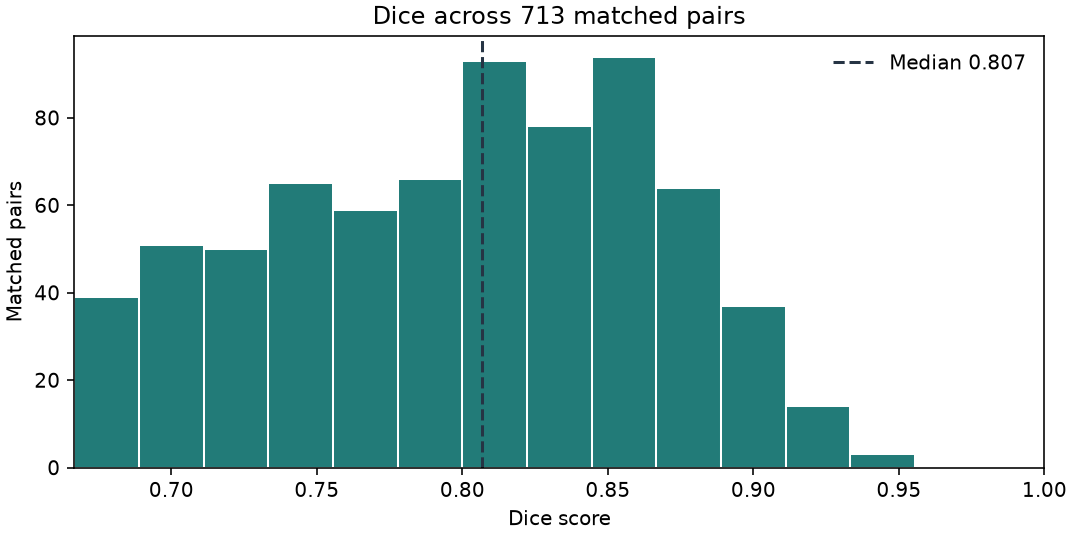

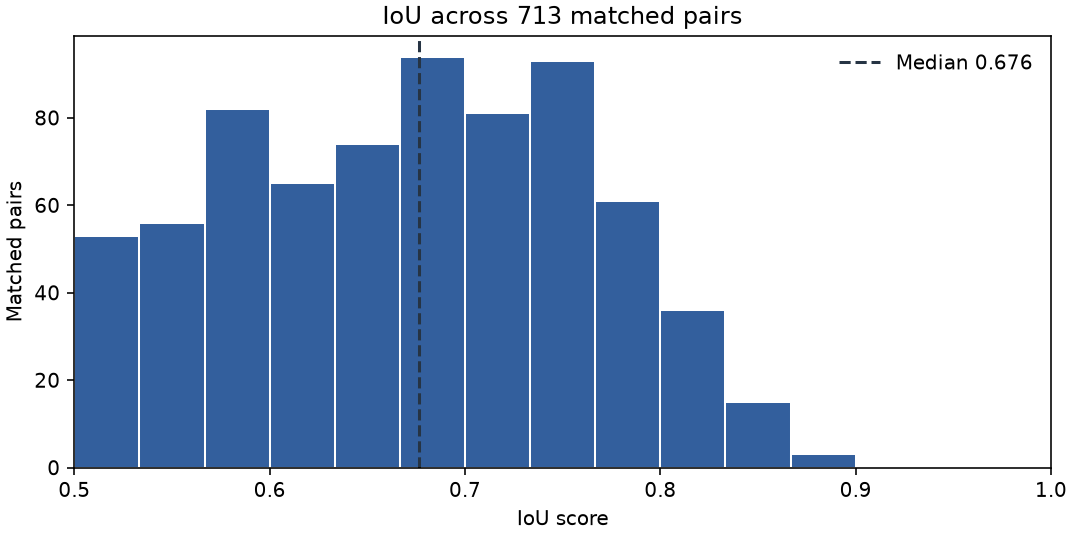

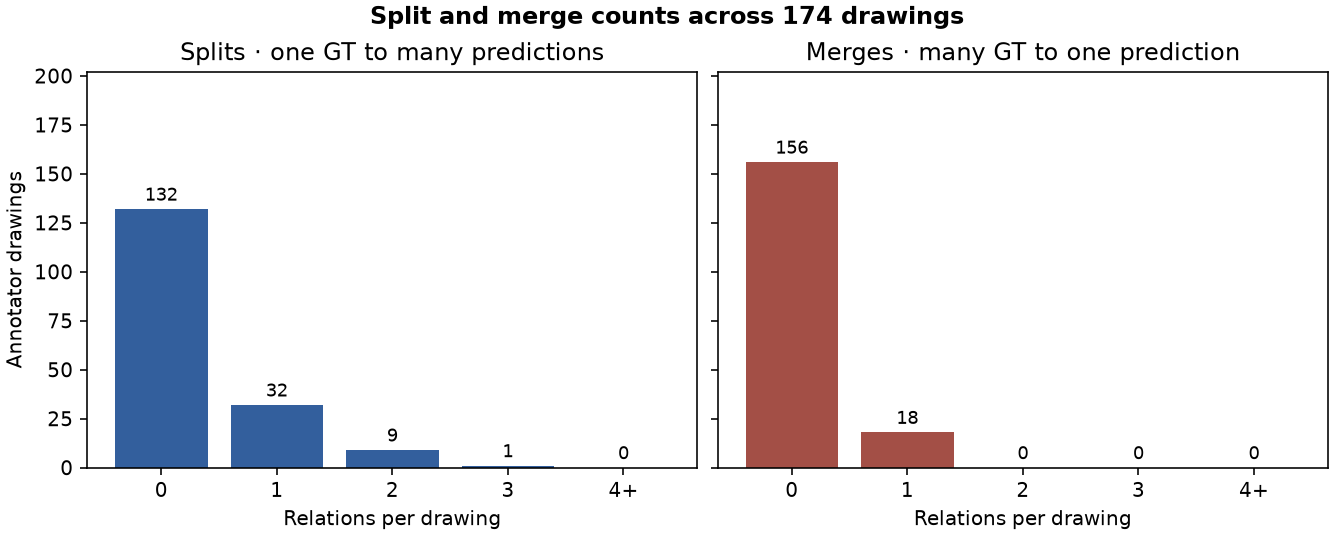

In [ ]:
if RUN_VALIDATION_ANALYSIS and RUN_FRACTION > 0:
    from IPython.display import Image, display
    import pandas as pd

    display(pd.DataFrame([validation_summary]))
    for plot in ("dice_distribution.png", "iou_distribution.png", "split_merge_distribution.png"):
        display(Image(filename=str(validation_out / plot)))

## Optional test submission

When enabled, the notebook runs inference on the unlabeled test frames and writes and validates the competition RLE CSV.

In [ ]:
if WRITE_TEST_SUBMISSION and RUN_FRACTION > 0:
    if INFERENCE_ONLY:
        if RUN_FRACTION == 1:
            SUBMISSION_PATH = OUTPUT_ROOT / "submission.csv"
        else:
            subset = f"fraction_{str(RUN_FRACTION).replace('.', 'p')}_seed{RUN_SEED}"
            SUBMISSION_PATH = OUTPUT_ROOT / "runs" / f"inference_{subset}" / "submission.csv"
        INFERENCE_SETTINGS = POSTPROCESS
    else:
        INFERENCE_SETTINGS = RUN_DIR / "best_postprocess.json" if PROPOSAL_WEIGHTS is None else None

    predict.main([
        "--checkpoint", str(CHECKPOINT),
        *(["--proposal-preset", str(PROPOSAL_WEIGHTS)] if PROPOSAL_WEIGHTS is not None else []),
        *(["--postprocess", str(INFERENCE_SETTINGS)] if INFERENCE_SETTINGS is not None else []),
        "--out", str(SUBMISSION_PATH),
        *FRACTION_ARGS,
    ])
else:
    print("Test submission skipped.")

## Optional training diagnostics

The training path reports proposal confirmation metrics or full-frame standard inference scores, tile coverage and ranked error galleries.

In [ ]:
if RUN_FULL_PIPELINE:
    if PROPOSAL_PRESET is not None:
        report = json.loads((PROPOSAL_DIR / "proposal_confirmation.json").read_text())
        display(pd.DataFrame({name: values["overall"] for name, values in report["metrics"].items()}))
    elif run_split["val"]:
        diagnostics = RUN_DIR / "diagnostics"
        summary = json.loads((diagnostics / "pixel_metrics.json").read_text())
        display(pd.DataFrame({"pooled_pixels": summary["pixel_micro"],
                              "mean_image": summary["pixel_macro"]}).loc[
                                  ["iou", "precision", "recall", "false_positive_rate"]])
        print("Ground-truth pixels covered by component-selected tiles:", f"{summary['selection_recall']:.2%}")
        display(pd.DataFrame([json.loads((RUN_DIR / "instance_metrics.json").read_text())]))
        image_metrics = pd.read_csv(diagnostics / "per_image_metrics.csv")
        print("Lowest final IoU (all annotators):")
        display(image_metrics.sort_values(["iou", "file_name"]).head(10))
        print("Most false-positive pixels:")
        display(image_metrics.sort_values("fp", ascending=False).head(10))
        # Remove stale gallery paths from consideration by consulting this run's manifest.
        groups = json.loads((diagnostics / "ranked_examples.json").read_text())
        display(Image(filename=str(diagnostics / "validation_summary.png")))
        for group in ("best", "average", "worst"):
            if groups[group]:
                print(group, groups[group])
                display(Image(filename=str(diagnostics / f"{group}_predictions.png")))
                display(Image(filename=str(diagnostics / f"{group}_details.png")))
    else:
        print("Diagnostics skipped: no validation data selected.")